# Exploratory Data Analysis: NBA Draft Combine

**Author:** Rasheed Martin

This notebook provides a comprehensive exploratory analysis of the NBA Draft Combine dataset, focusing on uncovering key relationships between physical measurements, combine performance, and NBA career outcomes. The workflow includes:

- **Data Extraction & Cleaning:** Loading combine stats, NBA performance metrics, and award information for thousands of players and seasons.
- **Univariate & Bivariate Analysis:** Summarizing distributions, missingness, and correlations among physical and performance features.
- **Visualization:** Using barplots, heatmaps, pairplots, and boxplots to reveal trends by position, season, and award status.
- **Key Insights:** Identifying which combine metrics are most predictive of NBA success, and how standout physical traits relate to accolades such as All-Star, All-NBA, and Defensive Team selections.

This analysis supports downstream modeling and provides actionable insights for scouting, player development, and understanding the impact of draft combine results on NBA careers.

### Required Imports

This notebook uses the following libraries for data analysis and visualization:

- **duckdb**: Efficient SQL querying and database connection.
- **polars**: Fast DataFrame operations for data manipulation.
- **pathlib**: File and directory path management.
- **matplotlib.pyplot**: Plotting and visualization.
- **seaborn**: Advanced statistical visualizations.
- **numpy**: Numerical computations and array operations.
- **IPython.display**: Enhanced display of dataframes and outputs.
- **scipy.stats**: Statistical analysis and probability plots.

These imports enable efficient data extraction, transformation, and visualization throughout the NBA Draft Combine exploratory analysis workflow.

In [18]:
import duckdb
import polars as pl
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from IPython.display import display
from scipy.stats import probplot



In [19]:
# Set Visualization Path
visualization_path = Path.cwd().parent.parent / "visualizations/draft_combine/exploratory_analysis"
visualization_path.mkdir(parents=True, exist_ok=True)

### Connect to the Database

To begin our analysis, we establish a connection to the NBA Draft Combine database using DuckDB. This enables efficient querying and data extraction for subsequent exploration.

**Workflow:**
- Use the `get_duckdb_connection()` function to connect to the database.
- Verify the connection by running a simple query (e.g., list players born in 1990).
- If the query returns expected results, the setup is complete and ready for further analysis.

This step ensures our data pipeline is working and that we can reliably access the NBA Draft Combine data for all downstream tasks.

In [20]:
def get_duckdb_connection(db_path=None, read_only=True):
    if db_path is None:
        db_path = Path.cwd().parent.parent / "data/refined_raw_data/nba_data.duckdb"
    
    if not db_path.exists():
        raise FileNotFoundError(f"DuckDB database not found at {db_path}")
    print(f"Connected to: {db_path.resolve()}")
    return duckdb.connect(db_path, read_only=read_only)

## Test the Database Connection

To verify our connection to the NBA Draft Combine database, we run a simple query that lists all players born in 1990. This quick test ensures the database is accessible and that queries return expected results before proceeding with deeper analysis.

**Example Output:**
- Paul George
- Gordon Hayward
- Hassan Whiteside
- ...

If the query executes successfully and returns player names, our connection setup is complete and ready for further data exploration.

In [21]:
with get_duckdb_connection() as con:
    try:
        result = con.execute("SELECT p.name from main.players p where birth_year=1990;").fetchall()
        for row in result:
            print("-", row[0])
    except Exception as e:
        print("Failed to connect or query:", e)

Connected to: /Users/rashe/PycharmProjects/PredictingNBACareers/data/refined_raw_data/nba_data.duckdb
- Travis Wear
- John Henson
- Al-Farouq Aminu
- Mason Plumlee
- Damian Lillard
- Sean Kilpatrick
- Ricky Rubio
- JaMychal Green
- Marshall Plumlee
- Reggie Jackson
- Nikola Vucevic
- Jeff Withey
- John Wall
- Draymond Green
- Tyler Zeller
- Tim Frazier
- Lorenzo Brown
- Gorgui Dieng
- Jae Crowder
- Avery Bradley
- Darius Miller
- Paul George
- Kyle O'Quinn
- Jrue Holiday
- Greg Monroe
- Gordon Hayward
- Quincy Acy
- Robert Covington
- DeMarcus Cousins
- Klay Thompson
- Lance Stephenson
- Matthew Dellavedova
- Iman Shumpert
- Shelvin Mack
- Erik Murphy
- Henry Sims
- Jan Vesely
- Seth Curry
- James Southerland
- Tyshawn Taylor
- Ognjen Kuzmic
- Arnett Moultrie
- James Nunnally
- Donatas Motiejunas
- Carrick Felix
- Chris Babb
- Justin Hamilton
- Daniel Orton
- Peyton Siva
- Casper Ware
- Scott Machado
- Travis Leslie
- Malcolm Lee
- Tyler Honeycutt
- Kostas Papanikolaou
- Cory Jefferson

### Exploring Data

Let's begin our exploration by loading the NBA Draft Combine data. Key columns include player name, season, stat name, and stat value—these form the foundation for our analysis. By focusing on these attributes, we can investigate trends in player performance, physical measurements, and how these metrics relate to NBA outcomes.

We'll start by querying and displaying the combine dataset, then progressively transform and analyze the data to uncover meaningful insights. This workflow will help us understand the distribution of combine stats, identify missing values, and prepare the data for deeper statistical analysis and visualization.

In [22]:
query = """
SELECT p.name as Player, s.label as Season, st.name as Stat, csv.value as Value, csv.player_id as Id, po.name as Position
FROM nba_data.main.combine_stat_values csv
JOIN players p ON csv.player_id = p.player_id
FULL OUTER JOIN player_positions pp ON pp.player_id = p.player_id
FULL OUTER JOIN positions po on po.position_id = pp.position_id
JOIN seasons s ON csv.season_id = s.season_id
JOIN stats st on csv.stat_id = st.stat_id
"""
with get_duckdb_connection() as con:
    df_combine = pl.from_arrow(con.execute(query).arrow())
    display(df_combine.head())

Connected to: /Users/rashe/PycharmProjects/PredictingNBACareers/data/refined_raw_data/nba_data.duckdb


Player,Season,Stat,Value,Id,Position
str,str,str,f32,i32,str
"""Eric Gordon""","""2008-09""","""Height""",74.0,412,"""SF"""
"""Udonis Haslem""","""2002-03""","""Lane_Agility_Time""",11.8,233,"""PF"""
"""Zeke Nnaji""","""2020-21""","""Length_x_Width_Hand""",94.5,1837,"""PF"""
"""Andrew Goudelock""","""2011-12""","""Lane_Agility_Time""",10.33,1657,"""PG"""
"""Cleanthony Early""","""2014-15""","""Weight""",209.399994,1735,"""SF"""


### Transforming Data: Pivoting from Long to Wide Format

To facilitate analysis and visualization, we convert the combine dataset from long format (where each row is a single stat for a player-season) to wide format (where each row contains all stats for a player-season). This is accomplished using a pivot table, which spreads each statistic into its own column. The resulting wide dataframe allows for easier computation of correlations, summary statistics, and advanced visualizations across all combine metrics.

In [23]:
# Group by all columns except position, and join the positions
df_combine = df_combine.group_by(
    ['Id', 'Player', 'Season', 'Value', 'Stat'],  # all other columns
).agg(pl.col("Position").unique().sort().alias("Position"))

df_combine = df_combine.with_columns(
    pl.col("Position").list.join("/")
)
df_combine.height

30204

In [24]:
df_wide_view: pl.DataFrame = df_combine.pivot(
    values="Value",
    index=["Position", "Player", "Season"],
    on="Stat"
)
df_wide_view.head()

Position,Player,Season,Wingspan,3_Quarter_Sprint,Height,Length_x_Width_Hand,Weight,Max_Bench_Press,Max_Vertical_Leap,Ration_of_Wingspan,Width_of_Hand,Body_Fat,Bmi,Shuttle_Run,Standing_Reach_Vertical,Standing_Reach_Max_Vertical,Standing_Vertical,Standing_Reach,Lane_Agility_Time,Length_of_Hand
str,str,str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""SG""","""Grayson Allen""","""2018-19""",79.25,3.15,75.0,82.5,198.0,null,40.5,1.057,10.0,0.056,24.700001,3.04,129.5,137.5,32.5,97.0,10.31,8.25
"""""","""Eric Coley""","""2000-01""",83.0,3.15,76.0,null,205.0,10.0,38.0,1.092,null,null,25.0,null,137.0,140.0,35.0,102.0,11.4,null
"""PG""","""Reed Sheppard""","""2024-25""",75.300003,3.08,73.800003,69.800003,181.600006,null,42.0,1.02,9.0,null,23.5,3.03,126.0,135.5,32.5,93.5,10.96,7.75
"""SF""","""Austin Daye""","""2009-10""",86.75,3.55,81.75,null,191.800003,0.0,28.0,1.061,null,0.055,20.200001,null,135.0,138.0,25.0,110.0,12.11,null
"""SG""","""John Jenkins""","""2012-13""",80.5,3.37,75.25,81.0,212.0,10.0,36.5,1.07,9.0,0.071,26.299999,null,128.5,134.5,30.5,98.0,11.36,9.0


### Season Distribution Across Records

In the following section, we examine how player records are distributed across NBA Draft Combine seasons. Understanding the representation per season helps identify trends in combine participation, data completeness, and shifts in player profiles over time. We will visualize the number of player records for each season and discuss notable patterns or anomalies in the dataset.

In [25]:
len(df_wide_view["Player"].unique())

1677

In [26]:
df_wide_view.height

1678

To explain why there is an extra player. PJ Washington actually attended both combines. Once in 2018 and once in 2019. Cool fun fact :) He did get drafted in 2019 so we can keep it or drop it. I decided to keep it as we are recording Draft Combine Performance and since the record contains two different seasons it is fine for now. 

In [27]:
df_wide_view.filter(df_wide_view["Player"].is_duplicated())

Position,Player,Season,Wingspan,3_Quarter_Sprint,Height,Length_x_Width_Hand,Weight,Max_Bench_Press,Max_Vertical_Leap,Ration_of_Wingspan,Width_of_Hand,Body_Fat,Bmi,Shuttle_Run,Standing_Reach_Vertical,Standing_Reach_Max_Vertical,Standing_Vertical,Standing_Reach,Lane_Agility_Time,Length_of_Hand
str,str,str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""PF""","""PJ Washington""","""2019-20""",86.25,null,78.5,92.300003,230.399994,null,null,1.099,10.3,0.086,26.299999,null,null,null,null,106.5,null,9.0
"""PF""","""PJ Washington""","""2018-19""",86.5,3.2,78.5,92.300003,223.0,3.0,34.0,1.102,10.3,0.069,25.4,3.43,134.0,141.0,27.0,107.0,11.39,9.0


Only 1677 NBA players in this dataset. We can assume that many NBA players are not represented. Let's view the distribution of records across seasons.

In [28]:
df_wide_view.null_count()

Position,Player,Season,Wingspan,3_Quarter_Sprint,Height,Length_x_Width_Hand,Weight,Max_Bench_Press,Max_Vertical_Leap,Ration_of_Wingspan,Width_of_Hand,Body_Fat,Bmi,Shuttle_Run,Standing_Reach_Vertical,Standing_Reach_Max_Vertical,Standing_Vertical,Standing_Reach,Lane_Agility_Time,Length_of_Hand
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,3,197,4,733,5,604,189,4,733,441,5,1061,190,190,189,5,198,733


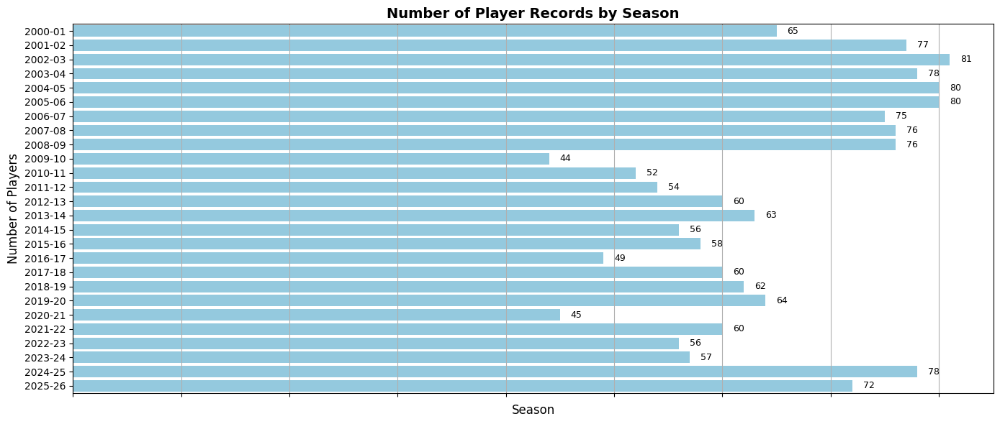

In [29]:
plt.figure(figsize=(14, 6))
ax = sns.countplot(df_wide_view["Season"], color="skyblue", order=sorted(df_wide_view["Season"].unique()))
# Add value labels on top of bars
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{int(width)}",  # label
                (width + 1, p.get_y() + p.get_height() / 2),  # position
                ha='left', va='center', fontsize=9)

# Showing the distribution across seasons
plt.title("Number of Player Records by Season", fontsize=14, weight='bold')
plt.ylabel("Number of Players", fontsize=12)
plt.xlabel("Season", fontsize=12)
ax.yaxis.grid(False)
ax.xaxis.grid(False)
ax.set_xticklabels([])
plt.grid(axis="x")
plt.tight_layout()
plt.savefig(visualization_path / "Season_Distribution_countplot.png")
plt.show()

As we can see from above, the number of records per season is not linear. It was above 70 before 2009 and there has been variance ever since. Maybe it is the quality of the data. 

Let's create a line graph to see the trend of records and participation in the NBA Draft Combine

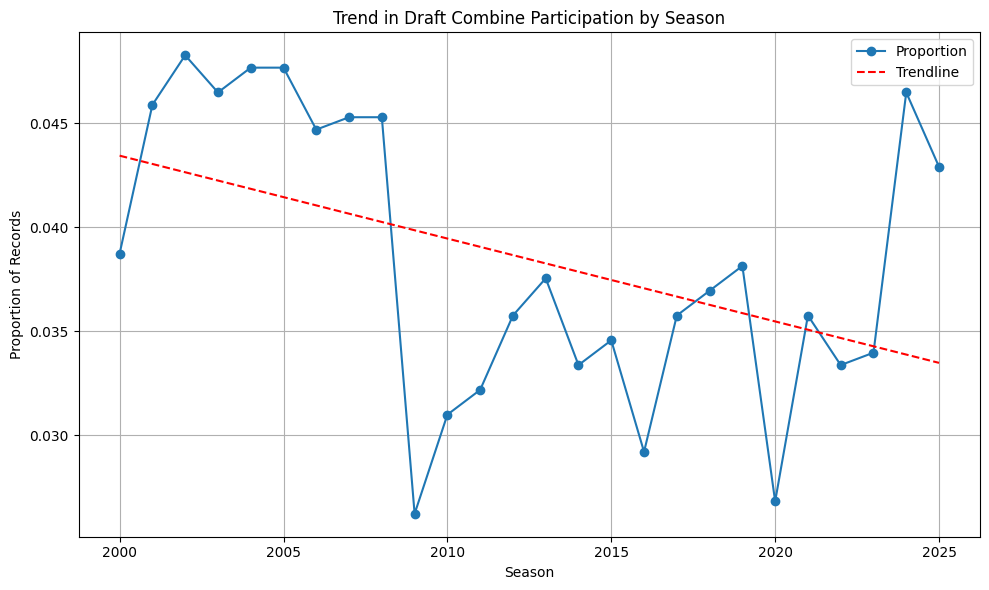

In [30]:
# 1. Get number of total records
total_seasons = len(df_wide_view)

# 2. Compute relative frequency or counts by season (As a record counts as attendance)
avg_attendance = (
    df_wide_view
    .group_by("Season")
    .agg((pl.len() / total_seasons).alias("Proportion"))
    .sort("Season")
)

# 3. Convert season to numeric for trendline
seasons_str = avg_attendance["Season"].to_list()
try:
    seasons = [int(s[:4]) for s in seasons_str]  # Because format "2003-04"
except:
    seasons = list(range(len(seasons_str)))      # fallback

values = avg_attendance["Proportion"].to_list()

# 4. Fit linear regression
coeffs = np.polyfit(seasons, values, 1)
trend = np.poly1d(coeffs)

# 5. Plot
plt.figure(figsize=(10, 6))
plt.plot(seasons, values, marker='o', label="Proportion")
plt.plot(seasons, trend(seasons), linestyle="--", color="red", label="Trendline")

plt.title("Trend in Draft Combine Participation by Season")
plt.xlabel("Season")
plt.ylabel("Proportion of Records")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(visualization_path / "Season_Distribution_lineplot.png")
plt.show()


Okay so on average not many people attend the combine but lets see if we can find some insights. We continue to explore the data.

In [31]:
df_wide_view.null_count()

Position,Player,Season,Wingspan,3_Quarter_Sprint,Height,Length_x_Width_Hand,Weight,Max_Bench_Press,Max_Vertical_Leap,Ration_of_Wingspan,Width_of_Hand,Body_Fat,Bmi,Shuttle_Run,Standing_Reach_Vertical,Standing_Reach_Max_Vertical,Standing_Vertical,Standing_Reach,Lane_Agility_Time,Length_of_Hand
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,3,197,4,733,5,604,189,4,733,441,5,1061,190,190,189,5,198,733


Now I want to view the summary of stats across the numerical features.

In [32]:
df_wide_view.select(pl.exclude(["Id", "Position", "Season", "Player"])).describe()

statistic,Wingspan,3_Quarter_Sprint,Height,Length_x_Width_Hand,Weight,Max_Bench_Press,Max_Vertical_Leap,Ration_of_Wingspan,Width_of_Hand,Body_Fat,Bmi,Shuttle_Run,Standing_Reach_Vertical,Standing_Reach_Max_Vertical,Standing_Vertical,Standing_Reach,Lane_Agility_Time,Length_of_Hand
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1675.0,1481.0,1674.0,945.0,1673.0,1074.0,1489.0,1674.0,945.0,1237.0,1673.0,617.0,1488.0,1488.0,1489.0,1673.0,1480.0,945.0
"""null_count""",3.0,197.0,4.0,733.0,5.0,604.0,189.0,4.0,733.0,441.0,5.0,1061.0,190.0,190.0,189.0,5.0,198.0,733.0
"""mean""",82.377792,3.266097,77.656448,82.479263,214.953674,10.354749,34.561787,1.060891,9.453016,0.075306,25.003109,3.060519,132.6465,137.983337,29.23358,103.523911,11.394094,8.7291
"""std""",3.991217,0.145154,3.352874,9.324908,26.53393,5.556441,3.687227,0.028591,0.694404,0.029386,2.089067,0.237889,4.733643,4.531623,3.099428,4.849736,0.582157,0.472243
"""min""",70.0,2.91,67.75,52.5,0.0,0.0,21.0,0.977,7.0,0.026,0.0,0.0,117.0,121.5,19.5,88.5,9.65,7.5
"""25%""",79.75,3.18,75.5,76.5,196.199997,6.0,32.0,1.041,9.0,0.054,23.700001,2.98,129.5,135.5,27.0,100.0,11.0,8.5
"""50%""",82.5,3.26,78.0,81.0,213.0,10.0,34.5,1.061,9.5,0.067,24.9,3.06,133.0,138.5,29.0,104.0,11.32,8.75
"""75%""",85.25,3.35,80.25,87.900002,232.800003,14.0,37.0,1.08,10.0,0.089,26.200001,3.19,136.0,141.0,31.5,107.0,11.72,9.0
"""max""",98.25,4.0,89.25,117.0,334.0,27.0,48.0,1.177,12.0,0.231,34.5,3.76,146.0,150.5,41.5,122.5,14.45,10.5


## Univariate Analysis

We will do univariate analysis to learn about the individual features and see if we could draw any insights

In [110]:
def univariate_eda(df: pl.DataFrame, columns=None, bins=30):
    """
    Perform univariate analysis on specified numerical columns.
    If columns is None, all numeric columns will be analyzed.
    """
    if columns is None:
        columns = df.select(pl.exclude(pl.String)).columns

    for col in columns:
        print(f"\n--- {col} ---")
        print(df[col].describe())
        print(f"Skewness: {df[col].skew():.2f}")
        print(f"Kurtosis: {df[col].kurtosis():.2f}")
        
        fig, axes = plt.subplots(1, 3, figsize=(18, 4))

        # Histogram + KDE
        sns.histplot(df[col], bins=bins, kde=True, ax=axes[0], color='skyblue')
        axes[0].set_title(f"{col} Distribution")

        # Boxplot
        sns.boxplot(x=df[col], ax=axes[1], color='salmon')
        axes[1].set_title(f"{col} Boxplot")

        # QQ Plot for normality check
        
        probplot(df[col].drop_nulls(), dist="norm", plot=axes[2])
        axes[2].set_title(f"{col} QQ Plot")

        plt.tight_layout()
        temp = visualization_path / f"univariate"
        temp.mkdir(parents=True, exist_ok=True)
        plt.savefig(temp / f"Univariate_{col}.png")
        plt.show()




--- Wingspan ---
shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 1675.0    │
│ null_count ┆ 3.0       │
│ mean       ┆ 82.377792 │
│ std        ┆ 3.991217  │
│ min        ┆ 70.0      │
│ 25%        ┆ 79.75     │
│ 50%        ┆ 82.5      │
│ 75%        ┆ 85.25     │
│ max        ┆ 98.25     │
└────────────┴───────────┘
Skewness: -0.19
Kurtosis: -0.08


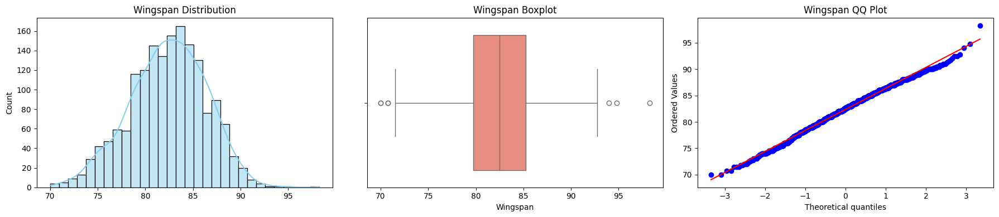


--- 3_Quarter_Sprint ---
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 1481.0   │
│ null_count ┆ 197.0    │
│ mean       ┆ 3.266097 │
│ std        ┆ 0.145154 │
│ min        ┆ 2.91     │
│ 25%        ┆ 3.18     │
│ 50%        ┆ 3.26     │
│ 75%        ┆ 3.35     │
│ max        ┆ 4.0      │
└────────────┴──────────┘
Skewness: 0.50
Kurtosis: 0.90


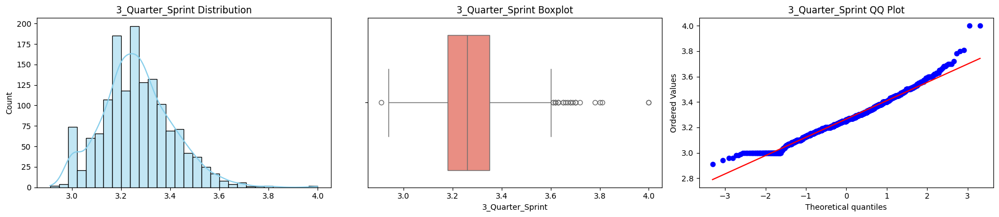


--- Height ---
shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 1674.0    │
│ null_count ┆ 4.0       │
│ mean       ┆ 77.656448 │
│ std        ┆ 3.352874  │
│ min        ┆ 67.75     │
│ 25%        ┆ 75.5      │
│ 50%        ┆ 78.0      │
│ 75%        ┆ 80.25     │
│ max        ┆ 89.25     │
└────────────┴───────────┘
Skewness: -0.19
Kurtosis: -0.27


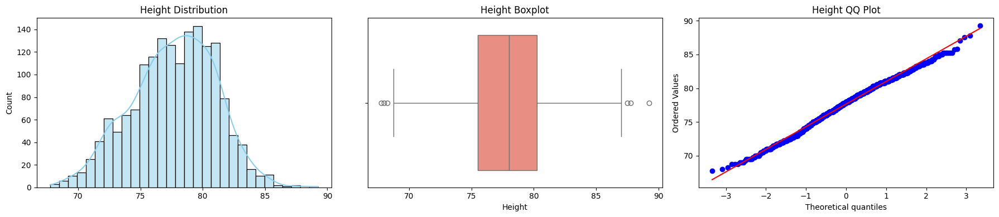


--- Length_x_Width_Hand ---
shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 945.0     │
│ null_count ┆ 733.0     │
│ mean       ┆ 82.479263 │
│ std        ┆ 9.324908  │
│ min        ┆ 52.5      │
│ 25%        ┆ 76.5      │
│ 50%        ┆ 81.0      │
│ 75%        ┆ 87.900002 │
│ max        ┆ 117.0     │
└────────────┴───────────┘
Skewness: 0.40
Kurtosis: 0.40


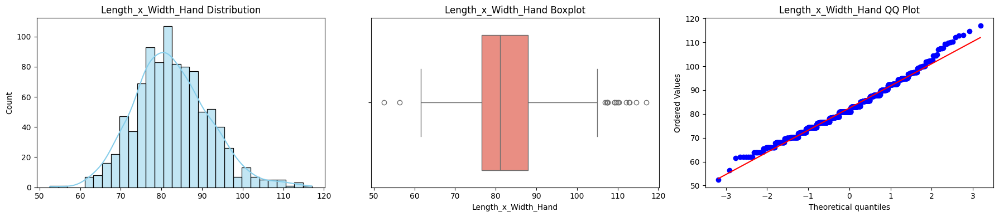


--- Weight ---
shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 1673.0     │
│ null_count ┆ 5.0        │
│ mean       ┆ 214.953674 │
│ std        ┆ 26.53393   │
│ min        ┆ 0.0        │
│ 25%        ┆ 196.199997 │
│ 50%        ┆ 213.0      │
│ 75%        ┆ 232.800003 │
│ max        ┆ 334.0      │
└────────────┴────────────┘
Skewness: 0.11
Kurtosis: 2.60


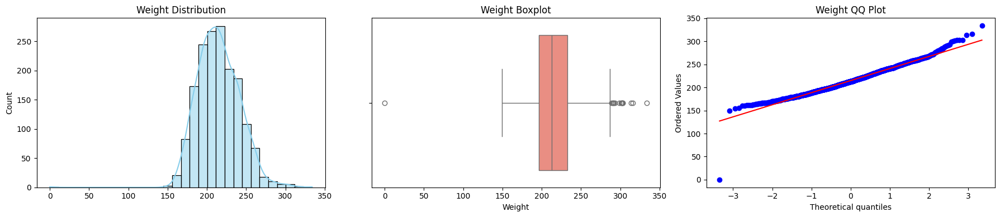


--- Max_Bench_Press ---
shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 1074.0    │
│ null_count ┆ 604.0     │
│ mean       ┆ 10.354749 │
│ std        ┆ 5.556441  │
│ min        ┆ 0.0       │
│ 25%        ┆ 6.0       │
│ 50%        ┆ 10.0      │
│ 75%        ┆ 14.0      │
│ max        ┆ 27.0      │
└────────────┴───────────┘
Skewness: 0.15
Kurtosis: -0.34


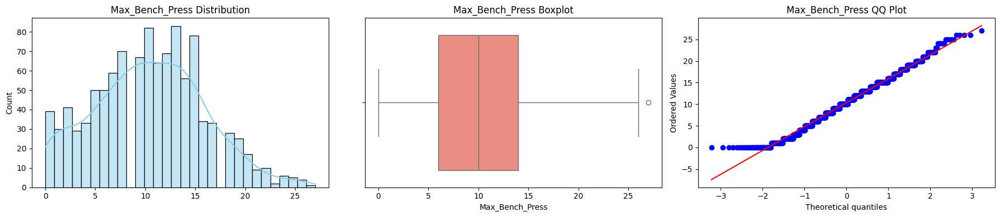


--- Max_Vertical_Leap ---
shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 1489.0    │
│ null_count ┆ 189.0     │
│ mean       ┆ 34.561787 │
│ std        ┆ 3.687227  │
│ min        ┆ 21.0      │
│ 25%        ┆ 32.0      │
│ 50%        ┆ 34.5      │
│ 75%        ┆ 37.0      │
│ max        ┆ 48.0      │
└────────────┴───────────┘
Skewness: 0.04
Kurtosis: -0.09


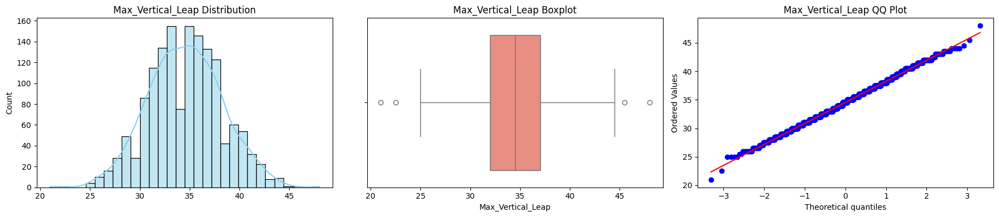


--- Ration_of_Wingspan ---
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 1674.0   │
│ null_count ┆ 4.0      │
│ mean       ┆ 1.060891 │
│ std        ┆ 0.028591 │
│ min        ┆ 0.977    │
│ 25%        ┆ 1.041    │
│ 50%        ┆ 1.061    │
│ 75%        ┆ 1.08     │
│ max        ┆ 1.177    │
└────────────┴──────────┘
Skewness: -0.03
Kurtosis: -0.24


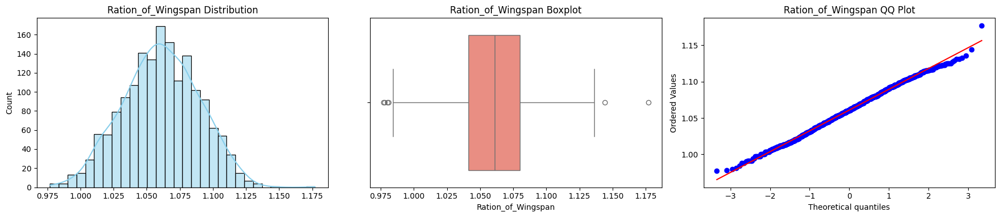


--- Width_of_Hand ---
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 945.0    │
│ null_count ┆ 733.0    │
│ mean       ┆ 9.453016 │
│ std        ┆ 0.694404 │
│ min        ┆ 7.0      │
│ 25%        ┆ 9.0      │
│ 50%        ┆ 9.5      │
│ 75%        ┆ 10.0     │
│ max        ┆ 12.0     │
└────────────┴──────────┘
Skewness: 0.13
Kurtosis: 0.29


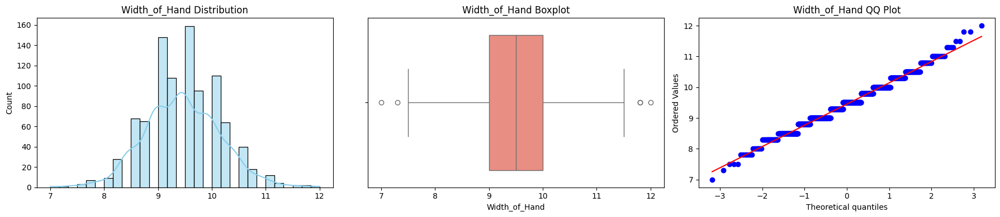


--- Body_Fat ---
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 1237.0   │
│ null_count ┆ 441.0    │
│ mean       ┆ 0.075306 │
│ std        ┆ 0.029386 │
│ min        ┆ 0.026    │
│ 25%        ┆ 0.054    │
│ 50%        ┆ 0.067    │
│ 75%        ┆ 0.089    │
│ max        ┆ 0.231    │
└────────────┴──────────┘
Skewness: 1.38
Kurtosis: 2.42


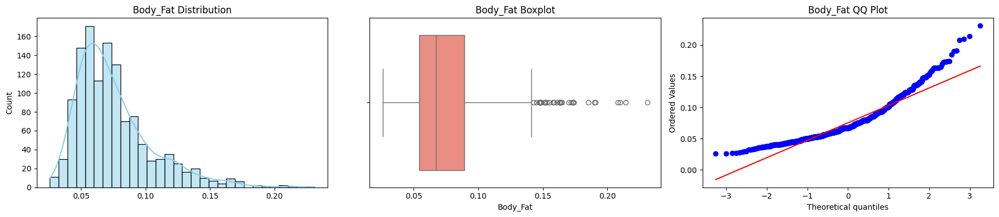


--- Bmi ---
shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 1673.0    │
│ null_count ┆ 5.0       │
│ mean       ┆ 25.003109 │
│ std        ┆ 2.089067  │
│ min        ┆ 0.0       │
│ 25%        ┆ 23.700001 │
│ 50%        ┆ 24.9      │
│ 75%        ┆ 26.200001 │
│ max        ┆ 34.5      │
└────────────┴───────────┘
Skewness: -0.50
Kurtosis: 12.79


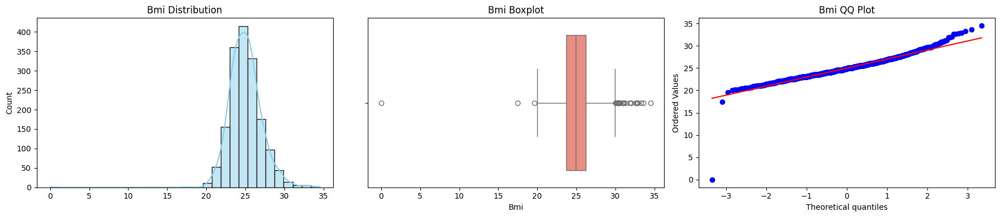


--- Shuttle_Run ---
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 617.0    │
│ null_count ┆ 1061.0   │
│ mean       ┆ 3.060519 │
│ std        ┆ 0.237889 │
│ min        ┆ 0.0      │
│ 25%        ┆ 2.98     │
│ 50%        ┆ 3.06     │
│ 75%        ┆ 3.19     │
│ max        ┆ 3.76     │
└────────────┴──────────┘
Skewness: -3.70
Kurtosis: 44.05


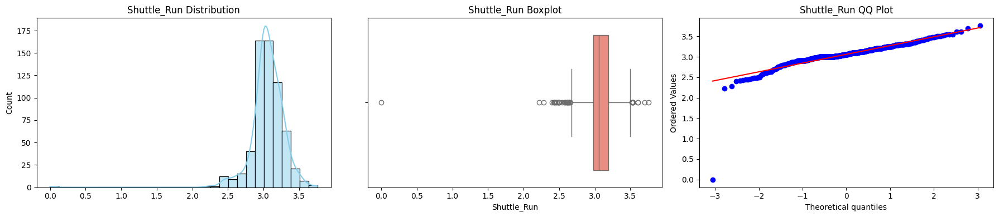


--- Standing_Reach_Vertical ---
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 1488.0   │
│ null_count ┆ 190.0    │
│ mean       ┆ 132.6465 │
│ std        ┆ 4.733643 │
│ min        ┆ 117.0    │
│ 25%        ┆ 129.5    │
│ 50%        ┆ 133.0    │
│ 75%        ┆ 136.0    │
│ max        ┆ 146.0    │
└────────────┴──────────┘
Skewness: -0.34
Kurtosis: 0.00


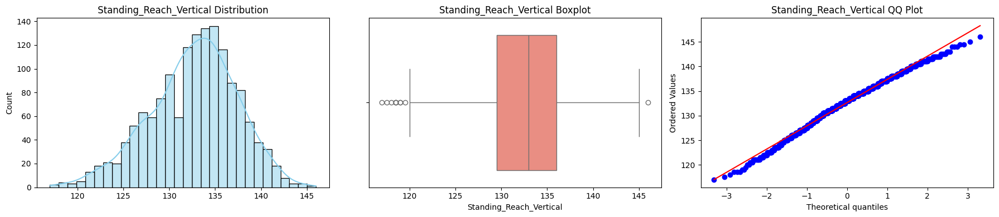


--- Standing_Reach_Max_Vertical ---
shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 1488.0     │
│ null_count ┆ 190.0      │
│ mean       ┆ 137.983337 │
│ std        ┆ 4.531623   │
│ min        ┆ 121.5      │
│ 25%        ┆ 135.5      │
│ 50%        ┆ 138.5      │
│ 75%        ┆ 141.0      │
│ max        ┆ 150.5      │
└────────────┴────────────┘
Skewness: -0.47
Kurtosis: 0.38


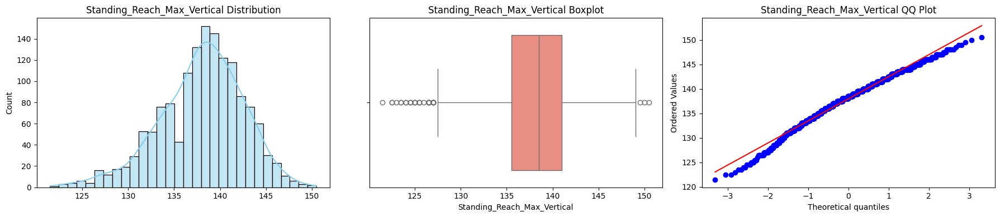


--- Standing_Vertical ---
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 1489.0   │
│ null_count ┆ 189.0    │
│ mean       ┆ 29.23358 │
│ std        ┆ 3.099428 │
│ min        ┆ 19.5     │
│ 25%        ┆ 27.0     │
│ 50%        ┆ 29.0     │
│ 75%        ┆ 31.5     │
│ max        ┆ 41.5     │
└────────────┴──────────┘
Skewness: 0.11
Kurtosis: 0.04


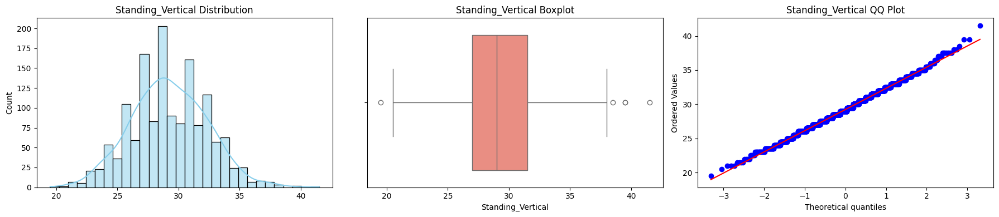


--- Standing_Reach ---
shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 1673.0     │
│ null_count ┆ 5.0        │
│ mean       ┆ 103.523911 │
│ std        ┆ 4.849736   │
│ min        ┆ 88.5       │
│ 25%        ┆ 100.0      │
│ 50%        ┆ 104.0      │
│ 75%        ┆ 107.0      │
│ max        ┆ 122.5      │
└────────────┴────────────┘
Skewness: -0.20
Kurtosis: -0.28


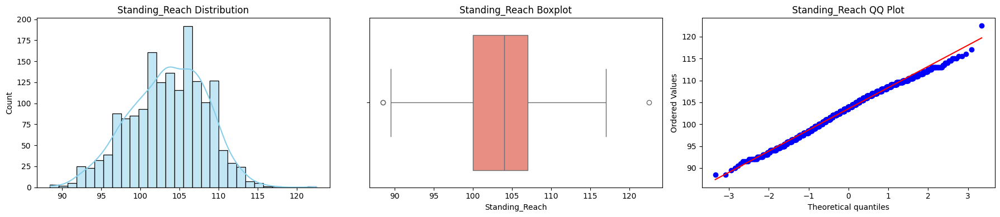


--- Lane_Agility_Time ---
shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 1480.0    │
│ null_count ┆ 198.0     │
│ mean       ┆ 11.394094 │
│ std        ┆ 0.582157  │
│ min        ┆ 9.65      │
│ 25%        ┆ 11.0      │
│ 50%        ┆ 11.32     │
│ 75%        ┆ 11.72     │
│ max        ┆ 14.45     │
└────────────┴───────────┘
Skewness: 0.81
Kurtosis: 1.30


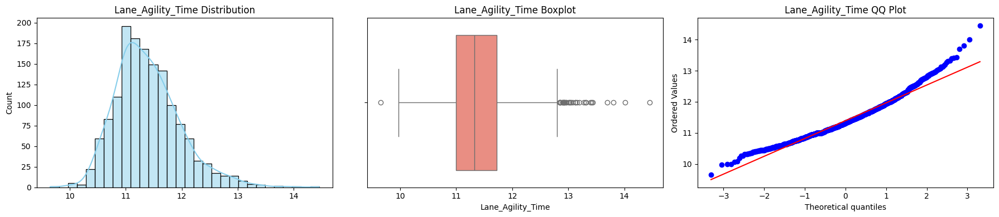


--- Length_of_Hand ---
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 945.0    │
│ null_count ┆ 733.0    │
│ mean       ┆ 8.7291   │
│ std        ┆ 0.472243 │
│ min        ┆ 7.5      │
│ 25%        ┆ 8.5      │
│ 50%        ┆ 8.75     │
│ 75%        ┆ 9.0      │
│ max        ┆ 10.5     │
└────────────┴──────────┘
Skewness: 0.16
Kurtosis: 0.16


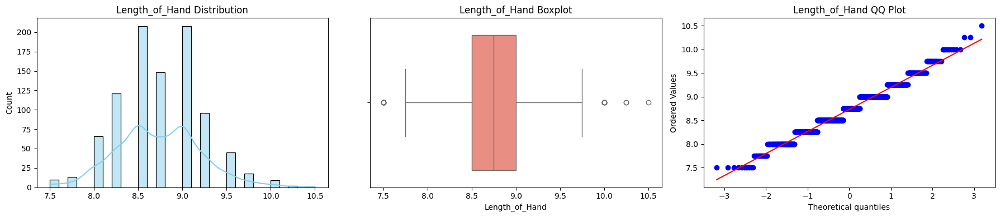

In [111]:
univariate_eda(df_wide_view)

## Univariate EDA Summary

The univariate analysis of this dataset reveals generally clean and well-behaved features, with a few exceptions that merit closer inspection. Most variables have low missingness; however, several require attention due to significant null values. Specifically, `Shuttle_Run` (63% missing), `Length_x_Width_Hand`, `Length_of_Hand`, `Width_of_Hand` (each ~44% missing), and `Max_Bench_Press` (~36% missing) may need imputation or exclusion depending on our analysis goals. `Body_Fat` also shows moderate missingness (~26%).

Many variables display near-normal distributions, including `Standing_Vertical`, `Max_Vertical_Leap`, `Wingspan`, `Height`, `Standing_Reach`, and `Standing_Reach_Vertical`, with skewness and kurtosis values close to zero. Mild right-skew is observed in `Lane_Agility_Time`, `3_Quarter_Sprint`, and `Length_x_Width_Hand`, while `Bmi`, `Standing_Reach_Max_Vertical`, and especially `Shuttle_Run` are left-skewed. `Shuttle_Run` in particular exhibits extreme skewness (−3.70) and kurtosis (44.05), indicating outliers or a long tail. Likewise, `Bmi` shows high kurtosis (12.79), suggesting sharp peaks and heavier tails.

Potential data quality issues are evident in variables like `Bmi`, `Weight`, and `Shuttle_Run`, where minimum values of 0 likely reflect errors or invalid entries. Central tendency metrics are reasonable across most variables, with means and medians closely aligned. For example, `Wingspan` (mean ≈ 82.4 in) and `Height` (mean ≈ 77.7 in) suggest consistent body proportions, further reinforced by the `Ratio_of_Wingspan` (mean ≈ 1.06). Vertical leap metrics (`Standing_Vertical` and `Max_Vertical_Leap`) average 29 and 34.5 inches respectively—values that align with athletic expectations.

Body composition variables highlight a lean cohort, with `Body_Fat` averaging ~7.5% but exhibiting strong right-skewness. `Bmi` centers around 25, the upper limit of the healthy range, but its peaked distribution indicates potential outliers. Strength metrics such as `Max_Bench_Press` show considerable variation (0–27 reps), with a median of 10 reps.

In summary, most features appear statistically robust and well-distributed. A few variables require outlier treatment or missing value handling to ensure high-quality modeling. Attention to these factors will support stronger insights and more reliable downstream analysis.


## Bivariate Analysis

In this dataset, the only categorical features are position and season. Therefore, we can analyze correlations among the numerical variables and also explore how each numerical statistic varies by position and by season.

### Numerical vs Numerical

In [35]:
df_wide_view

Position,Player,Season,Wingspan,3_Quarter_Sprint,Height,Length_x_Width_Hand,Weight,Max_Bench_Press,Max_Vertical_Leap,Ration_of_Wingspan,Width_of_Hand,Body_Fat,Bmi,Shuttle_Run,Standing_Reach_Vertical,Standing_Reach_Max_Vertical,Standing_Vertical,Standing_Reach,Lane_Agility_Time,Length_of_Hand
str,str,str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""SG""","""Grayson Allen""","""2018-19""",79.25,3.15,75.0,82.5,198.0,null,40.5,1.057,10.0,0.056,24.700001,3.04,129.5,137.5,32.5,97.0,10.31,8.25
"""""","""Eric Coley""","""2000-01""",83.0,3.15,76.0,null,205.0,10.0,38.0,1.092,null,null,25.0,null,137.0,140.0,35.0,102.0,11.4,null
"""PG""","""Reed Sheppard""","""2024-25""",75.300003,3.08,73.800003,69.800003,181.600006,null,42.0,1.02,9.0,null,23.5,3.03,126.0,135.5,32.5,93.5,10.96,7.75
"""SF""","""Austin Daye""","""2009-10""",86.75,3.55,81.75,null,191.800003,0.0,28.0,1.061,null,0.055,20.200001,null,135.0,138.0,25.0,110.0,12.11,null
"""SG""","""John Jenkins""","""2012-13""",80.5,3.37,75.25,81.0,212.0,10.0,36.5,1.07,9.0,0.071,26.299999,null,128.5,134.5,30.5,98.0,11.36,9.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""""","""Kenny Adeleke""","""2006-07""",82.25,3.47,78.5,null,250.0,26.0,30.5,1.048,null,0.105,28.5,null,132.5,134.5,28.5,104.0,11.57,null
"""C""","""Rudy Gobert""","""2013-14""",92.5,3.57,84.5,97.5,237.600006,7.0,29.0,1.095,10.0,0.044,23.4,3.19,140.0,144.0,25.0,115.0,12.85,9.75
"""""","""Ryan Carroll""","""2001-02""",80.25,3.1,76.0,null,202.0,14.0,39.0,1.056,null,0.08,24.6,null,133.5,138.0,34.5,99.0,11.0,null


In [36]:
corr_matrix = df_wide_view.drop(["Position", "Season", "Player"]).drop_nulls().corr()

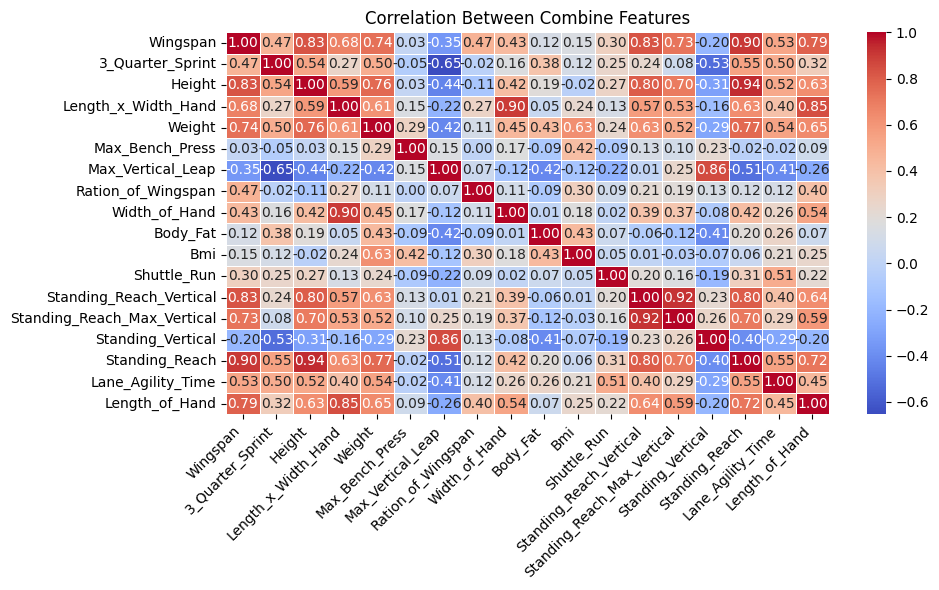

In [37]:
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", 
            cmap="coolwarm", linewidths=0.5,
            xticklabels=corr_matrix.columns,
            yticklabels=corr_matrix.columns
            )

plt.title("Correlation Between Combine Features")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate"
temp.mkdir(parents=True, exist_ok=True)
plt.savefig(temp / "Correlation_Between_Combine_Features.png")
plt.show()

This is a really nice correlation diagram! However, with so many features, it can be difficult to interpret. To improve readability, we isolate the upper triangle of the correlation matrix and apply an absolute correlation threshold of 0.5. This highlights only the strongest relationships between features, making the diagram much clearer and more actionable for analysis.

In [38]:
corr_matrix

Wingspan,3_Quarter_Sprint,Height,Length_x_Width_Hand,Weight,Max_Bench_Press,Max_Vertical_Leap,Ration_of_Wingspan,Width_of_Hand,Body_Fat,Bmi,Shuttle_Run,Standing_Reach_Vertical,Standing_Reach_Max_Vertical,Standing_Vertical,Standing_Reach,Lane_Agility_Time,Length_of_Hand
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1.0,0.469398,0.826723,0.678002,0.737763,0.026475,-0.35094,0.471482,0.433837,0.12158,0.151681,0.297876,0.829261,0.728342,-0.200314,0.903511,0.529529,0.788021
0.469398,1.0,0.535537,0.270071,0.49939,-0.054144,-0.65353,-0.015139,0.163098,0.382131,0.120104,0.251101,0.241524,0.077816,-0.52575,0.549084,0.502319,0.317915
0.826723,0.535537,1.0,0.591862,0.761868,0.028066,-0.437736,-0.105718,0.422876,0.191691,-0.021471,0.271038,0.799932,0.698462,-0.306393,0.940784,0.516686,0.633017
0.678002,0.270071,0.591862,1.0,0.61429,0.148969,-0.21988,0.272643,0.902193,0.045924,0.236144,0.126215,0.571104,0.5324,-0.156398,0.633522,0.395929,0.848039
0.737763,0.49939,0.761868,0.61429,1.0,0.286243,-0.42119,0.110081,0.44633,0.433012,0.629018,0.242534,0.625899,0.515381,-0.289123,0.76632,0.54297,0.648914
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.728342,0.077816,0.698462,0.5324,0.515381,0.10391,0.249988,0.193158,0.36857,-0.122264,-0.034227,0.162122,0.916236,1.0,0.261528,0.702892,0.285486,0.591962
-0.200314,-0.52575,-0.306393,-0.156398,-0.289123,0.228382,0.857786,0.130106,-0.078549,-0.411585,-0.070116,-0.191393,0.22665,0.261528,1.0,-0.398293,-0.289331,-0.196141
0.903511,0.549084,0.940784,0.633522,0.76632,-0.021695,-0.512998,0.121815,0.417335,0.197659,0.055573,0.30694,0.803115,0.702892,-0.398293,1.0,0.5535,0.719147


In [39]:
# Melt into long format and filter

corr_long = (
    corr_matrix.unpivot(
        variable_name="Feature1",
        value_name="Correlation"
    )
    .with_columns([
        pl.repeat(corr_matrix.columns, corr_matrix.height).explode().alias("Feature2")
    ])
)
corr_filtered = (
    corr_long
    .filter(pl.col("Feature1") != pl.col("Feature2")) # remove self pairs
    .filter(pl.col("Feature1") < pl.col("Feature2")) # locks in on upper triangle
)

corr_final = corr_filtered.with_columns(
    pl.col("Correlation").abs().alias("AbsCorrelation")
)
# Show the top 10 correlated features so we can see the strongest relationships
display(corr_final.sort("AbsCorrelation", descending=True).head(10))

Feature1,Correlation,Feature2,AbsCorrelation
str,f64,str,f64
"""Height""",0.940784,"""Standing_Reach""",0.940784
"""Standing_Reach_Max_Vertical""",0.916236,"""Standing_Reach_Vertical""",0.916236
"""Standing_Reach""",0.903511,"""Wingspan""",0.903511
"""Length_x_Width_Hand""",0.902193,"""Width_of_Hand""",0.902193
"""Max_Vertical_Leap""",0.857786,"""Standing_Vertical""",0.857786
"""Length_of_Hand""",0.848039,"""Length_x_Width_Hand""",0.848039
"""Standing_Reach_Vertical""",0.829261,"""Wingspan""",0.829261
"""Height""",0.826723,"""Wingspan""",0.826723
"""Standing_Reach""",0.803115,"""Standing_Reach_Vertical""",0.803115


Height,Max_Vertical_Leap,Standing_Vertical,Standing_Reach,Lane_Agility_Time,Wingspan,Length_x_Width_Hand,Weight,Standing_Reach_Vertical,Standing_Reach_Max_Vertical,Length_of_Hand,Width_of_Hand,Shuttle_Run
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0.535537,-0.65353,-0.52575,0.549084,0.502319,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
0.0,0.0,0.0,0.940784,0.516686,0.826723,0.591862,0.761868,0.799932,0.698462,0.633017,0.0,0.0
0.0,0.0,0.0,0.633522,0.0,0.678002,0.0,0.61429,0.571104,0.5324,0.0,0.902193,0.0
0.0,0.0,0.0,0.0,0.0,0.737763,0.0,0.0,0.0,0.0,0.0,0.0,0.0
0.0,0.0,0.857786,-0.512998,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


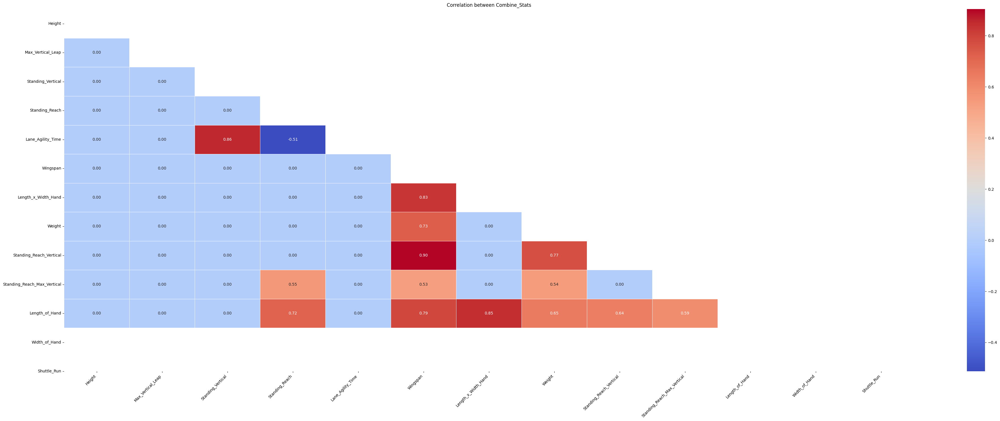

In [40]:

# Absolute value and threshold
top_corr = corr_final.filter(corr_final["AbsCorrelation"] > 0.5)
# Pivot the DataFrame for heatmap
# This will create a matrix where rows are Feature1, columns are Feature2, and values are the correlation coefficients
pivot_corr = top_corr.pivot(index="Feature1", on="Feature2", values="Correlation").drop("Feature1")
pivot_corr = pivot_corr.fill_null(0)
mask = np.triu(np.ones_like(pivot_corr, dtype=bool))
display(pivot_corr.head())
plt.figure(figsize=(40, 15))
sns.heatmap(pivot_corr, annot=True, fmt=".2f", 
            cmap="coolwarm", linewidths=0.5,
            xticklabels=pivot_corr.columns,
            yticklabels=pivot_corr.columns,
            mask=mask
            )

plt.title("Correlation between Combine_Stats")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate"
temp.mkdir(parents=True, exist_ok=True)
plt.savefig(temp / "Correlation_between_Combine_Stats.png")
plt.show()

In [41]:
corr_final.sort("AbsCorrelation", descending=True).head(10)

Feature1,Correlation,Feature2,AbsCorrelation
str,f64,str,f64
"""Height""",0.940784,"""Standing_Reach""",0.940784
"""Standing_Reach_Max_Vertical""",0.916236,"""Standing_Reach_Vertical""",0.916236
"""Standing_Reach""",0.903511,"""Wingspan""",0.903511
"""Length_x_Width_Hand""",0.902193,"""Width_of_Hand""",0.902193
"""Max_Vertical_Leap""",0.857786,"""Standing_Vertical""",0.857786
"""Length_of_Hand""",0.848039,"""Length_x_Width_Hand""",0.848039
"""Standing_Reach_Vertical""",0.829261,"""Wingspan""",0.829261
"""Height""",0.826723,"""Wingspan""",0.826723
"""Standing_Reach""",0.803115,"""Standing_Reach_Vertical""",0.803115


This is insightful! It's fascinating to see how these features interrelate—attributes like height, standing reach, wingspan, and weight are all closely connected. The taller the player, the higher the standing reach and typically the greater the wingspan and weight. These physical traits naturally influence performance metrics such as rebounding and blocking, as confirmed by the strong correlations observed. Understanding these relationships helps explain why certain combine measurements are so predictive of NBA success. Let's continue to explore how these attributes impact player outcomes and career achievements.

Feature1,Correlation,Feature2,AbsCorrelation
str,f64,str,f64
"""Height""",0.940784,"""Standing Reach""",0.940784
"""Standing Reach Max Vertical""",0.916236,"""Standing Reach Vertical""",0.916236
"""Standing Reach""",0.903511,"""Wingspan""",0.903511
"""Length X Width Hand""",0.902193,"""Width Of Hand""",0.902193
"""Max Vertical Leap""",0.857786,"""Standing Vertical""",0.857786
…,…,…,…
"""Length Of Hand""",0.788021,"""Wingspan""",0.788021
"""Standing Reach""",0.76632,"""Weight""",0.76632
"""Height""",0.761868,"""Weight""",0.761868


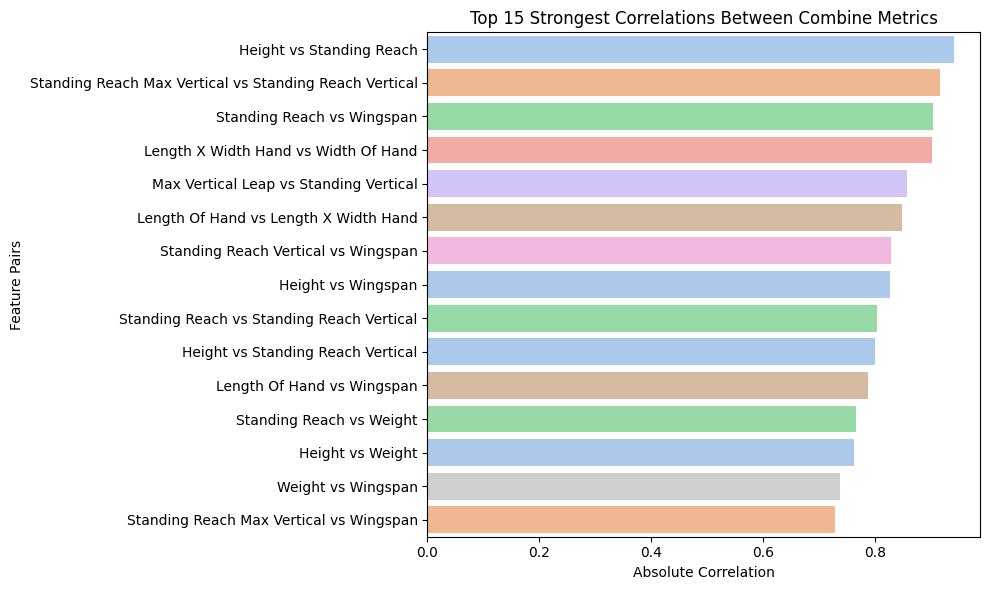

In [42]:
top_corrs = corr_final.sort("AbsCorrelation", descending=True).head(15)

top_corrs = top_corrs.with_columns(
    pl.col("Feature1").str.replace_all("_", " ").str.to_titlecase().alias("Feature1"),
    pl.col("Feature2").str.replace_all("_", " ").str.to_titlecase().alias("Feature2")
)
display(top_corrs)
plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_corrs,
    x="AbsCorrelation",
    y=top_corrs["Feature1"] + " vs " + top_corrs["Feature2"],
    palette="pastel",
    hue=top_corrs["Feature1"],
    legend=False
)
plt.title(f"Top {15} Strongest Correlations Between Combine Metrics")
plt.xlabel("Absolute Correlation")
plt.ylabel("Feature Pairs")
plt.tight_layout()
temp = visualization_path / f"bivariate"
temp.mkdir(parents=True, exist_ok=True)
plt.savefig(temp / "Top_15_Strongest_Correlation.png")
plt.show()

### Categorical vs Numerical

In this section, we compare NBA Draft Combine statistics against categorical variables such as player position and season. By visualizing how physical and performance metrics vary across positions (PG, SG, SF, PF, C) and over different draft years, we can uncover patterns and trends in player attributes and combine results.

**Key analyses include:**
- Bar plots and error bars showing the mean and standard deviation of combine stats by position.
- Facet and line plots illustrating how combine metrics change across seasons.
- Boxplots and pairplots to highlight differences in combine stats for award recipients (e.g., All-Star, All-NBA Team, Defensive Team) versus non-recipients.

These visualizations help reveal which physical traits are most common for each position, how combine results have evolved over time, and whether standout measurements are associated with NBA accolades. This bivariate analysis provides actionable insights for scouting, player development, and understanding the impact of physical attributes on career outcomes.

In [43]:
df_wide_view_positions = df_wide_view.with_columns(
    pl.when(pl.col("Position").str.contains("/", literal=True))
    .then(pl.col("Position").str.split("/"))
    .otherwise(pl.col("Position").map_elements(lambda x: [x], return_dtype=pl.List(pl.String)))
    .replace("", None)
    .alias("Position")
).explode("Position")
df_wide_view_positions

Position,Player,Season,Wingspan,3_Quarter_Sprint,Height,Length_x_Width_Hand,Weight,Max_Bench_Press,Max_Vertical_Leap,Ration_of_Wingspan,Width_of_Hand,Body_Fat,Bmi,Shuttle_Run,Standing_Reach_Vertical,Standing_Reach_Max_Vertical,Standing_Vertical,Standing_Reach,Lane_Agility_Time,Length_of_Hand
str,str,str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""SG""","""Grayson Allen""","""2018-19""",79.25,3.15,75.0,82.5,198.0,null,40.5,1.057,10.0,0.056,24.700001,3.04,129.5,137.5,32.5,97.0,10.31,8.25
null,"""Eric Coley""","""2000-01""",83.0,3.15,76.0,null,205.0,10.0,38.0,1.092,null,null,25.0,null,137.0,140.0,35.0,102.0,11.4,null
"""PG""","""Reed Sheppard""","""2024-25""",75.300003,3.08,73.800003,69.800003,181.600006,null,42.0,1.02,9.0,null,23.5,3.03,126.0,135.5,32.5,93.5,10.96,7.75
"""SF""","""Austin Daye""","""2009-10""",86.75,3.55,81.75,null,191.800003,0.0,28.0,1.061,null,0.055,20.200001,null,135.0,138.0,25.0,110.0,12.11,null
"""SG""","""John Jenkins""","""2012-13""",80.5,3.37,75.25,81.0,212.0,10.0,36.5,1.07,9.0,0.071,26.299999,null,128.5,134.5,30.5,98.0,11.36,9.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,"""Kenny Adeleke""","""2006-07""",82.25,3.47,78.5,null,250.0,26.0,30.5,1.048,null,0.105,28.5,null,132.5,134.5,28.5,104.0,11.57,null
"""C""","""Rudy Gobert""","""2013-14""",92.5,3.57,84.5,97.5,237.600006,7.0,29.0,1.095,10.0,0.044,23.4,3.19,140.0,144.0,25.0,115.0,12.85,9.75
null,"""Ryan Carroll""","""2001-02""",80.25,3.1,76.0,null,202.0,14.0,39.0,1.056,null,0.08,24.6,null,133.5,138.0,34.5,99.0,11.0,null


In [44]:
df_wide_view_positions.null_count()

Position,Player,Season,Wingspan,3_Quarter_Sprint,Height,Length_x_Width_Hand,Weight,Max_Bench_Press,Max_Vertical_Leap,Ration_of_Wingspan,Width_of_Hand,Body_Fat,Bmi,Shuttle_Run,Standing_Reach_Vertical,Standing_Reach_Max_Vertical,Standing_Vertical,Standing_Reach,Lane_Agility_Time,Length_of_Hand
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
543,0,0,3,258,4,941,5,737,248,4,941,503,5,1375,248,249,247,5,260,941


There are 543 null values in the `Position` column, indicating that these players either did not get drafted or did not play in the NBA. This missingness highlights the distinction between combine participants who made it to the league and those who did not, and is important to consider in downstream analyses.

In [45]:
undrafted_no_nba_df = df_wide_view_positions.filter(pl.col("Position").is_null())
df_wide_view_positions = df_wide_view_positions.drop_nulls("Position")

In [46]:
numeric_cols = df_wide_view_positions.select([pl.col(pl.Float32), pl.col(pl.Float64), pl.col(pl.Int64)]).columns

df_summary = df_wide_view_positions.group_by("Position").agg(
    [
        *(pl.col(col).mean().alias(f"{col}_mean") for col in numeric_cols),
        *(pl.col(col).std().alias(f"{col}_std") for col in numeric_cols)
    ]
)
df_summary

Position,Wingspan_mean,3_Quarter_Sprint_mean,Height_mean,Length_x_Width_Hand_mean,Weight_mean,Max_Bench_Press_mean,Max_Vertical_Leap_mean,Ration_of_Wingspan_mean,Width_of_Hand_mean,Body_Fat_mean,Bmi_mean,Shuttle_Run_mean,Standing_Reach_Vertical_mean,Standing_Reach_Max_Vertical_mean,Standing_Vertical_mean,Standing_Reach_mean,Lane_Agility_Time_mean,Length_of_Hand_mean,Wingspan_std,3_Quarter_Sprint_std,Height_std,Length_x_Width_Hand_std,Weight_std,Max_Bench_Press_std,Max_Vertical_Leap_std,Ration_of_Wingspan_std,Width_of_Hand_std,Body_Fat_std,Bmi_std,Shuttle_Run_std,Standing_Reach_Vertical_std,Standing_Reach_Max_Vertical_std,Standing_Vertical_std,Standing_Reach_std,Lane_Agility_Time_std,Length_of_Hand_std
str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""SF""",82.856422,3.248473,77.985291,82.202751,214.393021,10.283898,35.664516,1.062642,9.409266,0.067588,24.79796,3.082609,133.972031,139.547745,30.088425,103.927406,11.277262,8.752315,2.20706,0.117179,1.472926,7.808844,15.188764,5.194096,3.341225,0.027323,0.617728,0.021223,1.798122,0.174834,2.944841,3.168736,2.849911,2.446338,0.472817,0.376637
"""PF""",84.994583,3.299785,79.799194,87.096146,230.881592,11.371542,34.273006,1.065312,9.711597,0.077416,25.510843,3.115857,135.875534,140.792328,29.363914,106.668297,11.450558,8.973176,2.302653,0.124093,1.635164,8.50385,17.346436,5.468189,3.098984,0.027859,0.67772,0.027044,2.06159,0.197338,3.123149,3.176418,2.889952,2.622063,0.488786,0.38852
"""C""",86.691864,3.348113,81.414703,89.703423,241.795898,11.389221,32.840374,1.065041,9.835176,0.08562,25.669397,3.142728,137.264328,141.703293,28.401409,109.020813,11.767267,9.134482,2.440395,0.149306,1.839901,8.515203,19.976648,4.996204,3.381814,0.029333,0.690162,0.034372,2.248242,0.205984,3.097404,3.11311,3.142398,2.744162,0.560862,0.406139
"""PG""",78.233398,3.19747,73.614204,75.654305,189.295883,8.4153,36.418068,1.062841,9.081509,0.062449,24.566429,3.016923,128.044357,134.289078,30.185354,97.974541,11.022991,8.348266,2.764105,0.101282,2.076422,6.682992,18.845734,4.940546,3.371294,0.027744,0.557094,0.020696,2.296232,0.231105,3.515159,3.753733,2.840714,3.193079,0.420151,0.382802
"""SG""",80.629128,3.227252,75.949295,78.623283,200.966522,9.072519,35.986301,1.061757,9.219105,0.064493,24.496412,3.040513,131.072052,137.068497,29.989862,101.121246,11.139027,8.540798,2.603145,0.122121,1.888225,7.012119,15.281934,5.009425,3.326728,0.027473,0.58941,0.019594,1.703393,0.296474,3.525728,3.719856,2.862582,2.941894,0.441489,0.366655


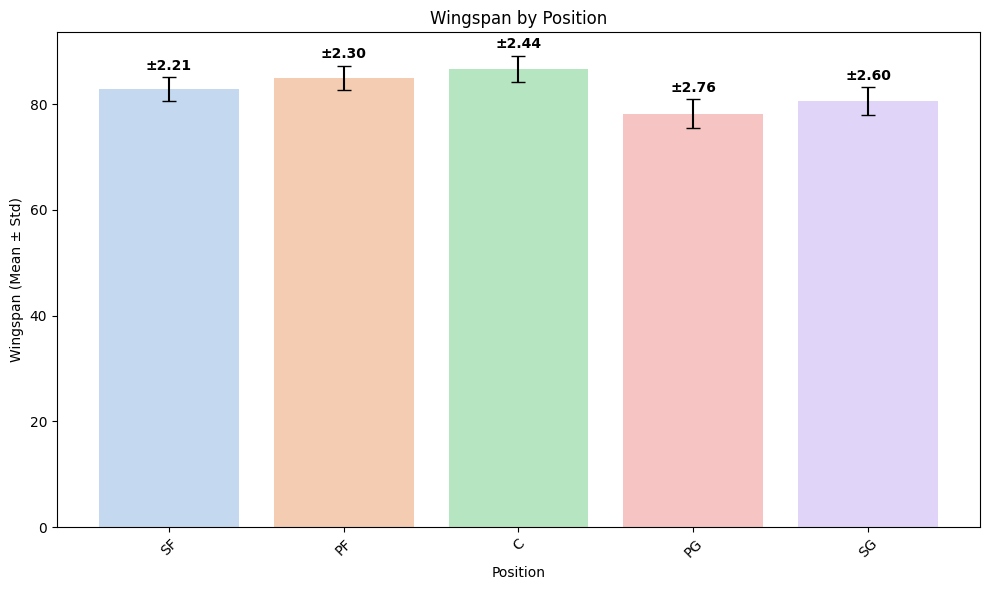

shape: (5, 3)
┌──────────┬───────────────┬──────────────┐
│ Position ┆ Wingspan_mean ┆ Wingspan_std │
│ ---      ┆ ---           ┆ ---          │
│ str      ┆ f32           ┆ f32          │
╞══════════╪═══════════════╪══════════════╡
│ SF       ┆ 82.856422     ┆ 2.20706      │
│ PF       ┆ 84.994583     ┆ 2.302653     │
│ C        ┆ 86.691864     ┆ 2.440395     │
│ PG       ┆ 78.233398     ┆ 2.764105     │
│ SG       ┆ 80.629128     ┆ 2.603145     │
└──────────┴───────────────┴──────────────┘


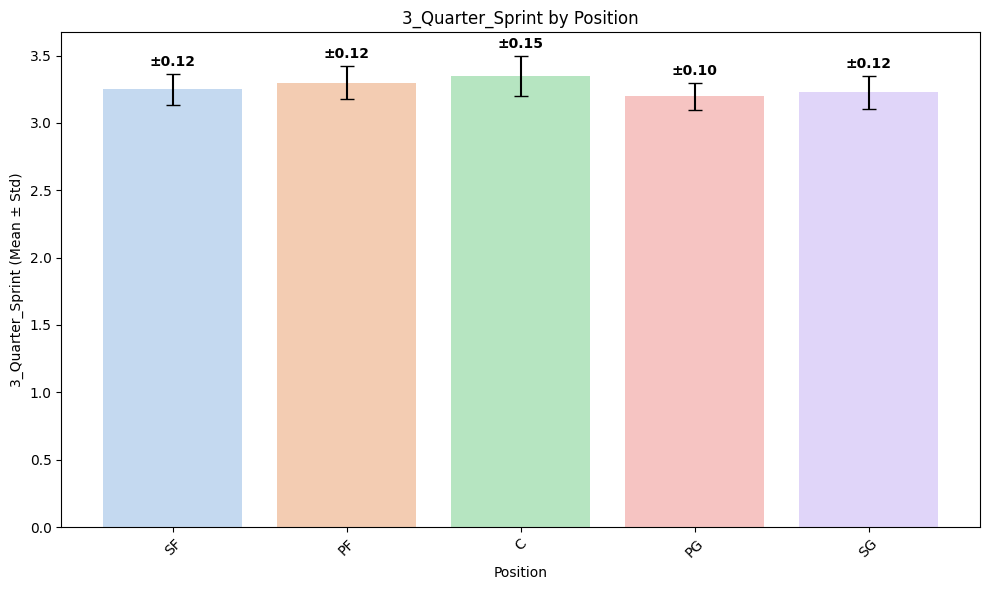

shape: (5, 3)
┌──────────┬───────────────────────┬──────────────────────┐
│ Position ┆ 3_Quarter_Sprint_mean ┆ 3_Quarter_Sprint_std │
│ ---      ┆ ---                   ┆ ---                  │
│ str      ┆ f32                   ┆ f32                  │
╞══════════╪═══════════════════════╪══════════════════════╡
│ SF       ┆ 3.248473              ┆ 0.117179             │
│ PF       ┆ 3.299785              ┆ 0.124093             │
│ C        ┆ 3.348113              ┆ 0.149306             │
│ PG       ┆ 3.19747               ┆ 0.101282             │
│ SG       ┆ 3.227252              ┆ 0.122121             │
└──────────┴───────────────────────┴──────────────────────┘


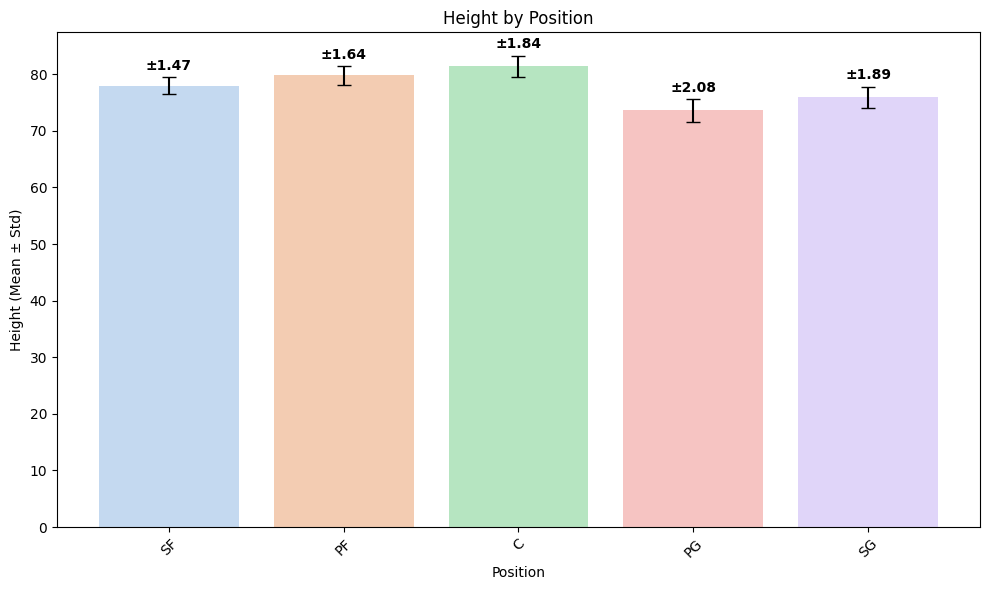

shape: (5, 3)
┌──────────┬─────────────┬────────────┐
│ Position ┆ Height_mean ┆ Height_std │
│ ---      ┆ ---         ┆ ---        │
│ str      ┆ f32         ┆ f32        │
╞══════════╪═════════════╪════════════╡
│ SF       ┆ 77.985291   ┆ 1.472926   │
│ PF       ┆ 79.799194   ┆ 1.635164   │
│ C        ┆ 81.414703   ┆ 1.839901   │
│ PG       ┆ 73.614204   ┆ 2.076422   │
│ SG       ┆ 75.949295   ┆ 1.888225   │
└──────────┴─────────────┴────────────┘


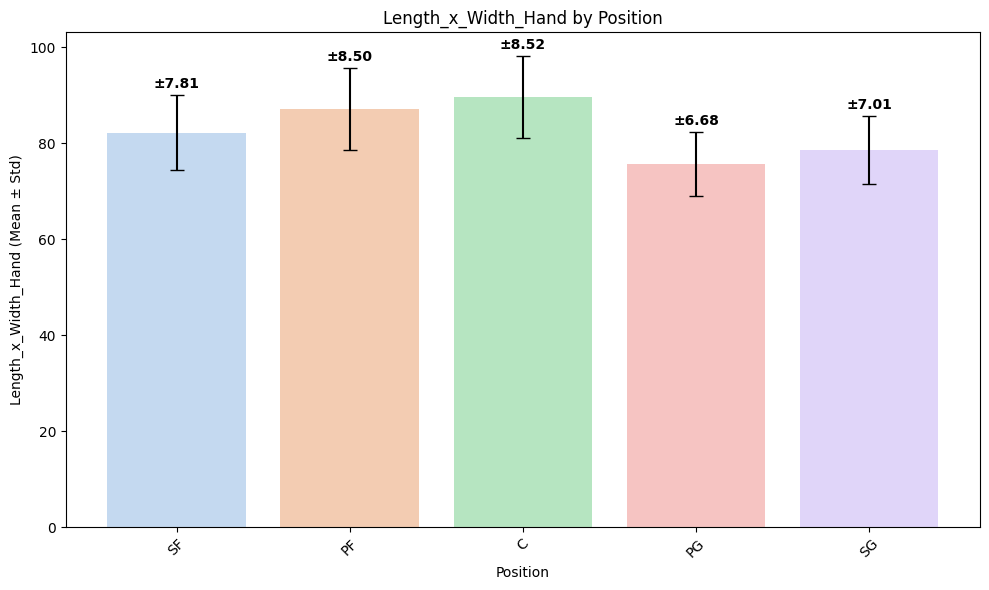

shape: (5, 3)
┌──────────┬──────────────────────────┬─────────────────────────┐
│ Position ┆ Length_x_Width_Hand_mean ┆ Length_x_Width_Hand_std │
│ ---      ┆ ---                      ┆ ---                     │
│ str      ┆ f32                      ┆ f32                     │
╞══════════╪══════════════════════════╪═════════════════════════╡
│ SF       ┆ 82.202751                ┆ 7.808844                │
│ PF       ┆ 87.096146                ┆ 8.50385                 │
│ C        ┆ 89.703423                ┆ 8.515203                │
│ PG       ┆ 75.654305                ┆ 6.682992                │
│ SG       ┆ 78.623283                ┆ 7.012119                │
└──────────┴──────────────────────────┴─────────────────────────┘


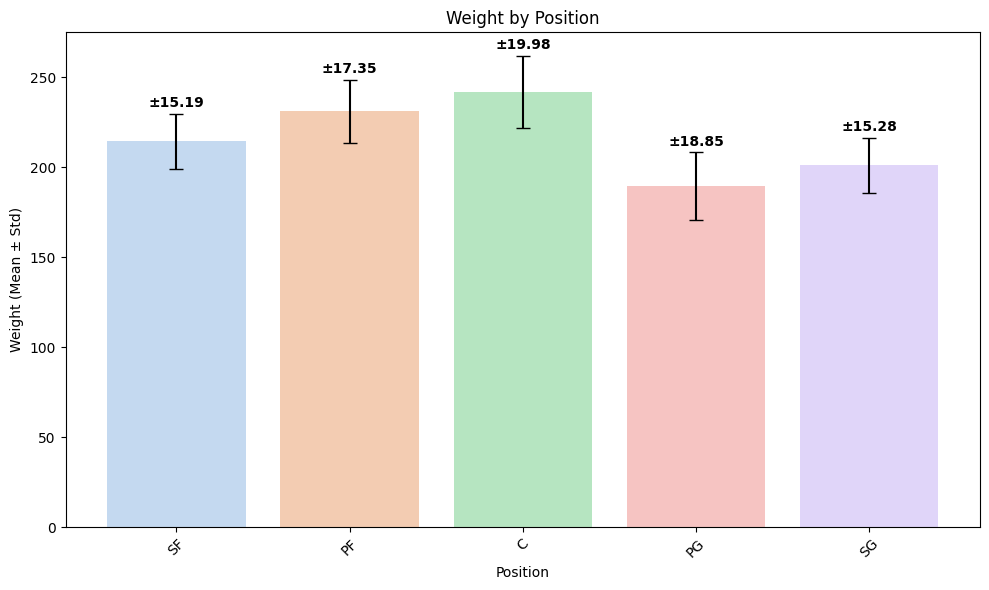

shape: (5, 3)
┌──────────┬─────────────┬────────────┐
│ Position ┆ Weight_mean ┆ Weight_std │
│ ---      ┆ ---         ┆ ---        │
│ str      ┆ f32         ┆ f32        │
╞══════════╪═════════════╪════════════╡
│ SF       ┆ 214.393021  ┆ 15.188764  │
│ PF       ┆ 230.881592  ┆ 17.346436  │
│ C        ┆ 241.795898  ┆ 19.976648  │
│ PG       ┆ 189.295883  ┆ 18.845734  │
│ SG       ┆ 200.966522  ┆ 15.281934  │
└──────────┴─────────────┴────────────┘


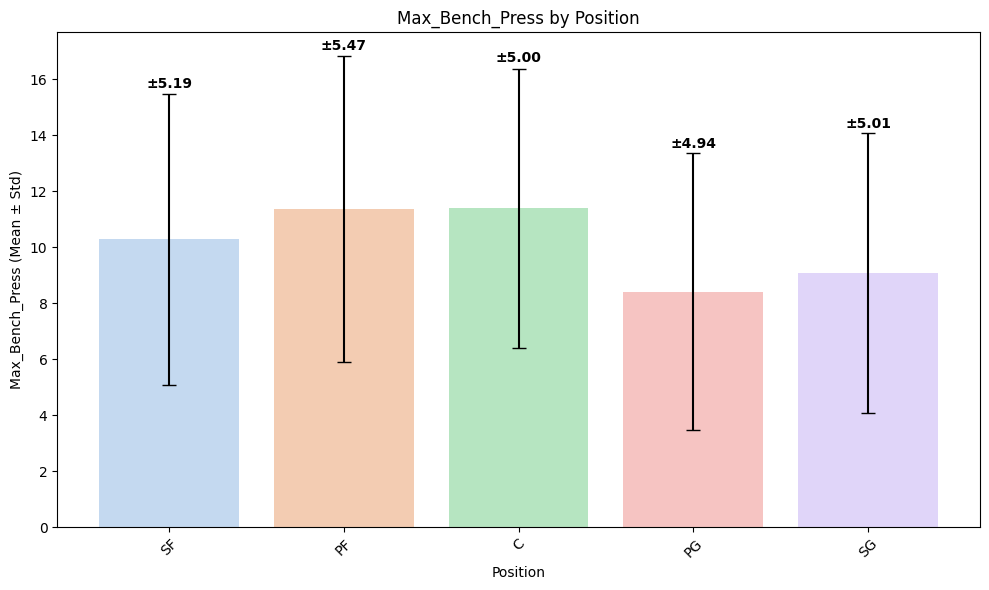

shape: (5, 3)
┌──────────┬──────────────────────┬─────────────────────┐
│ Position ┆ Max_Bench_Press_mean ┆ Max_Bench_Press_std │
│ ---      ┆ ---                  ┆ ---                 │
│ str      ┆ f32                  ┆ f32                 │
╞══════════╪══════════════════════╪═════════════════════╡
│ SF       ┆ 10.283898            ┆ 5.194096            │
│ PF       ┆ 11.371542            ┆ 5.468189            │
│ C        ┆ 11.389221            ┆ 4.996204            │
│ PG       ┆ 8.4153               ┆ 4.940546            │
│ SG       ┆ 9.072519             ┆ 5.009425            │
└──────────┴──────────────────────┴─────────────────────┘


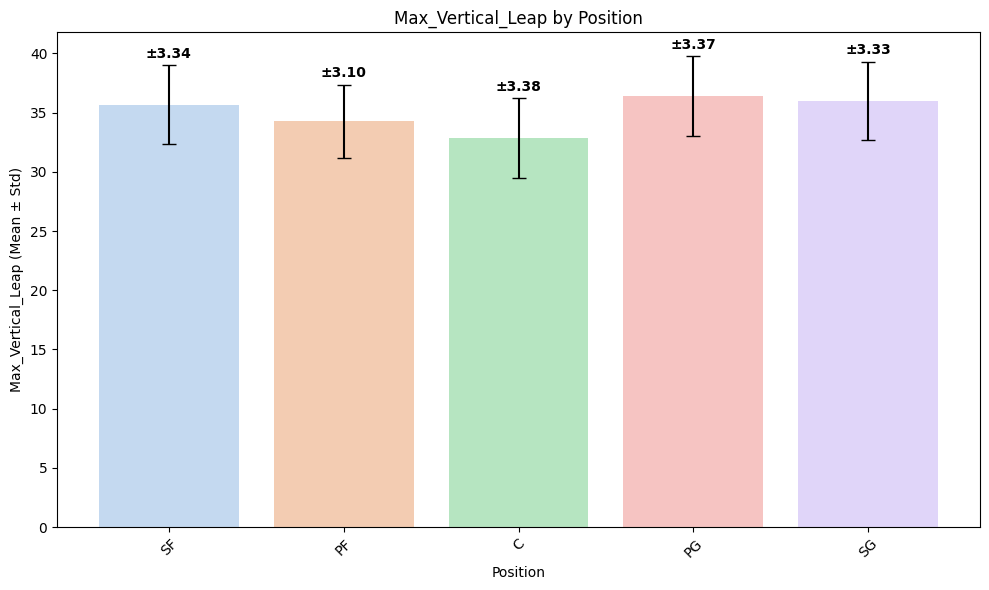

shape: (5, 3)
┌──────────┬────────────────────────┬───────────────────────┐
│ Position ┆ Max_Vertical_Leap_mean ┆ Max_Vertical_Leap_std │
│ ---      ┆ ---                    ┆ ---                   │
│ str      ┆ f32                    ┆ f32                   │
╞══════════╪════════════════════════╪═══════════════════════╡
│ SF       ┆ 35.664516              ┆ 3.341225              │
│ PF       ┆ 34.273006              ┆ 3.098984              │
│ C        ┆ 32.840374              ┆ 3.381814              │
│ PG       ┆ 36.418068              ┆ 3.371294              │
│ SG       ┆ 35.986301              ┆ 3.326728              │
└──────────┴────────────────────────┴───────────────────────┘


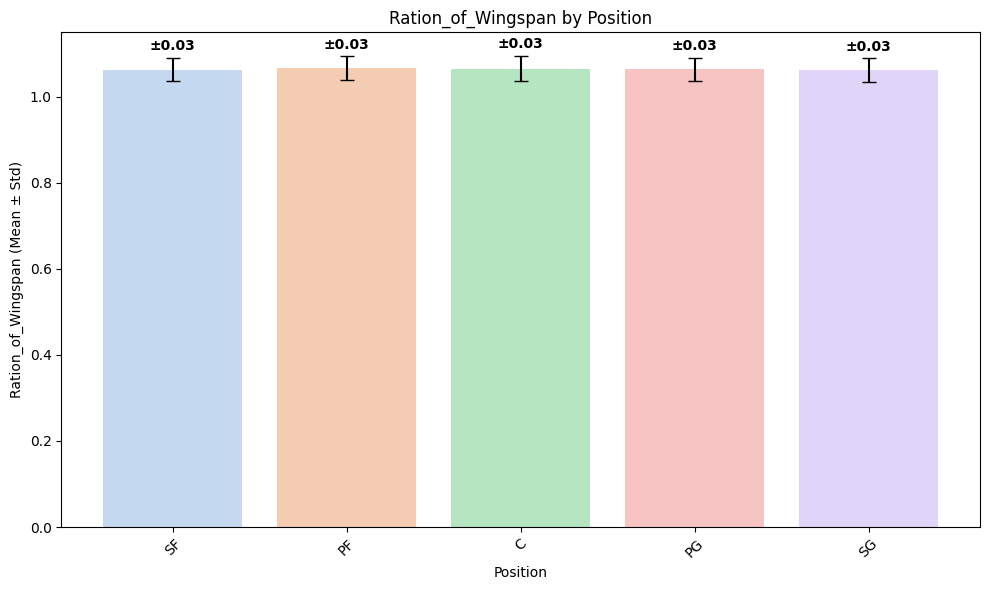

shape: (5, 3)
┌──────────┬─────────────────────────┬────────────────────────┐
│ Position ┆ Ration_of_Wingspan_mean ┆ Ration_of_Wingspan_std │
│ ---      ┆ ---                     ┆ ---                    │
│ str      ┆ f32                     ┆ f32                    │
╞══════════╪═════════════════════════╪════════════════════════╡
│ SF       ┆ 1.062642                ┆ 0.027323               │
│ PF       ┆ 1.065312                ┆ 0.027859               │
│ C        ┆ 1.065041                ┆ 0.029333               │
│ PG       ┆ 1.062841                ┆ 0.027744               │
│ SG       ┆ 1.061757                ┆ 0.027473               │
└──────────┴─────────────────────────┴────────────────────────┘


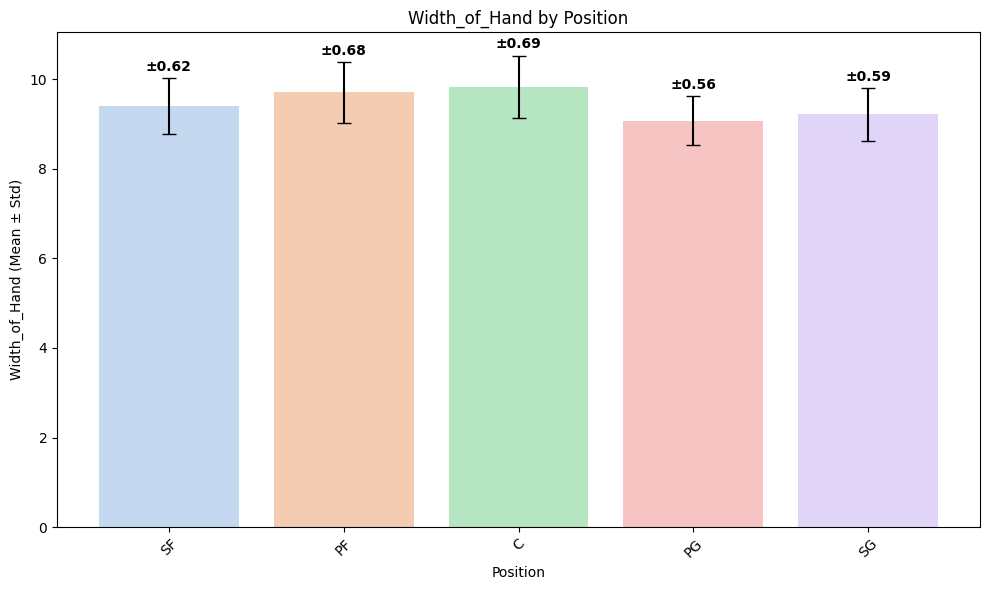

shape: (5, 3)
┌──────────┬────────────────────┬───────────────────┐
│ Position ┆ Width_of_Hand_mean ┆ Width_of_Hand_std │
│ ---      ┆ ---                ┆ ---               │
│ str      ┆ f32                ┆ f32               │
╞══════════╪════════════════════╪═══════════════════╡
│ SF       ┆ 9.409266           ┆ 0.617728          │
│ PF       ┆ 9.711597           ┆ 0.67772           │
│ C        ┆ 9.835176           ┆ 0.690162          │
│ PG       ┆ 9.081509           ┆ 0.557094          │
│ SG       ┆ 9.219105           ┆ 0.58941           │
└──────────┴────────────────────┴───────────────────┘


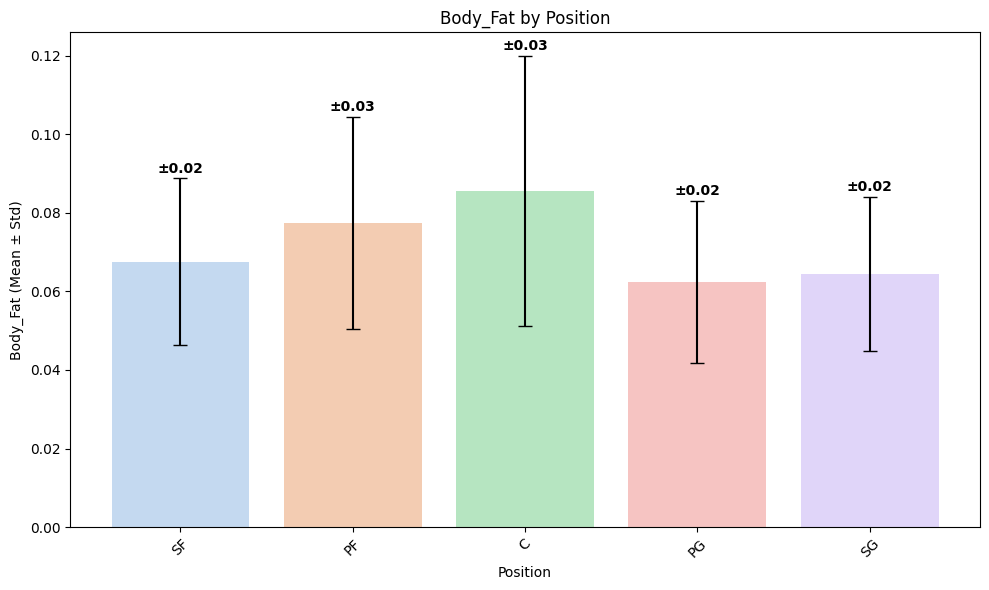

shape: (5, 3)
┌──────────┬───────────────┬──────────────┐
│ Position ┆ Body_Fat_mean ┆ Body_Fat_std │
│ ---      ┆ ---           ┆ ---          │
│ str      ┆ f32           ┆ f32          │
╞══════════╪═══════════════╪══════════════╡
│ SF       ┆ 0.067588      ┆ 0.021223     │
│ PF       ┆ 0.077416      ┆ 0.027044     │
│ C        ┆ 0.08562       ┆ 0.034372     │
│ PG       ┆ 0.062449      ┆ 0.020696     │
│ SG       ┆ 0.064493      ┆ 0.019594     │
└──────────┴───────────────┴──────────────┘


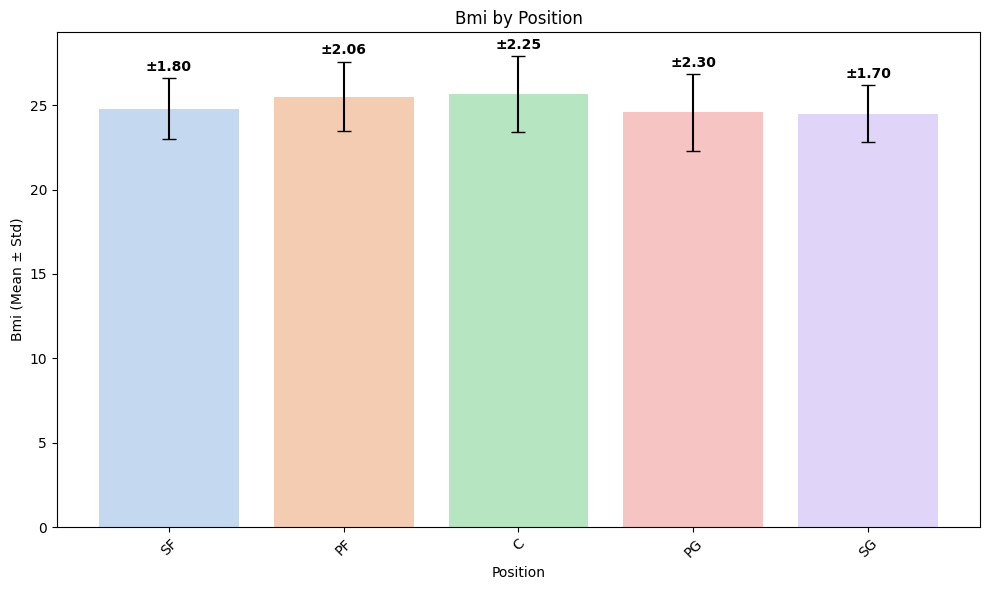

shape: (5, 3)
┌──────────┬───────────┬──────────┐
│ Position ┆ Bmi_mean  ┆ Bmi_std  │
│ ---      ┆ ---       ┆ ---      │
│ str      ┆ f32       ┆ f32      │
╞══════════╪═══════════╪══════════╡
│ SF       ┆ 24.79796  ┆ 1.798122 │
│ PF       ┆ 25.510843 ┆ 2.06159  │
│ C        ┆ 25.669397 ┆ 2.248242 │
│ PG       ┆ 24.566429 ┆ 2.296232 │
│ SG       ┆ 24.496412 ┆ 1.703393 │
└──────────┴───────────┴──────────┘


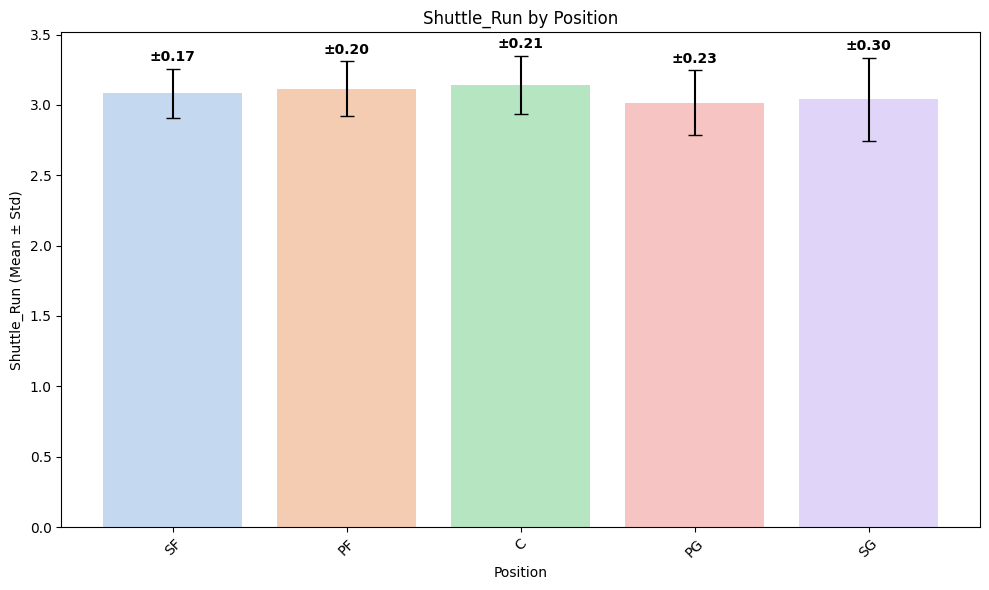

shape: (5, 3)
┌──────────┬──────────────────┬─────────────────┐
│ Position ┆ Shuttle_Run_mean ┆ Shuttle_Run_std │
│ ---      ┆ ---              ┆ ---             │
│ str      ┆ f32              ┆ f32             │
╞══════════╪══════════════════╪═════════════════╡
│ SF       ┆ 3.082609         ┆ 0.174834        │
│ PF       ┆ 3.115857         ┆ 0.197338        │
│ C        ┆ 3.142728         ┆ 0.205984        │
│ PG       ┆ 3.016923         ┆ 0.231105        │
│ SG       ┆ 3.040513         ┆ 0.296474        │
└──────────┴──────────────────┴─────────────────┘


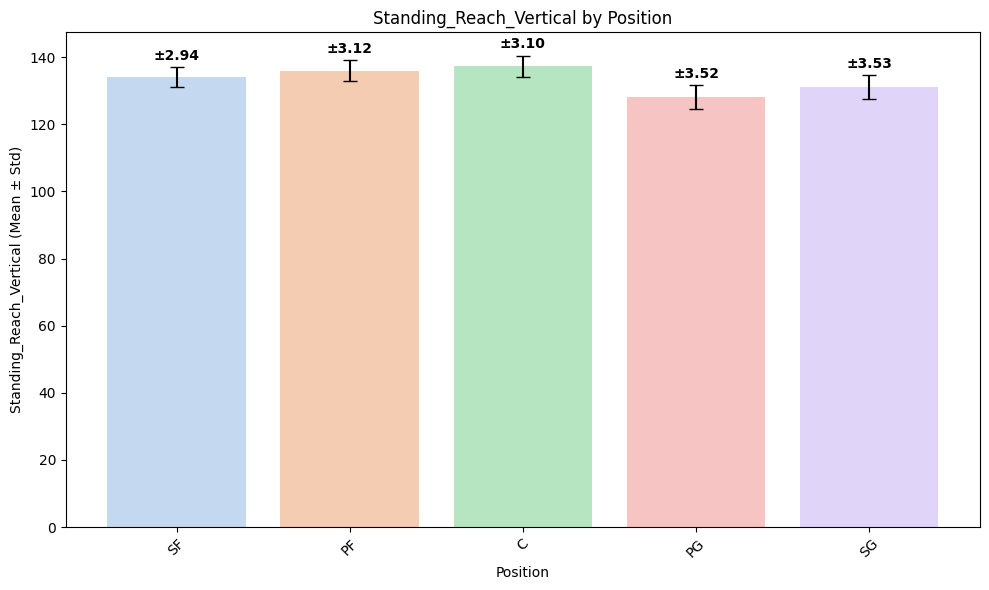

shape: (5, 3)
┌──────────┬──────────────────────────────┬─────────────────────────────┐
│ Position ┆ Standing_Reach_Vertical_mean ┆ Standing_Reach_Vertical_std │
│ ---      ┆ ---                          ┆ ---                         │
│ str      ┆ f32                          ┆ f32                         │
╞══════════╪══════════════════════════════╪═════════════════════════════╡
│ SF       ┆ 133.972031                   ┆ 2.944841                    │
│ PF       ┆ 135.875534                   ┆ 3.123149                    │
│ C        ┆ 137.264328                   ┆ 3.097404                    │
│ PG       ┆ 128.044357                   ┆ 3.515159                    │
│ SG       ┆ 131.072052                   ┆ 3.525728                    │
└──────────┴──────────────────────────────┴─────────────────────────────┘


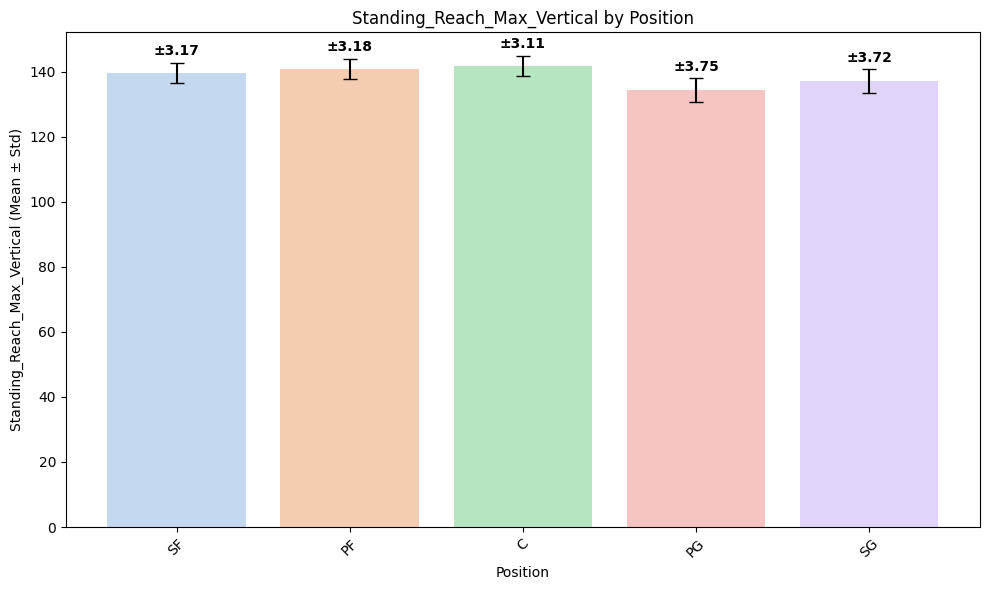

shape: (5, 3)
┌──────────┬─────────────────────────────────┬─────────────────────────────────┐
│ Position ┆ Standing_Reach_Max_Vertical_me… ┆ Standing_Reach_Max_Vertical_st… │
│ ---      ┆ ---                             ┆ ---                             │
│ str      ┆ f32                             ┆ f32                             │
╞══════════╪═════════════════════════════════╪═════════════════════════════════╡
│ SF       ┆ 139.547745                      ┆ 3.168736                        │
│ PF       ┆ 140.792328                      ┆ 3.176418                        │
│ C        ┆ 141.703293                      ┆ 3.11311                         │
│ PG       ┆ 134.289078                      ┆ 3.753733                        │
│ SG       ┆ 137.068497                      ┆ 3.719856                        │
└──────────┴─────────────────────────────────┴─────────────────────────────────┘


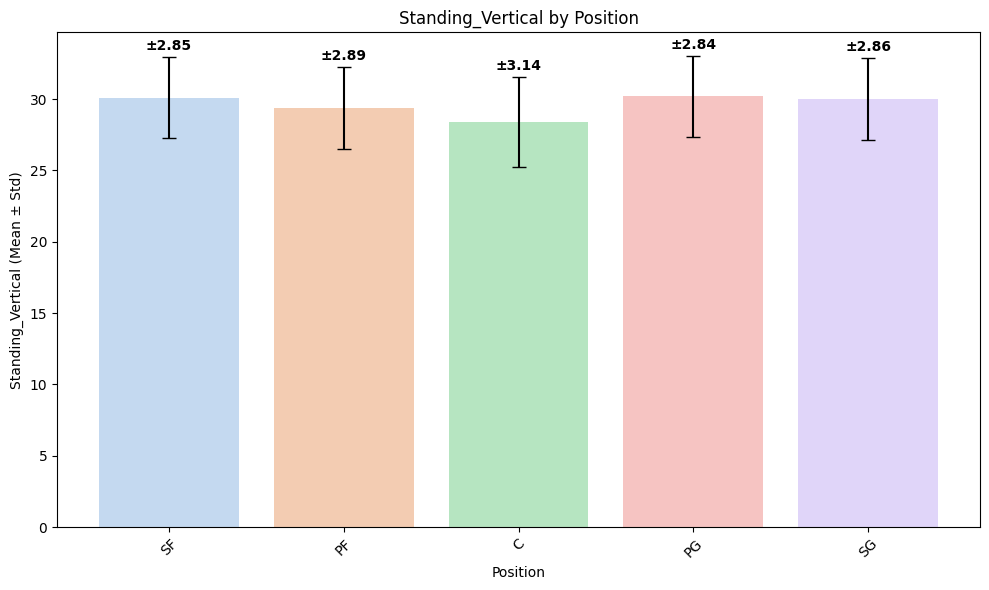

shape: (5, 3)
┌──────────┬────────────────────────┬───────────────────────┐
│ Position ┆ Standing_Vertical_mean ┆ Standing_Vertical_std │
│ ---      ┆ ---                    ┆ ---                   │
│ str      ┆ f32                    ┆ f32                   │
╞══════════╪════════════════════════╪═══════════════════════╡
│ SF       ┆ 30.088425              ┆ 2.849911              │
│ PF       ┆ 29.363914              ┆ 2.889952              │
│ C        ┆ 28.401409              ┆ 3.142398              │
│ PG       ┆ 30.185354              ┆ 2.840714              │
│ SG       ┆ 29.989862              ┆ 2.862582              │
└──────────┴────────────────────────┴───────────────────────┘


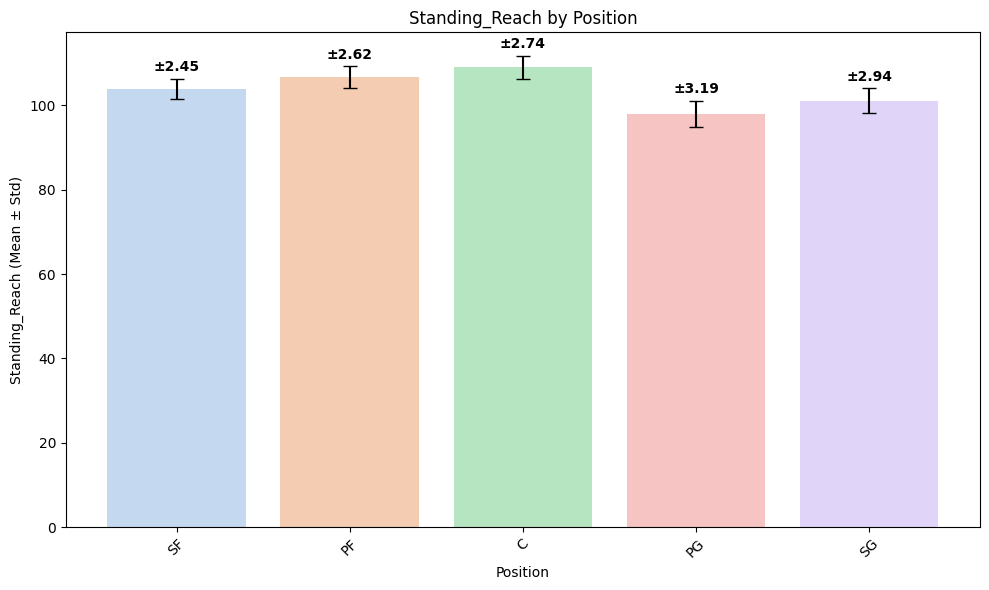

shape: (5, 3)
┌──────────┬─────────────────────┬────────────────────┐
│ Position ┆ Standing_Reach_mean ┆ Standing_Reach_std │
│ ---      ┆ ---                 ┆ ---                │
│ str      ┆ f32                 ┆ f32                │
╞══════════╪═════════════════════╪════════════════════╡
│ SF       ┆ 103.927406          ┆ 2.446338           │
│ PF       ┆ 106.668297          ┆ 2.622063           │
│ C        ┆ 109.020813          ┆ 2.744162           │
│ PG       ┆ 97.974541           ┆ 3.193079           │
│ SG       ┆ 101.121246          ┆ 2.941894           │
└──────────┴─────────────────────┴────────────────────┘


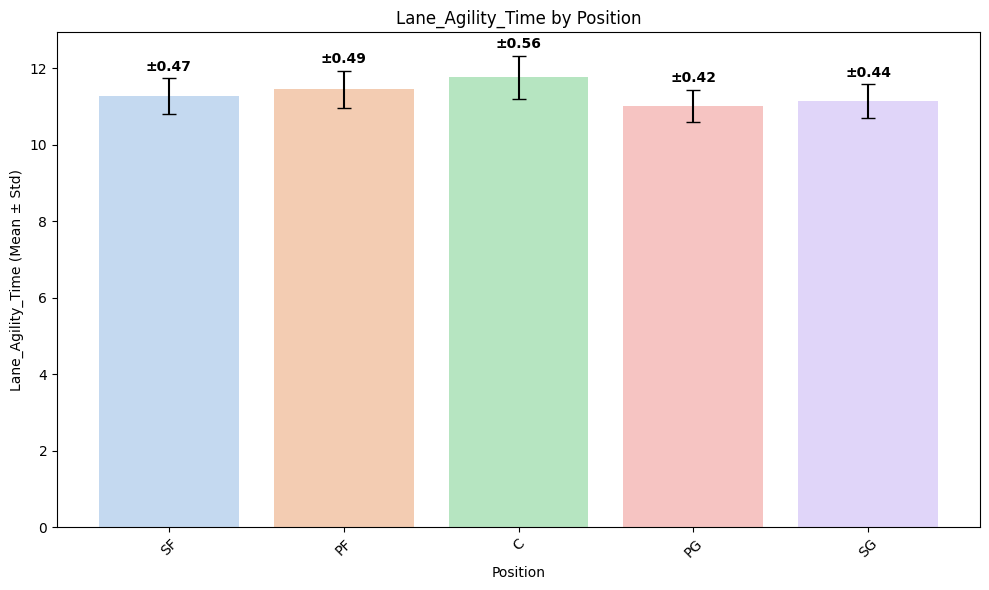

shape: (5, 3)
┌──────────┬────────────────────────┬───────────────────────┐
│ Position ┆ Lane_Agility_Time_mean ┆ Lane_Agility_Time_std │
│ ---      ┆ ---                    ┆ ---                   │
│ str      ┆ f32                    ┆ f32                   │
╞══════════╪════════════════════════╪═══════════════════════╡
│ SF       ┆ 11.277262              ┆ 0.472817              │
│ PF       ┆ 11.450558              ┆ 0.488786              │
│ C        ┆ 11.767267              ┆ 0.560862              │
│ PG       ┆ 11.022991              ┆ 0.420151              │
│ SG       ┆ 11.139027              ┆ 0.441489              │
└──────────┴────────────────────────┴───────────────────────┘


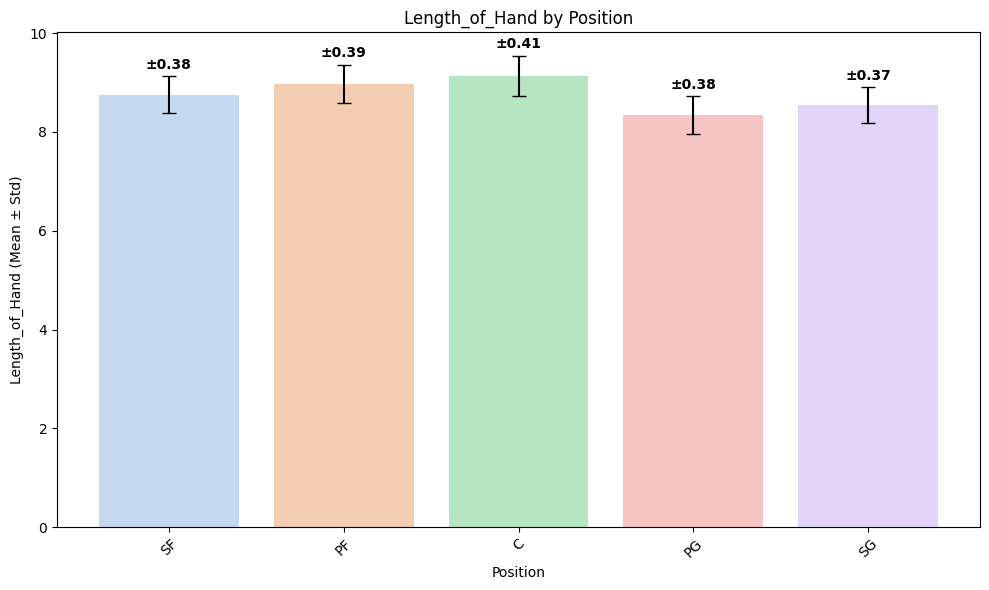

shape: (5, 3)
┌──────────┬─────────────────────┬────────────────────┐
│ Position ┆ Length_of_Hand_mean ┆ Length_of_Hand_std │
│ ---      ┆ ---                 ┆ ---                │
│ str      ┆ f32                 ┆ f32                │
╞══════════╪═════════════════════╪════════════════════╡
│ SF       ┆ 8.752315            ┆ 0.376637           │
│ PF       ┆ 8.973176            ┆ 0.38852            │
│ C        ┆ 9.134482            ┆ 0.406139           │
│ PG       ┆ 8.348266            ┆ 0.382802           │
│ SG       ┆ 8.540798            ┆ 0.366655           │
└──────────┴─────────────────────┴────────────────────┘


In [47]:
combine_stats = df_wide_view_positions.select(pl.exclude(pl.String)).columns

def plot_stats_by_position(col: str, df: pl.DataFrame):
    plt.figure(figsize=(10, 6))
    # Create a bar plot with error bars
    # Using seaborn's barplot to get mean and standard deviation
    # Note: Seaborn's barplot automatically calculates the mean and standard deviation
    # but we will add error bars manually for better control
    ax = sns.barplot(
        df_summary,
        x="Position",
        y=f"{col}_mean",
        capsize=5,
        alpha=0.7,
        palette="pastel",
        hue="Position",
    )
    
    # Add error bars manually using matplotlib
    x_coords = range(len(df_summary))
    means = df_summary[f"{col}_mean"].to_list()
    stds = df_summary[f"{col}_std"].to_list()
    
    ax.errorbar(x_coords, means, yerr=stds, fmt='none', c='black', capsize=5, lw=1.5)

      # Add std text on top of each bar
    for x, y, std in zip(x_coords, means, stds):
        offset = y * 0.01 # Slightly above the error bar
        ax.text(
            x,
            y + std + offset,
            f"±{std:.2f}",
            ha="center",
            va="bottom",
            fontsize=10,
            color="black",
            fontweight="bold"
        )

    ax.set_ylabel(f"{col.replace('_', ' ')} (Mean ± Std)")
    ax.set_title(f"{col.replace('_', ' ')} by Position")
    ax.set_xticks(x_coords)

    plt.ylabel(f"{col} (Mean ± Std)")
    plt.title(f"{col} by Position")
    plt.xticks(rotation=45)
    plt.tight_layout()
    temp = visualization_path / f"bivariate"
    temp.mkdir(parents=True, exist_ok=True)
    plt.savefig(temp / f"Bivariate_{col}_by_Position.png")
    plt.show()
    
    print(df_summary.select("Position", f"{col}_mean", f"{col}_std"))


for col in combine_stats:
    plot_stats_by_position(col, df_summary)


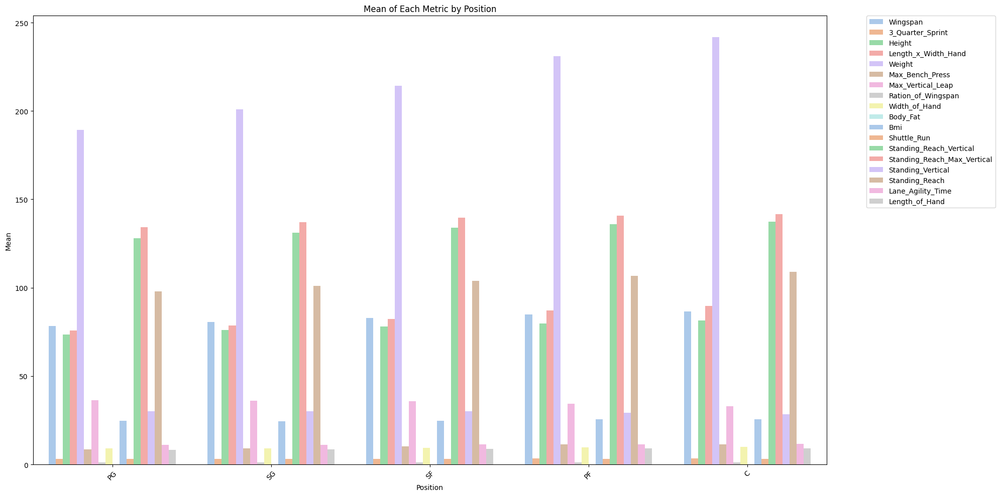

In [48]:
# Melt the wide dataframe into long format for seaborn
df_melted = df_summary.unpivot(
    index=["Position"],
    on=[col for col in df_summary.columns if col.endswith("_mean")],
    variable_name="Metric",
    value_name="Mean"
)

df_melted = df_melted.with_columns(
    pl.col("Metric").str.replace("_mean$", "")
)
plt.figure(figsize=(20, 10))
sns.barplot(data=df_melted, x="Position", y="Mean", hue="Metric", palette="pastel",
        order=["PG", "SG", "SF", "PF", "C"] )
plt.xticks(rotation=45)
plt.title("Mean of Each Metric by Position")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()
temp = visualization_path / f"bivariate"
temp.mkdir(parents=True, exist_ok=True)
plt.savefig(temp / "Mean_Metric_by_Position.png")
plt.show()


The previous graphic was difficult to interpret due to the number of metrics and overlapping bars. To provide clearer insights, we will use pairplots to visualize the distribution and relationships of each combine stat by player position. Pairplots allow us to compare multiple features simultaneously, making it easier to identify patterns and differences across positions for key physical and performance metrics.

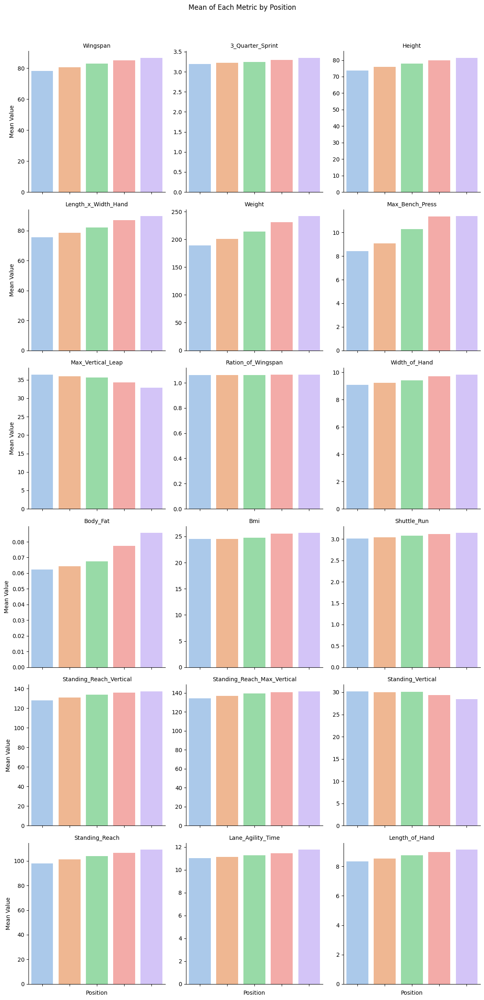

In [49]:
positions_order = ["PG", "SG", "SF", "PF", "C"]

g = sns.FacetGrid(df_melted, col="Metric", col_wrap=3, sharey=False, sharex=False, height=4)

# Map barplot with hue=Position, order specified for both x and hue
g.map_dataframe(
    sns.barplot,
    x="Position",
    y="Mean",
    hue="Position",
    order=positions_order,
    hue_order=positions_order,
    dodge=False,      # bars grouped together, not side-by-side
    palette="pastel",
    legend=True      # disable legend for now
    
)
g.set_titles("{col_name}")
g.set_axis_labels("Position", "Mean Value")
g.fig.suptitle("Mean of Each Metric by Position", y=1.02)
# Remove x-tick labels to avoid clutter
for ax in g.axes.flatten():
    ax.set_xticklabels([])
plt.tight_layout()
temp = visualization_path / f"bivariate"
temp.mkdir(parents=True, exist_ok=True)
plt.savefig(visualization_path / "bivariate/Bivariate_Stats_by_Positions.png")
plt.show()


### Season vs Combine Stats

In [50]:
numeric_cols = df_wide_view_positions.select([pl.col(pl.Float32), pl.col(pl.Float64), pl.col(pl.Int64)]).columns

df_summary = df_wide_view.group_by("Season").agg(
    [
        *(pl.col(col).mean().alias(f"{col}_mean") for col in numeric_cols),
        *(pl.col(col).std().alias(f"{col}_std") for col in numeric_cols)
    ]
)
df_summary

Season,Wingspan_mean,3_Quarter_Sprint_mean,Height_mean,Length_x_Width_Hand_mean,Weight_mean,Max_Bench_Press_mean,Max_Vertical_Leap_mean,Ration_of_Wingspan_mean,Width_of_Hand_mean,Body_Fat_mean,Bmi_mean,Shuttle_Run_mean,Standing_Reach_Vertical_mean,Standing_Reach_Max_Vertical_mean,Standing_Vertical_mean,Standing_Reach_mean,Lane_Agility_Time_mean,Length_of_Hand_mean,Wingspan_std,3_Quarter_Sprint_std,Height_std,Length_x_Width_Hand_std,Weight_std,Max_Bench_Press_std,Max_Vertical_Leap_std,Ration_of_Wingspan_std,Width_of_Hand_std,Body_Fat_std,Bmi_std,Shuttle_Run_std,Standing_Reach_Vertical_std,Standing_Reach_Max_Vertical_std,Standing_Vertical_std,Standing_Reach_std,Lane_Agility_Time_std,Length_of_Hand_std
str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""2018-19""",82.415321,3.198979,77.161293,83.33226,209.72905,7.956522,36.153061,1.068226,9.45,0.066016,24.720966,3.173674,131.785721,138.387756,29.55102,102.814514,11.274491,8.82258,3.944269,0.089168,3.084897,8.305732,22.687963,5.006469,3.377629,0.031801,0.623515,0.019394,1.616831,0.150398,4.054319,4.061077,2.656056,4.836028,0.503988,0.469101
"""2025-26""",82.0625,3.158823,78.246529,84.140274,212.488907,null,34.875,1.049014,9.563885,null,24.351385,3.002941,132.610291,138.507355,28.977942,103.611115,11.227942,8.78125,3.823056,0.183852,3.460922,9.268934,23.905823,null,3.391577,0.026457,0.692882,null,1.626366,0.119664,4.581635,4.226332,2.795831,4.710807,0.485874,0.494579
"""2015-16""",82.698273,3.299317,77.293106,79.501724,213.482712,8.452381,35.409092,1.069983,9.194825,0.073776,25.046549,3.11525,131.961365,137.681824,29.688637,103.637932,11.10814,8.646552,3.973531,0.128251,3.286782,9.796106,24.922394,4.768813,4.233412,0.027329,0.69318,0.025951,1.671559,0.198894,4.884775,4.749652,3.671146,5.038269,0.483712,0.534007
"""2012-13""",82.683334,3.359075,77.98333,84.57,219.898285,9.849056,35.172726,1.060267,9.541665,0.072817,25.374996,null,132.845459,137.490906,30.527273,102.26667,11.347172,8.8625,3.901017,0.134069,3.04586,9.814263,24.954533,5.375858,3.185933,0.027485,0.759637,0.022139,1.987898,null,4.832253,4.273617,2.517381,4.620759,0.536557,0.449635
"""2023-24""",82.173691,3.223878,77.635101,80.766663,210.564957,null,35.846939,1.058579,9.389472,null,24.57193,3.147778,133.765305,139.214279,30.397959,103.385963,11.161633,8.596491,3.092475,0.188346,2.229149,9.240542,20.379755,null,2.848984,0.025143,0.700939,null,2.059885,0.150901,3.699806,3.338538,2.571842,3.438253,0.382793,0.442584
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""2005-06""",82.40506,3.290845,77.48101,null,215.986038,10.527027,33.197182,1.063456,null,null,25.208858,null,132.435715,137.064285,28.577465,104.006332,11.357717,null,4.477562,0.119269,3.533669,null,28.806595,5.58428,3.32789,0.030116,null,null,2.128512,null,5.198886,4.998494,2.800061,5.33343,0.629656,null
"""2009-10""",81.414772,3.245,77.034088,null,213.43187,11.341463,34.595238,1.056886,null,0.070773,25.222725,null,131.845245,137.369049,29.071428,103.056816,11.152856,null,4.244676,0.112255,3.553818,null,26.680399,5.332025,2.583338,0.028424,null,0.02126,2.052889,null,4.544479,4.318225,2.096953,4.8082,0.434271,null
"""2003-04""",82.83654,3.262535,78.307693,null,224.179489,11.026667,33.633804,1.057897,null,0.096078,25.596155,null,132.938889,137.79718,28.777779,104.133331,11.545999,null,4.39429,0.13964,3.442223,null,32.894852,5.959261,3.480515,0.03443,null,0.041189,2.455338,null,4.612767,4.534407,3.126318,5.108477,0.665261,null


In [51]:
# Melt the wide dataframe into long format for seaborn
df_melted = df_summary.unpivot(
    index=["Season"],
    on=[col for col in df_summary.columns if col.endswith("_mean")],
    variable_name="Metric",
    value_name="Mean"
)

df_melted = df_melted.with_columns(
    pl.col("Metric").str.replace("_mean$", "")
).sort("Season")

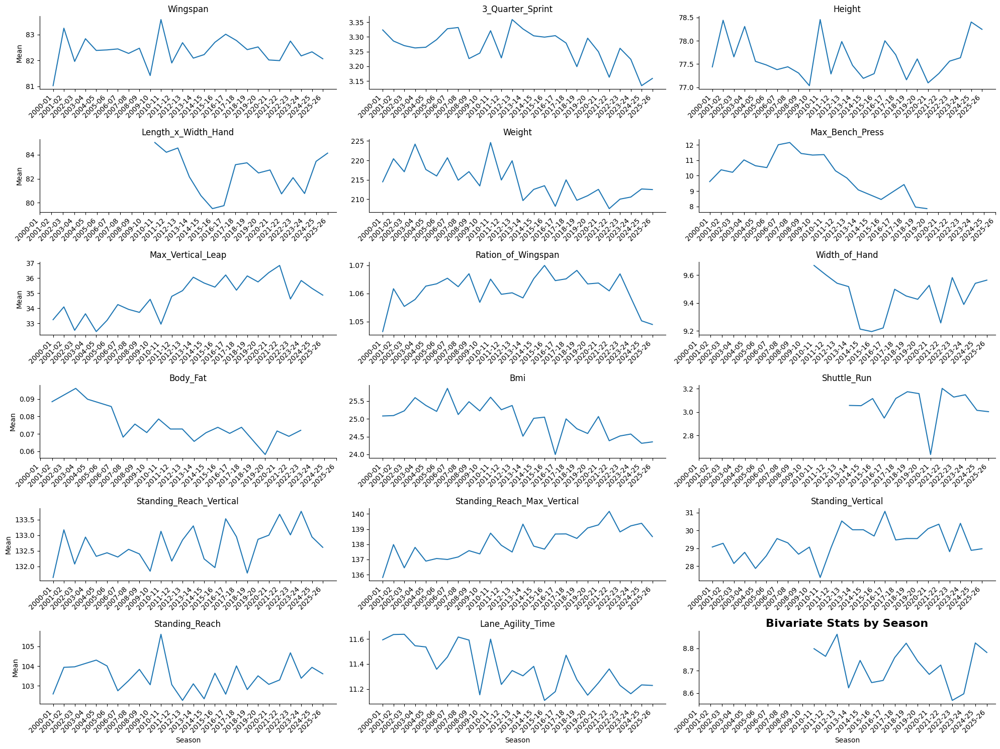

In [52]:
seasons = sorted(df_melted["Season"].unique())

# Create FacetGrid with one chart per Metric
g = sns.FacetGrid(
    df_melted,
    col="Metric",
    col_wrap=3,
    sharey=False,
    sharex=False,
    height=4
)

# Map lineplot: hue should be Position (to compare positions across seasons)
g.map_dataframe(
    sns.lineplot,
    x="Season",
    y="Mean",
)

# Rotate x-ticks and improve spacing
for ax in g.axes.flatten():
    # ax.tick_params(axis='x', rotation=45, ha='right', labelsize=)
    # Get the current x-axis tick locations
    ticks = ax.get_xticks()

    # Set the same ticks and align the labels correctly
    ax.set_xticks(ticks)
    ax.set_xticklabels(seasons, rotation=45, ha='right')
    ax.set_title(ax.get_title().replace("Metric = ", ""))  # Clean up title text

# Add legend only once
g.fig.set_size_inches(20, 15)  # or larger, depending on how many plots
plt.title("Bivariate Stats by Season", fontsize=16, weight='bold')
plt.subplots_adjust(top=0.9)  # Adjust top to make room for the title
plt.tight_layout()
temp = visualization_path / f"bivariate"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Bivariate_Stats_by_Season_Lineplots.png")
plt.show()



## Bivariate Analysis Summary: NBA Draft Combine

### Numerical vs Numerical

The bivariate analysis of NBA Draft Combine data reveals strong interrelationships among physical and performance metrics. Features such as Height, Wingspan, Standing Reach, and Weight are highly correlated, indicating that taller players tend to have longer wingspans, greater standing reach, and higher body mass. These physical attributes also show robust positive correlations with key NBA performance metrics—most notably, Total Rebound Percentage (TRB%), Defensive Rebound Percentage (DRB%), Offensive Rebound Percentage (ORB%), and Block Percentage (BLK%). For example, players with greater height and wingspan consistently achieve higher rebound and block rates, underscoring the predictive value of these combine measurements for on-court success.

### Numerical vs "Categorical" (Season & Position)

#### By Position

When stratified by position (PG, SG, SF, PF, C), clear differences emerge in physical and athletic profiles. Centers (C) and Power Forwards (PF) exhibit the highest averages in Height, Wingspan, Standing Reach, and Weight, reflecting the demands of their roles near the basket. Guards (PG, SG) are generally shorter and lighter, with lower combine metrics in these categories. Performance metrics such as rebounding and blocking also vary by position, with bigs (PF, C) dominating these areas, while guards excel in agility and speed-related stats.

#### By Season

Examining combine metrics across draft seasons reveals subtle trends in player profiles over time. While the average physical attributes remain relatively stable, certain metrics—such as vertical leap and agility—show slight improvements in more recent years, possibly reflecting advances in training and athlete development. Participation rates and the distribution of combine measurements fluctuate by season, highlighting changes in draft class composition and evolving league standards.

### Key Takeaways

- Physical attributes measured at the combine are strongly predictive of NBA performance, especially in rebounding and blocking.
- Positional analysis confirms that centers and forwards possess superior size and reach, while guards excel in speed and agility.
- Seasonal trends suggest incremental improvements in athleticism, with some variability in combine participation and measurement distributions.
- These insights support the use of combine data for scouting, player development, and forecasting NBA success.

## Draft Combine Stats vs NBA Performance


This section explores how key physical attributes measured at the NBA Draft Combine—Wingspan, Height, and Standing Reach—compare among top NBA performers. We analyze their relationships with important NBA performance metrics such as Total Rebound Percentage (TRB%), Defensive Rebound Percentage (DRB%), Offensive Rebound Percentage (ORB%), and Block Percentage (BLK%).

**Key questions addressed:**
- Do players with greater wingspan, height, or standing reach achieve higher rebound and block rates?
- How do these physical traits differ between All-Star players and others?
- Are standout combine measurements associated with NBA accolades and top performance?

Visualizations below include scatterplots, pairplots, and boxplots to highlight the strongest correlations and distribution differences. These insights help reveal which physical traits are most predictive of NBA success and recognition.

### Construct query to grab combine data with nba data

In [53]:
query = """
SELECT 
    p.name as Player, 
    s.label as Season,
    po.name as Position,
    nba_stat.name as NBA_Stat,
    psv.value as NBA_Value, 
    
    combine_stat.name as Combine_Stat,
    csv.value as Combine_Value, 
     
    a.allstar as AllStar,
    a.all_defense_team as Defense_Team,
    a.all_nba_team as All_NBA_Team,
    a.mvp_rank as MVP_Rank,
    a.dpoy_rank as DPOY_Rank

from nba_data.main.player_stat_values psv
JOIN nba_data.main.players p on psv.player_id == p.player_id
JOIN nba_data.main.player_positions pp on pp.player_id == p.player_id
JOIN nba_data.main.positions po on po.position_id == pp.position_id
JOIN nba_data.main.award_info a on a.player_id == p.player_id
JOIN nba_data.main.combine_stat_values csv on csv.player_id == p.player_id
JOIN nba_data.main.seasons s on psv.season_id == s.season_id
JOIN nba_data.main.stats nba_stat on nba_stat.stat_id == psv.stat_id
JOIN nba_data.main.stats combine_stat on combine_stat.stat_id == csv.stat_id 
"""

with get_duckdb_connection() as con:
    df_nba_combined = pl.from_arrow(con.execute(query).arrow()).lazy()
    df_nba_combined.collect().columns

Connected to: /Users/rashe/PycharmProjects/PredictingNBACareers/data/refined_raw_data/nba_data.duckdb


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [54]:
df_nba_combined.collect().head()

Player,Season,Position,NBA_Stat,NBA_Value,Combine_Stat,Combine_Value,AllStar,Defense_Team,All_NBA_Team,MVP_Rank,DPOY_Rank
str,str,str,str,f32,str,f32,bool,i32,i32,i32,i32
"""Nathan Knight""","""2021-22""","""C""","""FG%""",0.511,"""Body_Fat""",0.082,false,0,0,0,0
"""Greg Monroe""","""2021-22""","""PF""","""FT""",12.0,"""Length_of_Hand""",8.75,false,0,0,0,0
"""Gordon Hayward""","""2021-22""","""PF""","""ORB""",38.0,"""Body_Fat""",0.069,false,0,0,0,0
"""Markieff Morris""","""2021-22""","""PF""","""eFG%""",0.531,"""Bmi""",26.6,false,0,0,0,0
"""Lamar Stevens""","""2021-22""","""SF""","""MP""",1015.0,"""Wingspan""",81.0,false,0,0,0,0


In [55]:
df = df_nba_combined.with_columns([
    (pl.col("Player") + "_" + pl.col("Season")).alias("Player_Season")
])

In [56]:
nba_wide = (
    df.collect().select(["Player_Season", "NBA_Stat", "NBA_Value"])
      .pivot(
          values="NBA_Value",
          index="Player_Season",
          on="NBA_Stat",
          aggregate_function="first"  # Assuming no duplicates
      )
)

In [57]:
combine_wide = (
    df.collect().select(["Player_Season", "Combine_Stat", "Combine_Value"])
      .pivot(
          values="Combine_Value",
          index="Player_Season",
          on="Combine_Stat",
          aggregate_function="first"
      )
)

In [58]:
combine_wide

Player_Season,Body_Fat,Length_of_Hand,Bmi,Wingspan,Width_of_Hand,Standing_Reach_Max_Vertical,Max_Vertical_Leap,Height,Lane_Agility_Time,Standing_Vertical,Standing_Reach,Max_Bench_Press,Standing_Reach_Vertical,Ration_of_Wingspan,3_Quarter_Sprint,Length_x_Width_Hand,Shuttle_Run,Weight
str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""Nathan Knight_2021-22""",0.082,9.0,25.799999,86.0,9.5,141.0,31.5,80.0,11.56,23.0,109.5,null,132.5,1.075,3.31,85.5,2.96,235.0
"""Greg Monroe_2021-22""",0.112,8.75,25.9,86.25,9.5,137.5,29.0,81.75,12.1,25.0,108.5,15.0,133.5,1.055,3.35,83.099998,null,246.600006
"""Gordon Hayward_2021-22""",0.069,8.5,23.9,79.75,9.3,137.5,34.5,78.75,11.73,30.5,103.0,10.0,133.5,1.013,3.22,78.599998,null,211.0
"""Markieff Morris_2021-22""",0.102,8.5,26.6,82.75,8.3,138.0,31.5,79.75,null,27.0,106.5,11.0,133.5,1.038,3.4,70.099998,null,240.800003
"""Lamar Stevens_2021-22""",0.068,8.5,26.5,81.0,9.8,142.0,41.0,77.75,10.35,35.0,101.0,null,136.0,1.042,3.2,82.900002,2.54,228.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""Marcus Thornton_2009-10""",0.053,8.25,22.9,79.75,8.5,140.5,43.0,73.75,10.78,34.5,97.5,3.0,132.0,1.081,3.02,70.099998,2.88,177.399994
"""Chris Duhon_2009-10""",0.067,null,26.200001,78.5,null,133.0,35.0,72.0,10.45,31.5,98.0,7.0,129.5,1.09,3.14,null,null,193.0
"""Rasual Butler_2009-10""",null,null,22.4,84.0,null,143.0,37.5,78.75,11.54,31.5,105.5,10.0,137.0,1.067,3.29,null,null,198.0


In [59]:
combined_wide = nba_wide.join(combine_wide, on="Player_Season", how="inner")

In [60]:
combined_wide = combined_wide.with_columns(
    pl.col("Player_Season").str.split_exact("_", 1).alias("split")
).unnest("split").rename({"field_0": "Player", "field_1": "Season"}).drop("Player_Season")

In [61]:
combined_wide

FG%,FT,ORB,eFG%,MP,Trp-Dbl,3P,TRB,3P%,FGA,AST,2P%,TOV,G,DRB,FG,GS,PTS,FTA,BLK,2PA,2P,STL,3PA,PF,FT%,TS%,USG%,OWS,BLK%,AST%,OBPM,ORB%,WS,DRB%,FTr,STL%,DWS,BPM,TRB%,3PAr,VORP,DBPM,TOV%,WS/48,PER,Body_Fat,Length_of_Hand,Bmi,Wingspan,Width_of_Hand,Standing_Reach_Max_Vertical,Max_Vertical_Leap,Height,Lane_Agility_Time,Standing_Vertical,Standing_Reach,Max_Bench_Press,Standing_Reach_Vertical,Ration_of_Wingspan,3_Quarter_Sprint,Length_x_Width_Hand,Shuttle_Run,Weight,Player,Season
f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,str,str
0.511,44.0,32.0,0.534,267.0,0.0,4.0,2.3,0.308,88.0,0.6,0.547,18.0,37.0,53.0,45.0,2.0,138.0,60.0,0.2,75.0,1.1,0.2,0.4,42.0,0.733,0.603,20.700001,0.6,2.9,11.9,-0.7,12.5,1.0,21.799999,0.682,1.2,0.3,-0.6,17.1,0.148,0.1,0.1,13.6,0.171,18.700001,0.082,9.0,25.799999,86.0,9.5,141.0,31.5,80.0,11.56,23.0,109.5,null,132.5,1.075,3.31,85.5,2.96,235.0,"""Nathan Knight""","""2021-22"""
0.561,12.0,30.0,0.561,195.0,0.0,0.0,64.0,null,57.0,22.0,0.561,12.0,14.0,34.0,32.0,0.0,76.0,23.0,10.0,57.0,32.0,8.0,0.0,24.0,0.522,0.566,17.299999,0.4,4.8,16.200001,-0.3,16.9,0.7,18.799999,0.404,2.0,0.3,0.4,17.700001,0.0,0.1,0.7,15.2,0.169,19.5,0.112,8.75,25.9,86.25,9.5,137.5,29.0,81.75,12.1,25.0,108.5,15.0,133.5,1.055,3.35,83.099998,null,246.600006,"""Greg Monroe""","""2021-22"""
0.459,126.0,38.0,0.528,1564.0,0.0,1.8,224.0,0.391,617.0,177.0,0.496,81.0,49.0,186.0,283.0,48.0,778.0,149.0,22.0,397.0,197.0,47.0,220.0,85.0,0.846,0.57,20.700001,1.9,1.3,16.1,0.1,2.5,2.8,12.8,0.241,1.4,1.0,-0.7,7.6,0.357,0.5,-0.8,10.6,0.087,15.1,0.069,8.5,23.9,79.75,9.3,137.5,34.5,78.75,11.73,30.5,103.0,10.0,133.5,1.013,3.22,78.599998,null,211.0,"""Gordon Hayward""","""2021-22"""
0.474,8.0,17.0,0.531,298.0,0.0,13.0,45.0,0.333,114.0,23.0,0.547,20.0,17.0,28.0,54.0,1.0,129.0,9.0,1.0,75.0,41.0,6.0,39.0,33.0,0.889,0.547,20.6,0.0,0.4,12.1,-1.5,6.6,0.3,10.5,0.079,1.0,0.3,-1.9,8.6,0.342,0.0,-0.4,14.5,0.054,10.9,0.102,8.5,26.6,82.75,8.3,138.0,31.5,79.75,null,27.0,106.5,11.0,133.5,1.038,3.4,70.099998,null,240.800003,"""Markieff Morris""","""2021-22"""
0.489,53.0,47.0,0.517,1015.0,0.0,18.0,164.0,0.277,319.0,44.0,0.543,41.0,63.0,117.0,156.0,13.0,383.0,75.0,18.0,254.0,138.0,31.0,65.0,1.7,0.707,0.544,17.1,0.4,1.6,6.5,-3.2,5.2,1.6,12.5,0.235,1.5,1.2,-2.9,8.9,0.204,-0.2,0.3,10.4,0.078,11.3,0.068,8.5,26.5,81.0,9.8,142.0,41.0,77.75,10.35,35.0,101.0,null,136.0,1.042,3.2,82.900002,2.54,228.0,"""Lamar Stevens""","""2021-22"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.451,144.0,72.0,0.517,1872.0,0.0,117.0,211.0,0.374,883.0,114.0,0.493,76.0,73.0,139.0,398.0,17.0,1057.0,177.0,11.0,570.0,281.0,58.0,313.0,127.0,0.814,0.55,25.299999,3.1,0.4,10.3,2.3,4.4,4.0,8.9,0.2,1.6,0.9,0.9,6.6,0.354,1.4,-1.4,7.3,0.103,17.4,0.053,8.25,22.9,79.75,8.5,140.5,43.0,73.75,10.78,34.5,97.5,3.0,132.0,1.081,3.02,70.099998,2.88,177.399994,"""Marcus Thornton""","""2009-10"""
0.373,68.0,28.0,0.472,2072.0,0.0,90.0,178.0,0.349,451.0,378.0,0.404,110.0,67.0,150.0,168.0,59.0,494.0,95.0,3.0,193.0,78.0,59.0,258.0,83.0,0.716,0.501,13.1,1.5,0.1,25.9,-1.2,1.5,1.9,8.4,0.211,1.5,0.5,-2.5,4.9,0.572,-0.3,-1.3,18.200001,0.045,10.7,0.067,null,26.200001,78.5,null,133.0,35.0,72.0,10.45,31.5,98.0,7.0,129.5,1.09,3.14,null,null,193.0,"""Chris Duhon""","""2009-10"""
0.409,122.0,39.0,0.493,2702.0,0.0,145.0,240.0,0.336,870.0,1.4,0.482,79.0,82.0,201.0,356.0,64.0,979.0,145.0,68.0,438.0,2.6,36.0,432.0,121.0,0.841,0.524,17.0,1.8,1.9,6.8,-0.8,1.7,2.7,8.7,0.167,0.7,0.9,-1.9,5.1,0.497,0.1,-1.1,7.8,0.048,10.7,null,null,22.4,84.0,null,143.0,37.5,78.75,11.54,31.5,105.5,10.0,137.0,1.067,3.29,null,null,198.0,"""Rasual Butler""","""2009-10"""


In [62]:
correlation_matrix = (
    combined_wide
    .drop(["Player", "Season"])  # drop non-numeric
    .drop_nulls()
    .corr()
)

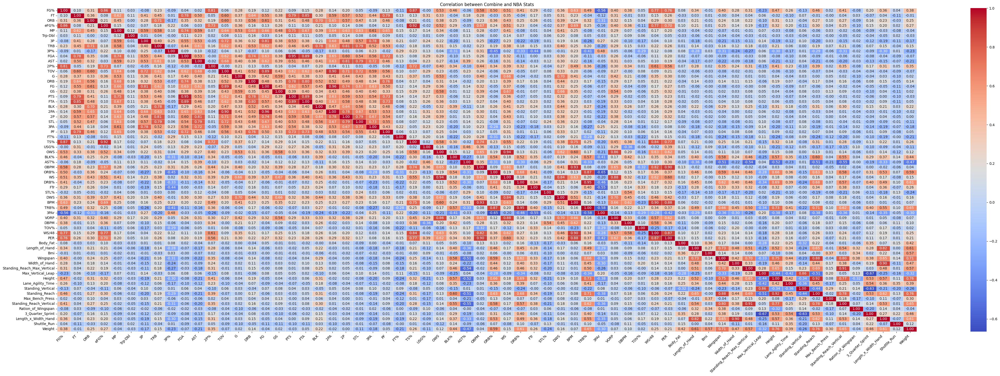

In [63]:
plt.figure(figsize=(45, 15))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", 
            cmap="coolwarm", linewidths=0.5,
            xticklabels=correlation_matrix.columns,
            yticklabels=correlation_matrix.columns
            )

plt.title("Correlation between Combine and NBA Stats")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Correlation_between_Combine_and_NBA_Stats.png") 
plt.show()

In [64]:
# Drop self-correlations and flatten
corr_long = (
    correlation_matrix
    .unpivot(
        variable_name="Feature1",
        value_name="Correlation"
    ).with_columns([
        pl.repeat(correlation_matrix.columns, correlation_matrix.height).explode().alias("Feature2")
    ])

)
corr_filtered = (
    corr_long
    .filter(pl.col("Feature1") != pl.col("Feature2")) # remove self pairs
    .filter(pl.col("Feature1") < pl.col("Feature2")) # locks in on upper triangle
)

top_corr = corr_filtered.with_columns(
    pl.col("Correlation").abs().alias("AbsCorrelation")
)
# Absolute value and threshold
top_corr = top_corr.filter(top_corr["AbsCorrelation"] > 0.5)

top_corr

Feature1,Correlation,Feature2,AbsCorrelation
str,f64,str,f64
"""FG%""",0.861401,"""eFG%""",0.861401
"""FG%""",0.871056,"""TS%""",0.871056
"""FG%""",0.5251,"""OWS""",0.5251
"""FG%""",0.584252,"""OBPM""",0.584252
"""FG%""",0.510306,"""WS""",0.510306
…,…,…,…
"""Length_x_Width_Hand""",0.897109,"""Width_of_Hand""",0.897109
"""Length_x_Width_Hand""",0.618537,"""Standing_Reach""",0.618537
"""Length_x_Width_Hand""",0.526227,"""Standing_Reach_Vertical""",0.526227


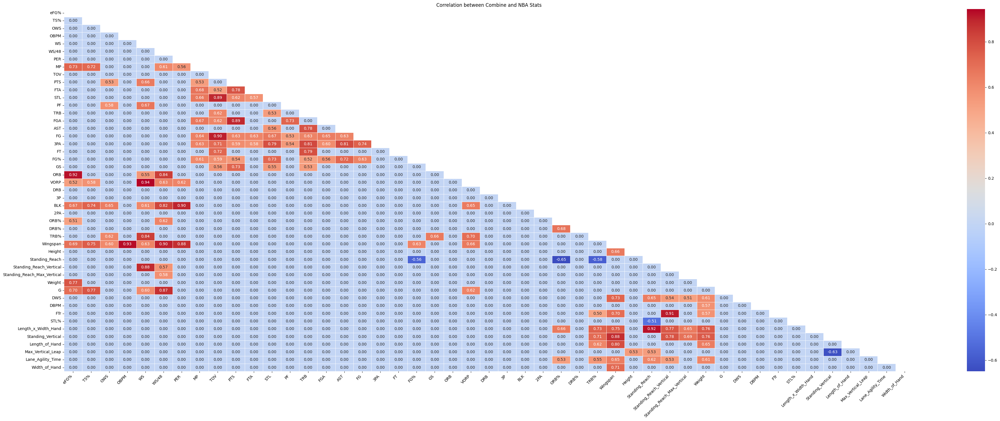

In [65]:
pivot_corr = top_corr.pivot(index="Feature1", on="Feature2", values="Correlation").drop("Feature1")
pivot_corr = pivot_corr.fill_null(0)
mask = np.triu(np.ones_like(pivot_corr, dtype=bool))

plt.figure(figsize=(40, 15))
sns.heatmap(pivot_corr, annot=True, fmt=".2f", 
            cmap="coolwarm", linewidths=0.5,
            xticklabels=pivot_corr.columns,
            yticklabels=pivot_corr.columns,
            mask=mask
            )

plt.title("Correlation between Combine and NBA Stats")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Correlation_between_Combine_and_NBA_Stats_50pct_Threshold.png")
plt.show()

In [66]:
combine_wide.columns

['Player_Season',
 'Body_Fat',
 'Length_of_Hand',
 'Bmi',
 'Wingspan',
 'Width_of_Hand',
 'Standing_Reach_Max_Vertical',
 'Max_Vertical_Leap',
 'Height',
 'Lane_Agility_Time',
 'Standing_Vertical',
 'Standing_Reach',
 'Max_Bench_Press',
 'Standing_Reach_Vertical',
 'Ration_of_Wingspan',
 '3_Quarter_Sprint',
 'Length_x_Width_Hand',
 'Shuttle_Run',
 'Weight']

In [67]:
top_10_corr = top_corr.filter(
    pl.col("Feature2").is_in(combine_wide.columns) & ~pl.col("Feature1").is_in(combine_wide.columns)
).sort("AbsCorrelation", descending=True).head(10)
top_10_corr

Feature1,Correlation,Feature2,AbsCorrelation
str,f64,str,f64
"""DRB%""",0.690049,"""Height""",0.690049
"""DRB%""",0.675119,"""Standing_Reach""",0.675119
"""TRB%""",0.66212,"""Wingspan""",0.66212
"""TRB%""",0.654096,"""Weight""",0.654096
"""ORB%""",0.627057,"""Standing_Reach""",0.627057
"""DRB%""",0.621384,"""Wingspan""",0.621384
"""DRB%""",0.611113,"""Weight""",0.611113
"""BLK%""",0.604842,"""Standing_Reach""",0.604842
"""ORB%""",0.593768,"""Wingspan""",0.593768


# Visualizing Relationships Between NBA Combine and NBA Performance Stats

This section explores how physical attributes measured at the NBA Draft Combine relate to key NBA performance metrics. Using scatterplots and pairplots, we visualize the strongest correlations between combine stats (such as Height, Wingspan, Standing Reach, and Weight) and NBA outcomes (including Total Rebound %, Defensive Rebound %, Offensive Rebound %, and Block %).

**Key analyses include:**
- Pairwise scatterplots for the top 10 most correlated combine/NBA stat pairs.
- Regression lines and correlation coefficients to highlight linear relationships.
- Focused scatterplots for specific relationships, such as Height vs. Defensive Rebound %, Standing Reach vs. Defensive Rebound %, and Total Rebound % vs. Height.

These visualizations help reveal which physical traits are most predictive of NBA performance, providing actionable insights for scouting and player development.

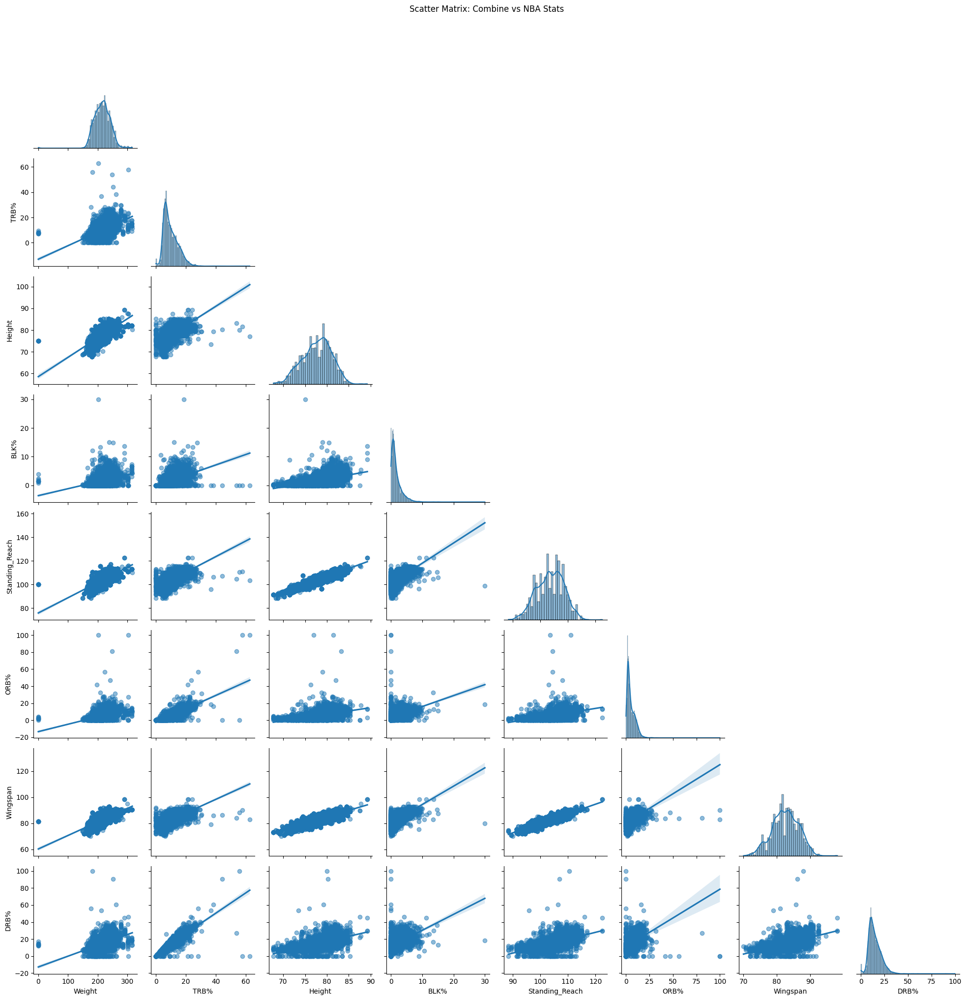

In [68]:
def corrfunc(x, y, **kws):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.annotate(f"r = {r:.2f}", xy=(.5, .5), xycoords=ax.transAxes,
                ha='center', va='center', fontsize=10)


# Make a pairplot between top 10 correlated features
features_to_plot = (
    pl.concat([
        top_10_corr["Feature1"].alias("value"),
        top_10_corr["Feature2"].alias("value")
    ], how="vertical")
    .unique()
    .to_list()
)

g = sns.PairGrid(combined_wide[features_to_plot].to_pandas(), corner=True)
g.map_lower(sns.regplot, scatter_kws={'alpha': 0.5})
g.map_diag(sns.histplot, kde=True)
g.map_upper(corrfunc)
plt.suptitle("Scatter Matrix: Combine vs NBA Stats", y=1.02)
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Scatter_Matrix_Combine_vs_NBA_Stats.png")
plt.show()

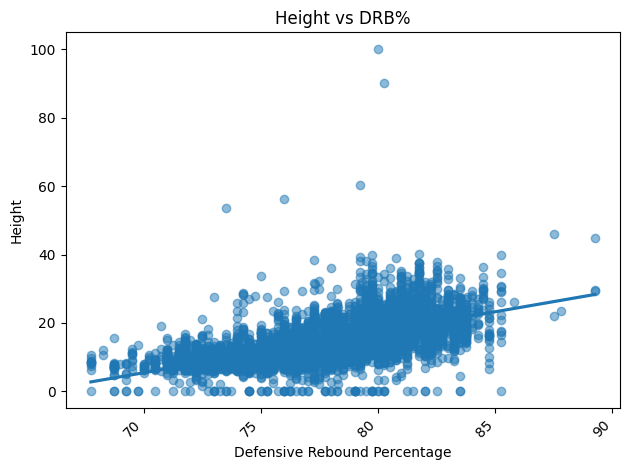

In [69]:
sns.regplot(data=combined_wide, x="Height", y="DRB%", scatter_kws={"alpha":0.5})
plt.title("Height vs DRB%")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.ylabel("Height")
plt.xlabel("Defensive Rebound Percentage")
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Height_vs_DRB_Percentage.png")
plt.show()


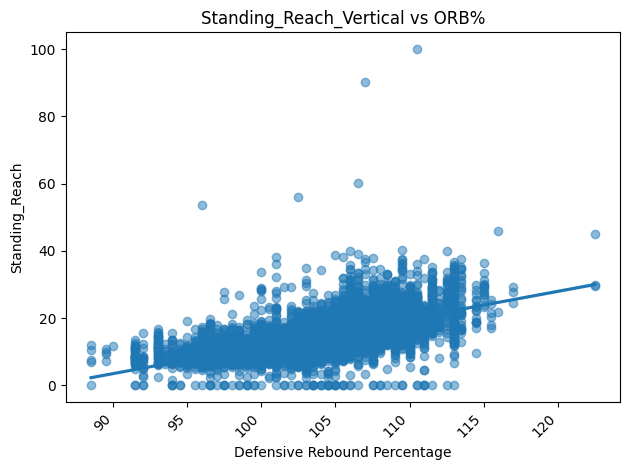

In [70]:
sns.regplot(data=combined_wide, x="Standing_Reach", y="DRB%", scatter_kws={"alpha":0.5})
plt.title("Standing_Reach_Vertical vs ORB%")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.ylabel("Standing_Reach")
plt.xlabel("Defensive Rebound Percentage")
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Standing_Reach_vs_DRB_Percentage.png")
plt.show()

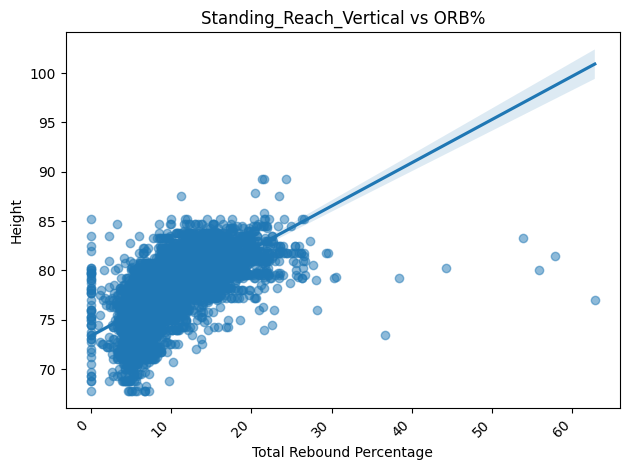

In [71]:
sns.regplot(data=combined_wide, x="TRB%", y="Height", scatter_kws={"alpha":0.5})
plt.title("Standing_Reach_Vertical vs ORB%")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.ylabel("Height")
plt.xlabel("Total Rebound Percentage")
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "TRB_Percentage_vs_Height.png")
plt.show()

# We have our columns that are strongly correlated! Let's dig deeper

We want to compare our physical attributes with top performers. Below, we use boxplots to visualize outliers and distributions for key combine metrics that show strong correlations with NBA performance. Specifically, we focus on attributes like Wingspan, Height, Standing Reach, Weight, and their relationships with rebounding and block percentages (TRB%, DRB%, ORB%, BLK%).

The following analysis uses the `top_performers` dataframe, which includes players' combine stats and flags for "Height Above Median", "Wingspan Above Median", "Standing Reach Above Median". By splitting the data on these flags, we can see how physical advantages translate to on-court performance.

Boxplots below illustrate:
- Block Percentage (BLK%) by Height Above Median
- Offensive Rebound Percentage (ORB%) by Height Above Median
- Defensive Rebound Percentage (DRB%) by Height Above Median
- Total Rebound Percentage (TRB%) by Height Above Median
- Defensive/Offensive/Total Rebound Percentage and Block Percentage by Wingspan Above Median
- Defensive/Offensive/Total Rebound Percentage and Block Percentage by Standing Reach Above Median

These visualizations help highlight how standout physical traits are associated with higher performance in key NBA metrics.

In [72]:
top_performers = combined_wide[features_to_plot + ["Player", "Season"]]
top_performers = top_performers.with_columns([
    (pl.col("Height") > top_performers["Height"].median()).alias("Height Above Median"),
    (pl.col("Wingspan") > top_performers["Wingspan"].median()).alias("Wingspan Above Median"),
    (pl.col("Standing_Reach") > top_performers["Standing_Reach"].median()).alias("Standing Reach Above Median"),
])

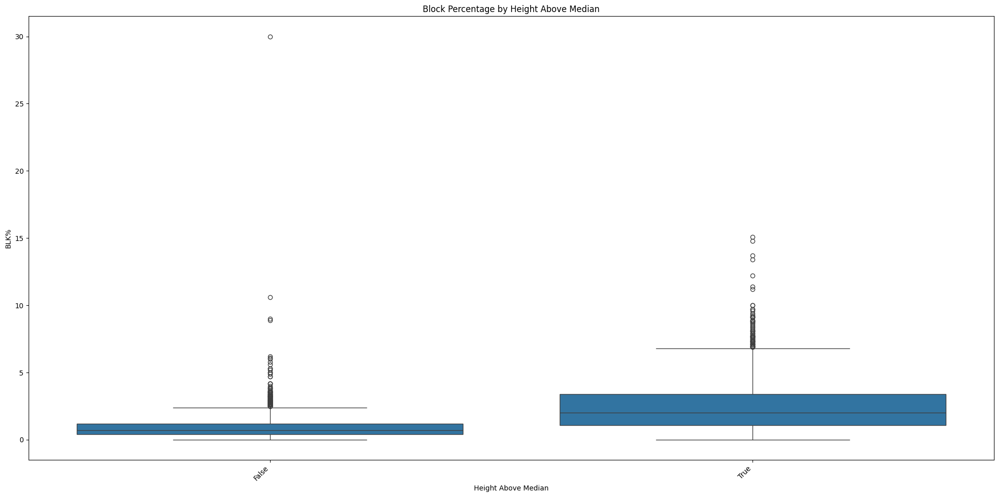

In [73]:
plt.figure(figsize=(20, 10))
sns.boxplot(x="Height Above Median", y="BLK%", data=top_performers.drop_nulls())
plt.title("Block Percentage by Height Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Block_Percentage_by_Height_Above_Median.png")
plt.show()

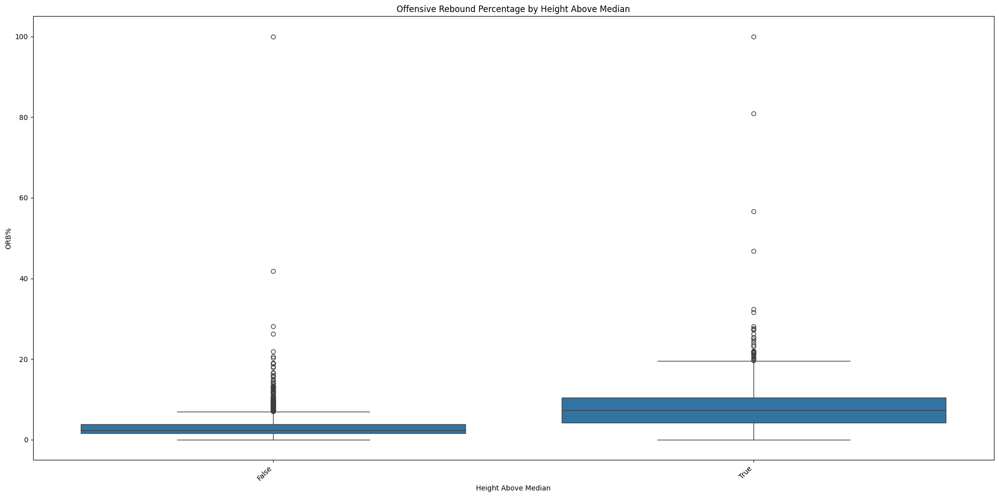

In [74]:
plt.figure(figsize=(20, 10))
sns.boxplot(x="Height Above Median", y="ORB%", data=top_performers.drop_nulls())
plt.title("Offensive Rebound Percentage by Height Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Offensive_Rebound_Percentage_by_Height_Above_Median.png")
plt.show()

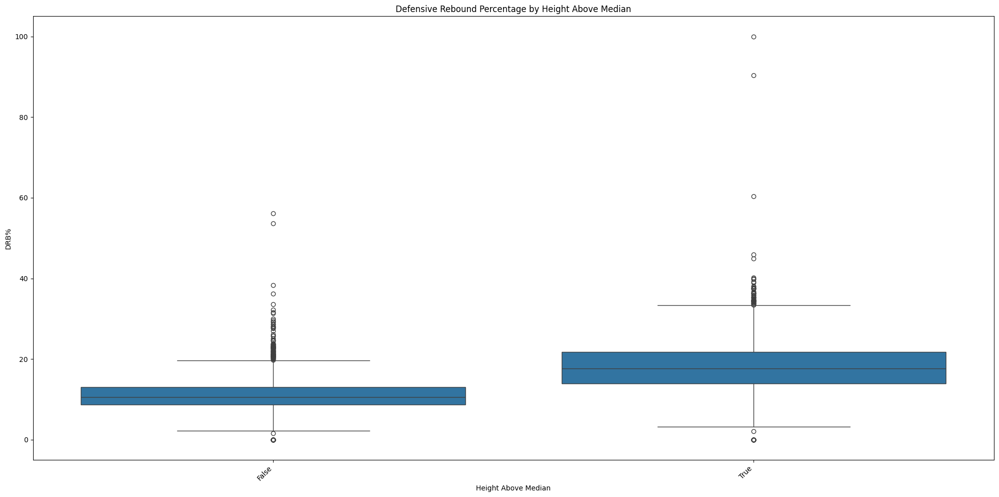

In [75]:
plt.figure(figsize=(20, 10))
sns.boxplot(x="Height Above Median", y="DRB%", data=top_performers.drop_nulls())
plt.title("Defensive Rebound Percentage by Height Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Defensive_Rebound_Percentage_by_Height_Above_Median.png")
plt.show()

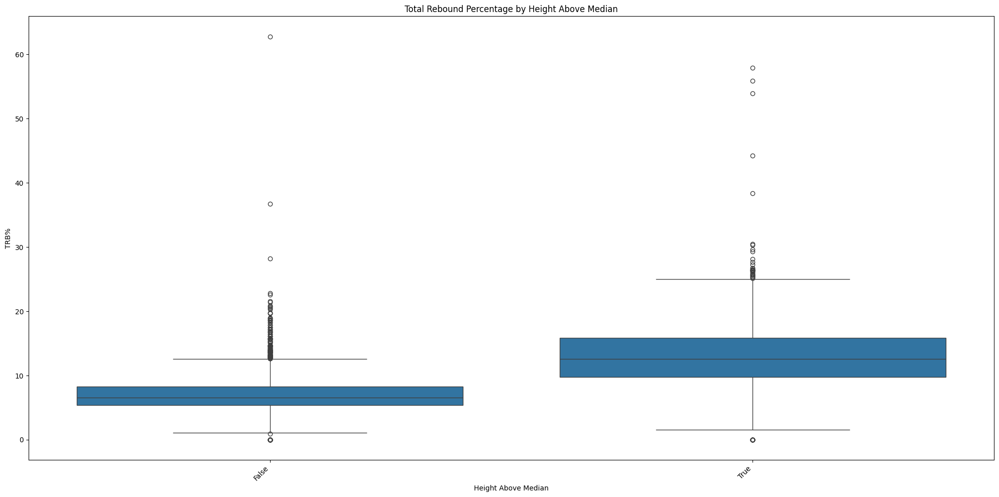

In [76]:
plt.figure(figsize=(20, 10))
sns.boxplot(x="Height Above Median", y="TRB%", data=top_performers.drop_nulls())
plt.title("Total Rebound Percentage by Height Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Total_Rebound_Percentage_by_Height_Above_Median.png")
plt.show()

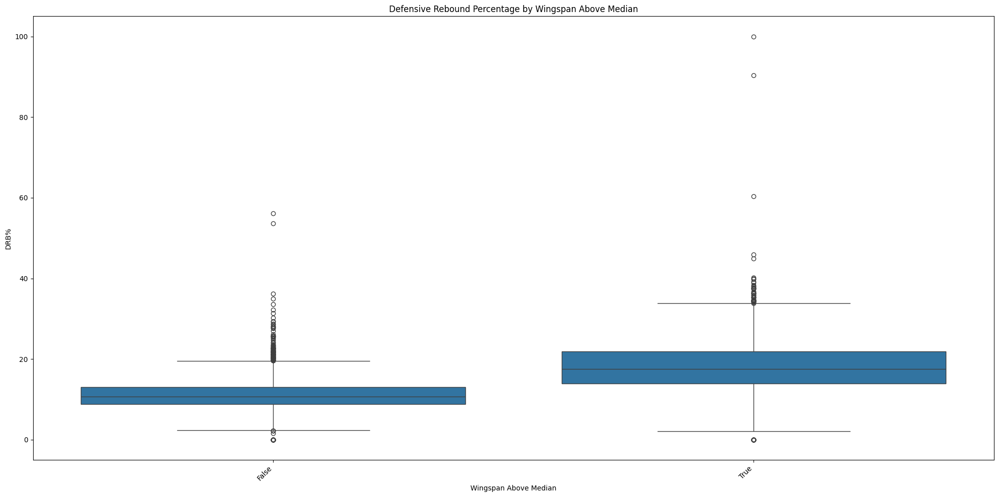

In [77]:
plt.figure(figsize=(20, 10))
sns.boxplot(x="Wingspan Above Median", y="DRB%", data=top_performers.drop_nulls())
plt.title("Defensive Rebound Percentage by Wingspan Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Defensive_Rebound_Percentage_by_Wingspan_Above_Median.png")
plt.show()

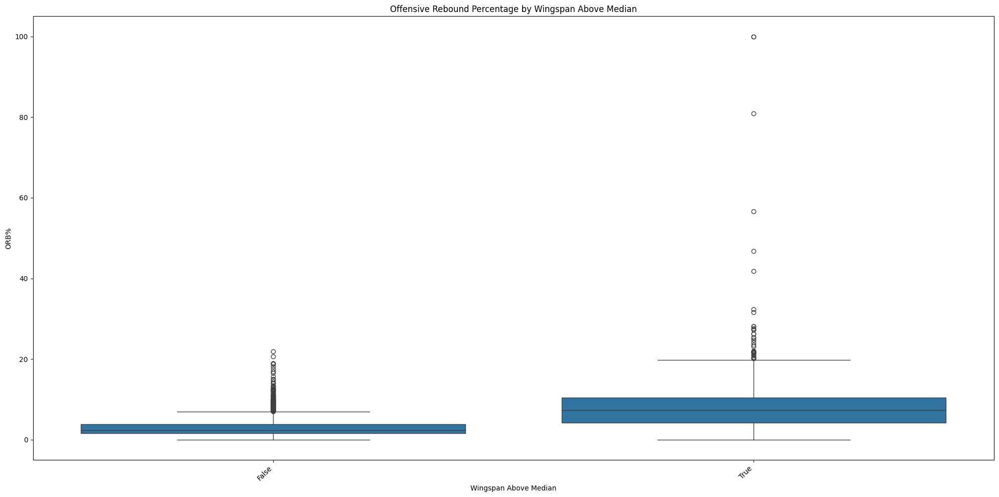

In [78]:
plt.figure(figsize=(20, 10))
sns.boxplot(x="Wingspan Above Median", y="ORB%", data=top_performers.drop_nulls())
plt.title("Offensive Rebound Percentage by Wingspan Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Offensive_Rebound_Percentage_by_Wingspan_Above_Median.png")
plt.show()

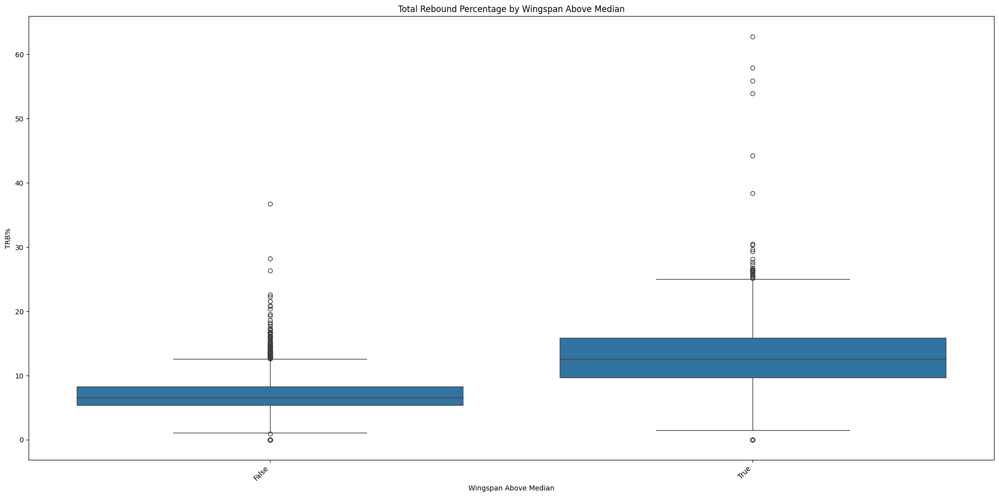

In [79]:
plt.figure(figsize=(20, 10))
sns.boxplot(x="Wingspan Above Median", y="TRB%", data=top_performers.drop_nulls())
plt.title("Total Rebound Percentage by Wingspan Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Total_Rebound_Percentage_by_Wingspan_Above_Median.png")
plt.show()

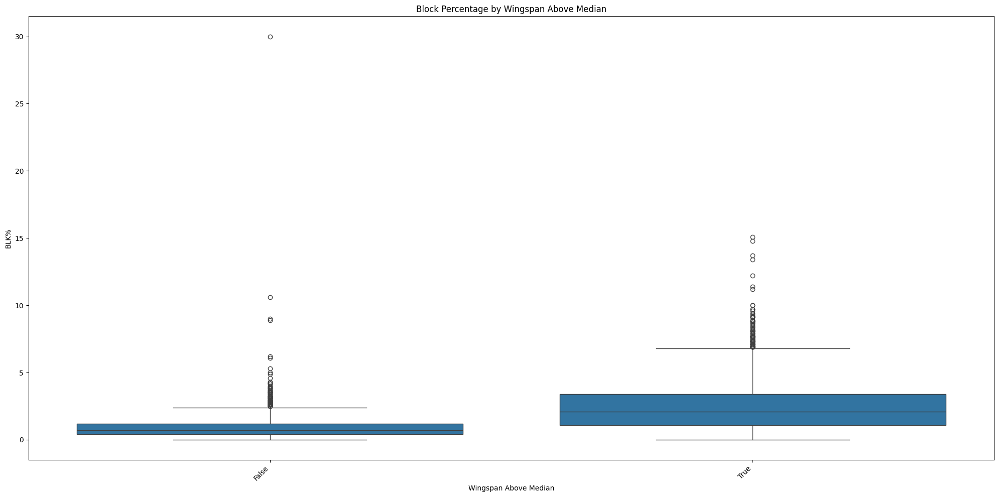

In [80]:
plt.figure(figsize=(20, 10))
sns.boxplot(x="Wingspan Above Median", y="BLK%", data=top_performers.drop_nulls())
plt.title("Block Percentage by Wingspan Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Block_Percentage_by_Wingspan_Above_Median.png")
plt.show()

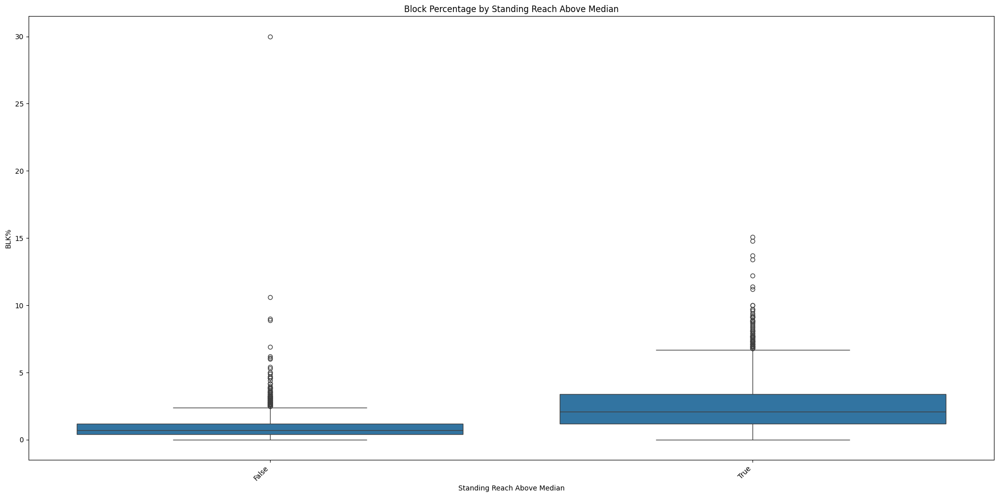

In [81]:
plt.figure(figsize=(20, 10))
sns.boxplot(x="Standing Reach Above Median", y="BLK%", data=top_performers.drop_nulls())
plt.title("Block Percentage by Standing Reach Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Block_Percentage_by_Standing_Reach_Above_Median.png")
plt.show()

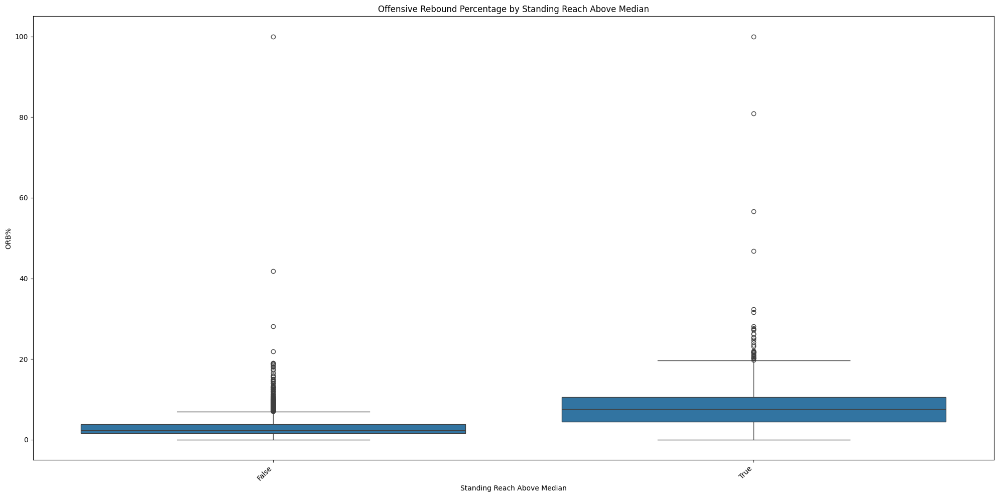

In [82]:
plt.figure(figsize=(20, 10))
sns.boxplot(x="Standing Reach Above Median", y="ORB%", data=top_performers.drop_nulls())
plt.title("Offensive Rebound Percentage by Standing Reach Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Offensive_Rebound_Percentage_by_Standing_Reach_Above_Median.png")
plt.show()

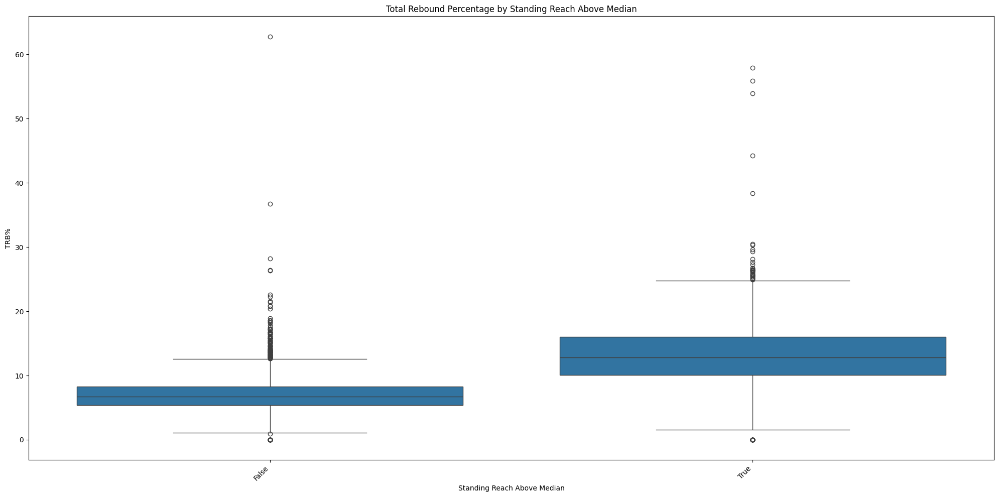

In [83]:
plt.figure(figsize=(20, 10))
sns.boxplot(x="Standing Reach Above Median", y="TRB%", data=top_performers.drop_nulls())
plt.title("Total Rebound Percentage by Standing Reach Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Total_Rebound_Percentage_by_Standing_Reach_Above_Median.png")
plt.show()

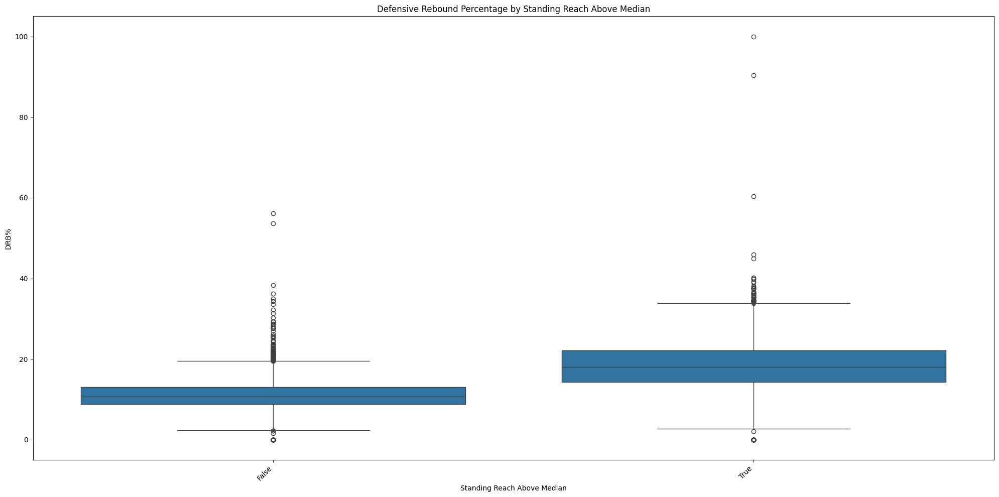

In [84]:
plt.figure(figsize=(20, 10))
sns.boxplot(x="Standing Reach Above Median", y="DRB%", data=top_performers.drop_nulls())
plt.title("Defensive Rebound Percentage by Standing Reach Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"bivariate_nba"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Defensive_Rebound_Percentage_by_Standing_Reach_Above_Median.png")
plt.show()

## Time to Compare with NBA Awards

Below we make some boxplots to see how the physical combine stats relate to the NBA awards.

We will visualize how key combine metrics (Height, Wingspan, Standing Reach, Weight) are distributed among players who received NBA accolades such as All-Star selections, All-NBA Team, Defensive Team, and MVP/DPOY rankings. These plots help reveal whether standout physical attributes are associated with higher chances of earning major NBA honors.

The following analysis uses the `combined_award` dataframe, which merges combine stats with award indicators for each player-season. For each award category, we compare the distributions of combine metrics between award recipients and non-recipients using boxplots.

**Key questions addressed:**
- Do All-Stars tend to have higher combine measurements?
- Are Defensive Team or All-NBA Team members physically different from the rest?
- How do MVP and DPOY rankings relate to combine stats?

This section provides a visual summary of how physical traits may influence or correlate with NBA recognition.

In [85]:
awards = df.collect().select([
    "Player", "Season", "AllStar", "Defense_Team", "MVP_Rank", "All_NBA_Team", "DPOY_Rank"
]).unique(subset=["Player", "Season"])

combined_award = combined_wide.join(awards, on=["Player", "Season"], how="left")
combined_award

FG%,FT,ORB,eFG%,MP,Trp-Dbl,3P,TRB,3P%,FGA,AST,2P%,TOV,G,DRB,FG,GS,PTS,FTA,BLK,2PA,2P,STL,3PA,PF,FT%,TS%,USG%,OWS,BLK%,AST%,OBPM,ORB%,WS,DRB%,FTr,STL%,DWS,BPM,TRB%,3PAr,VORP,DBPM,TOV%,WS/48,PER,Body_Fat,Length_of_Hand,Bmi,Wingspan,Width_of_Hand,Standing_Reach_Max_Vertical,Max_Vertical_Leap,Height,Lane_Agility_Time,Standing_Vertical,Standing_Reach,Max_Bench_Press,Standing_Reach_Vertical,Ration_of_Wingspan,3_Quarter_Sprint,Length_x_Width_Hand,Shuttle_Run,Weight,Player,Season,AllStar,Defense_Team,MVP_Rank,All_NBA_Team,DPOY_Rank
f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,str,str,bool,i32,i32,i32,i32
0.511,44.0,32.0,0.534,267.0,0.0,4.0,2.3,0.308,88.0,0.6,0.547,18.0,37.0,53.0,45.0,2.0,138.0,60.0,0.2,75.0,1.1,0.2,0.4,42.0,0.733,0.603,20.700001,0.6,2.9,11.9,-0.7,12.5,1.0,21.799999,0.682,1.2,0.3,-0.6,17.1,0.148,0.1,0.1,13.6,0.171,18.700001,0.082,9.0,25.799999,86.0,9.5,141.0,31.5,80.0,11.56,23.0,109.5,null,132.5,1.075,3.31,85.5,2.96,235.0,"""Nathan Knight""","""2021-22""",false,0,0,0,0
0.561,12.0,30.0,0.561,195.0,0.0,0.0,64.0,null,57.0,22.0,0.561,12.0,14.0,34.0,32.0,0.0,76.0,23.0,10.0,57.0,32.0,8.0,0.0,24.0,0.522,0.566,17.299999,0.4,4.8,16.200001,-0.3,16.9,0.7,18.799999,0.404,2.0,0.3,0.4,17.700001,0.0,0.1,0.7,15.2,0.169,19.5,0.112,8.75,25.9,86.25,9.5,137.5,29.0,81.75,12.1,25.0,108.5,15.0,133.5,1.055,3.35,83.099998,null,246.600006,"""Greg Monroe""","""2021-22""",false,0,0,0,0
0.459,126.0,38.0,0.528,1564.0,0.0,1.8,224.0,0.391,617.0,177.0,0.496,81.0,49.0,186.0,283.0,48.0,778.0,149.0,22.0,397.0,197.0,47.0,220.0,85.0,0.846,0.57,20.700001,1.9,1.3,16.1,0.1,2.5,2.8,12.8,0.241,1.4,1.0,-0.7,7.6,0.357,0.5,-0.8,10.6,0.087,15.1,0.069,8.5,23.9,79.75,9.3,137.5,34.5,78.75,11.73,30.5,103.0,10.0,133.5,1.013,3.22,78.599998,null,211.0,"""Gordon Hayward""","""2021-22""",false,0,0,0,0
0.474,8.0,17.0,0.531,298.0,0.0,13.0,45.0,0.333,114.0,23.0,0.547,20.0,17.0,28.0,54.0,1.0,129.0,9.0,1.0,75.0,41.0,6.0,39.0,33.0,0.889,0.547,20.6,0.0,0.4,12.1,-1.5,6.6,0.3,10.5,0.079,1.0,0.3,-1.9,8.6,0.342,0.0,-0.4,14.5,0.054,10.9,0.102,8.5,26.6,82.75,8.3,138.0,31.5,79.75,null,27.0,106.5,11.0,133.5,1.038,3.4,70.099998,null,240.800003,"""Markieff Morris""","""2021-22""",false,0,0,0,0
0.489,53.0,47.0,0.517,1015.0,0.0,18.0,164.0,0.277,319.0,44.0,0.543,41.0,63.0,117.0,156.0,13.0,383.0,75.0,18.0,254.0,138.0,31.0,65.0,1.7,0.707,0.544,17.1,0.4,1.6,6.5,-3.2,5.2,1.6,12.5,0.235,1.5,1.2,-2.9,8.9,0.204,-0.2,0.3,10.4,0.078,11.3,0.068,8.5,26.5,81.0,9.8,142.0,41.0,77.75,10.35,35.0,101.0,null,136.0,1.042,3.2,82.900002,2.54,228.0,"""Lamar Stevens""","""2021-22""",false,0,0,0,0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.451,144.0,72.0,0.517,1872.0,0.0,117.0,211.0,0.374,883.0,114.0,0.493,76.0,73.0,139.0,398.0,17.0,1057.0,177.0,11.0,570.0,281.0,58.0,313.0,127.0,0.814,0.55,25.299999,3.1,0.4,10.3,2.3,4.4,4.0,8.9,0.2,1.6,0.9,0.9,6.6,0.354,1.4,-1.4,7.3,0.103,17.4,0.053,8.25,22.9,79.75,8.5,140.5,43.0,73.75,10.78,34.5,97.5,3.0,132.0,1.081,3.02,70.099998,2.88,177.399994,"""Marcus Thornton""","""2009-10""",false,0,0,0,0
0.373,68.0,28.0,0.472,2072.0,0.0,90.0,178.0,0.349,451.0,378.0,0.404,110.0,67.0,150.0,168.0,59.0,494.0,95.0,3.0,193.0,78.0,59.0,258.0,83.0,0.716,0.501,13.1,1.5,0.1,25.9,-1.2,1.5,1.9,8.4,0.211,1.5,0.5,-2.5,4.9,0.572,-0.3,-1.3,18.200001,0.045,10.7,0.067,null,26.200001,78.5,null,133.0,35.0,72.0,10.45,31.5,98.0,7.0,129.5,1.09,3.14,null,null,193.0,"""Chris Duhon""","""2009-10""",false,0,0,0,0
0.409,122.0,39.0,0.493,2702.0,0.0,145.0,240.0,0.336,870.0,1.4,0.482,79.0,82.0,201.0,356.0,64.0,979.0,145.0,68.0,438.0,2.6,36.0,432.0,121.0,0.841,0.524,17.0,1.8,1.9,6.8,-0.8,1.7,2.7,8.7,0.167,0.7,0.9,-1.9,5.1,0.497,0.1,-1.1,7.8,0.048,10.7,null,null,22.4,84.0,null,143.0,37.5,78.75,11.54,31.5,105.5,10.0,13

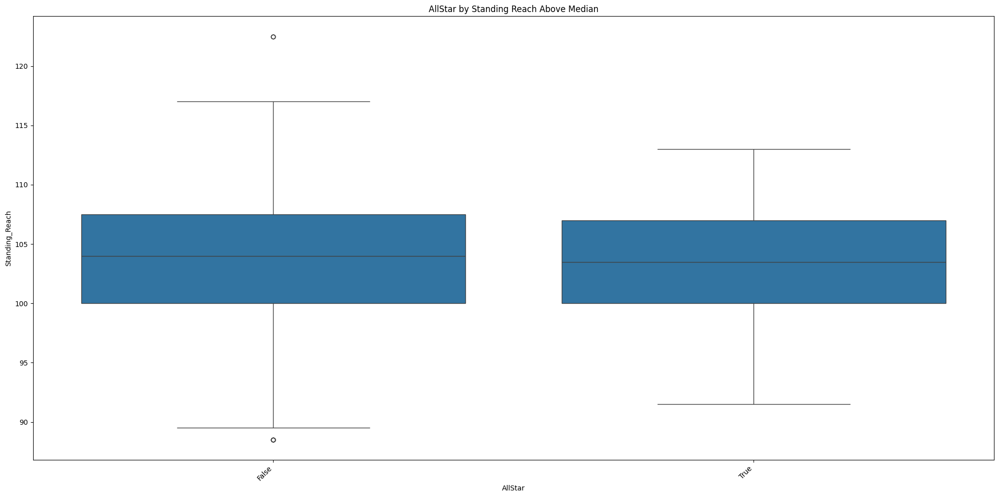

In [86]:
plt.figure(figsize=(20, 10))
sns.boxplot(x="AllStar", y="Standing_Reach", data=combined_award)
plt.title("AllStar by Standing Reach Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "AllStar_by_Standing_Reach_Above_Median.png")
plt.show()

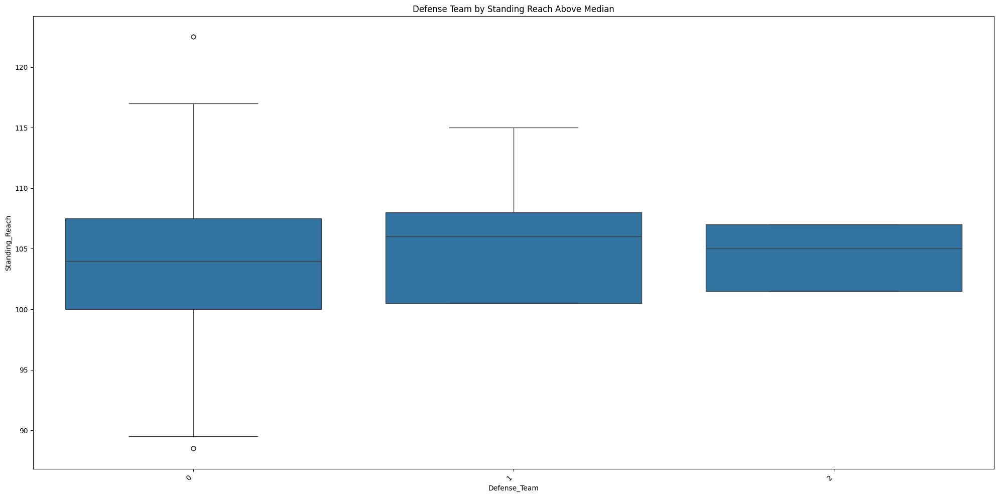

In [87]:
plt.figure(figsize=(20, 10))
sns.boxplot(x="Defense_Team", y="Standing_Reach", data=combined_award)
plt.title("Defense Team by Standing Reach Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Defense_Team_by_Standing_Reach_Above_Median.png")
plt.show()

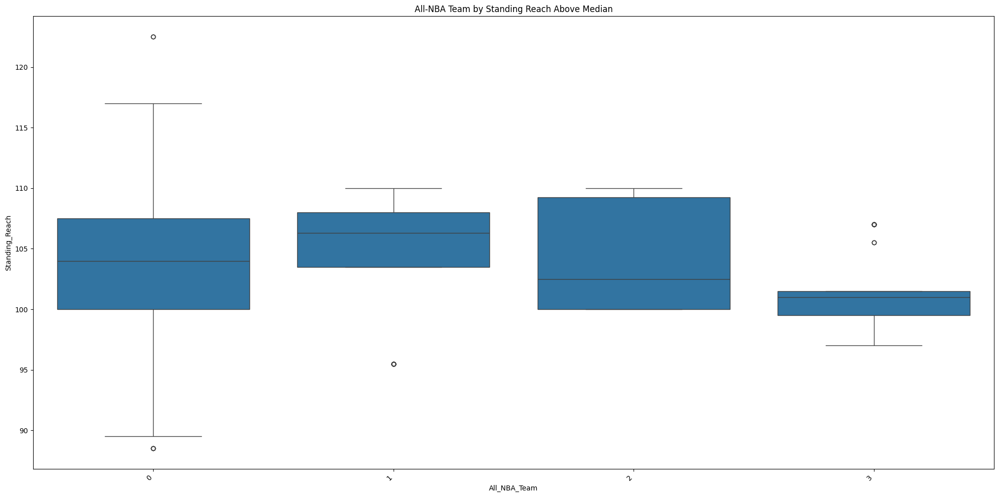

In [88]:
plt.figure(figsize=(20, 10))
sns.boxplot(x="All_NBA_Team", y="Standing_Reach", data=combined_award)
plt.title("All-NBA Team by Standing Reach Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "All_NBA_Team_by_Standing_Reach_Above_Median.png")
plt.show()

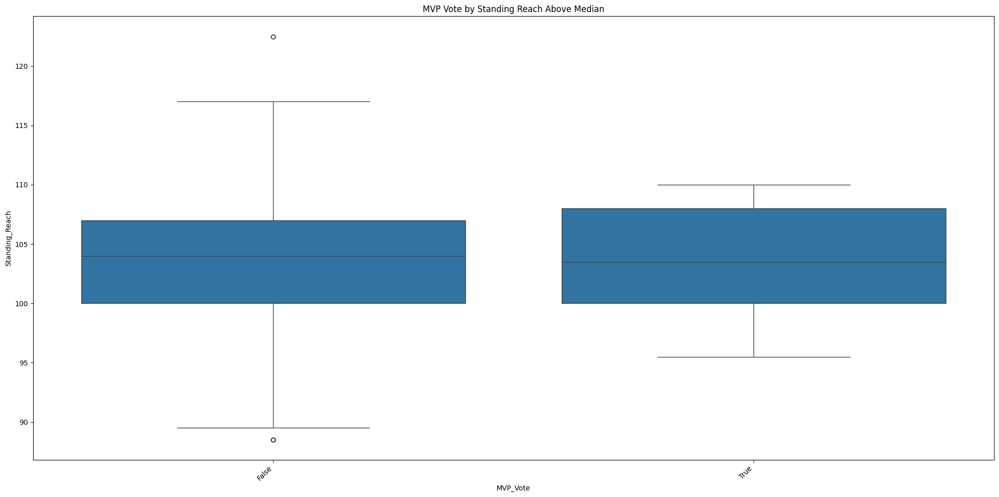

In [89]:
plt.figure(figsize=(20, 10))
temp = combined_award.with_columns(
    (pl.col("MVP_Rank") > 0).alias("MVP_Vote")
)
sns.boxplot(x="MVP_Vote", y="Standing_Reach", data=temp)
plt.title("MVP Vote by Standing Reach Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"nba_awards"
temp.mkdir(parents=True, exist_ok=True)
plt.savefig(temp / "MVP_Vote_by_Standing_Reach_Above_Median.png")
plt.show()

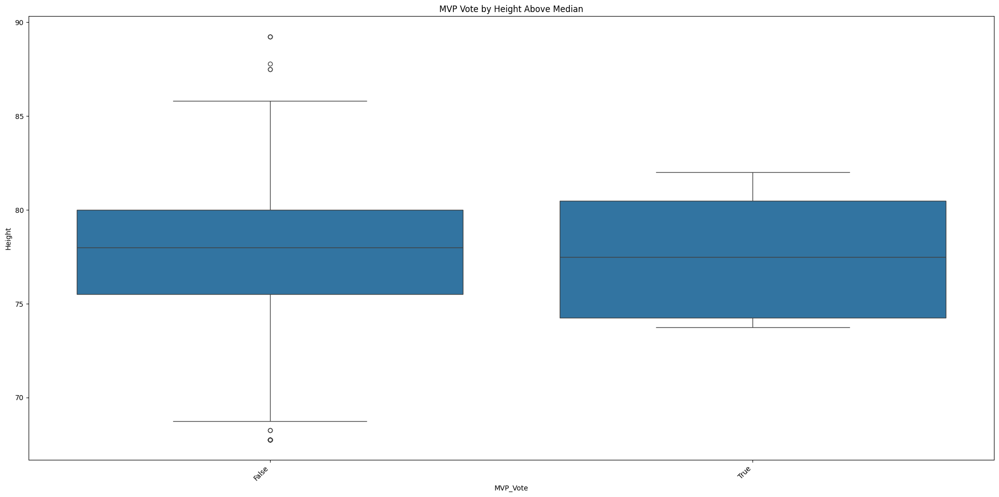

In [90]:
plt.figure(figsize=(20, 10))
temp = combined_award.with_columns(
    (pl.col("MVP_Rank") > 0).alias("MVP_Vote")
)
sns.boxplot(x="MVP_Vote", y="Height", data=temp)
plt.title("MVP Vote by Height Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "MVP_Vote_by_Height_Above_Median.png")
plt.show()

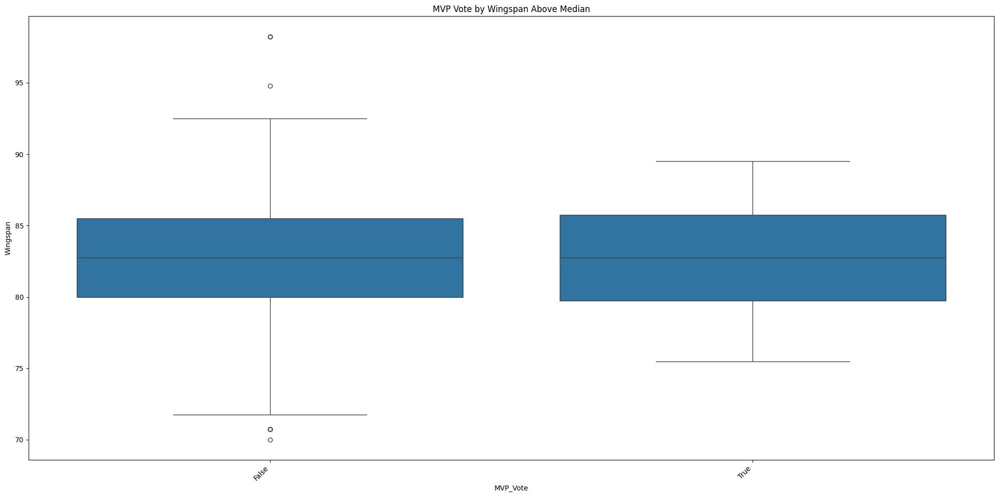

In [91]:
plt.figure(figsize=(20, 10))
temp = combined_award.with_columns(
    (pl.col("MVP_Rank") > 0).alias("MVP_Vote")
)
sns.boxplot(x="MVP_Vote", y="Wingspan", data=temp)
plt.title("MVP Vote by Wingspan Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "MVP_Vote_by_Wingspan_Above_Median.png")
plt.show()

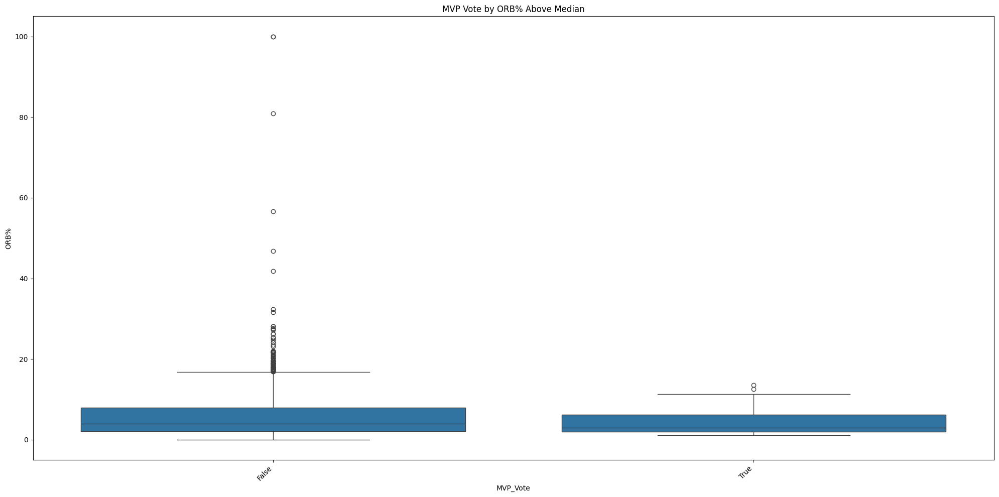

In [92]:
plt.figure(figsize=(20, 10))
temp = combined_award.with_columns(
    (pl.col("MVP_Rank") > 0).alias("MVP_Vote")
)
sns.boxplot(x="MVP_Vote", y="ORB%", data=temp)
plt.title("MVP Vote by ORB% Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "MVP_Vote_by_ORB%_Above_Median.png")
plt.show()

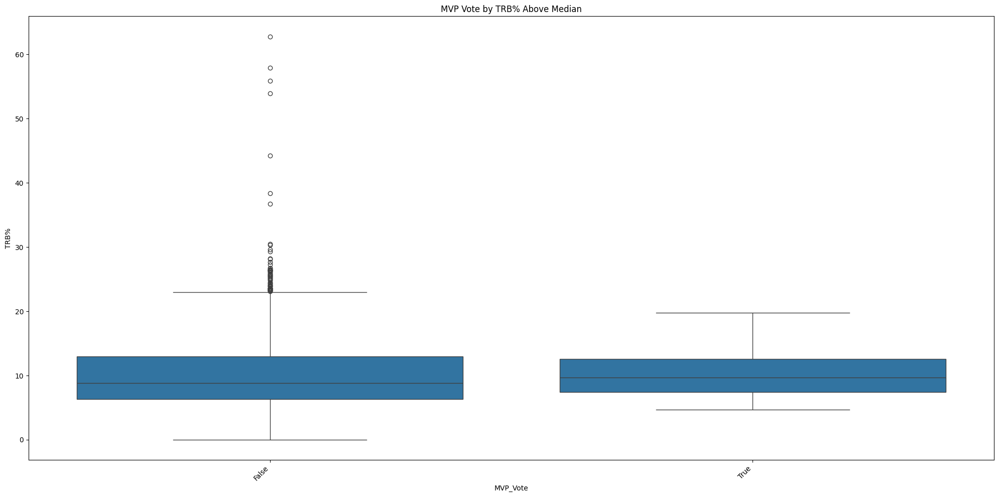

In [93]:
plt.figure(figsize=(20, 10))
temp = combined_award.with_columns(
    (pl.col("MVP_Rank") > 0).alias("MVP_Vote")
)
sns.boxplot(x="MVP_Vote", y="TRB%", data=temp)
plt.title("MVP Vote by TRB% Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "MVP_Vote_by_TRB%_Above_Median.png")
plt.show()

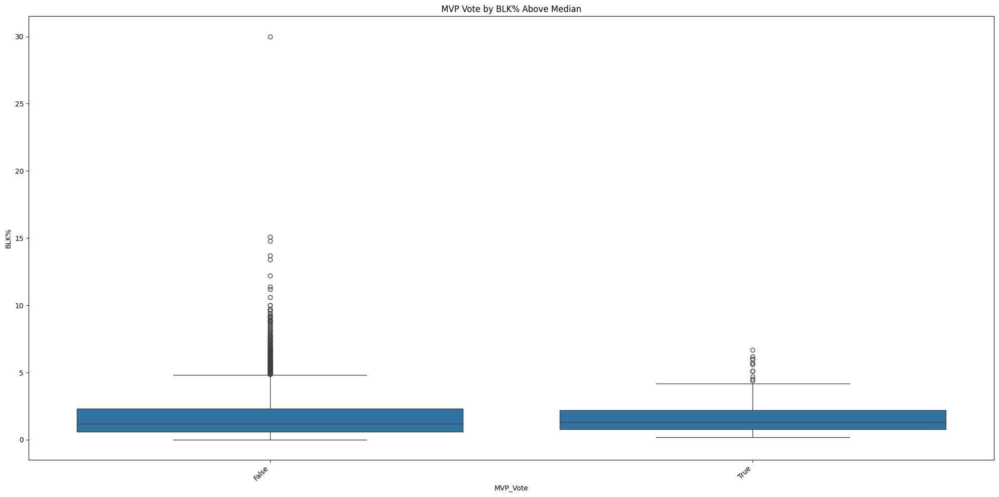

In [94]:
plt.figure(figsize=(20, 10))
temp = combined_award.with_columns(
    (pl.col("MVP_Rank") > 0).alias("MVP_Vote")
)
sns.boxplot(x="MVP_Vote", y="BLK%", data=temp)
plt.title("MVP Vote by BLK% Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "MVP_Vote_by_BLK%_Above_Median.png")
plt.show()

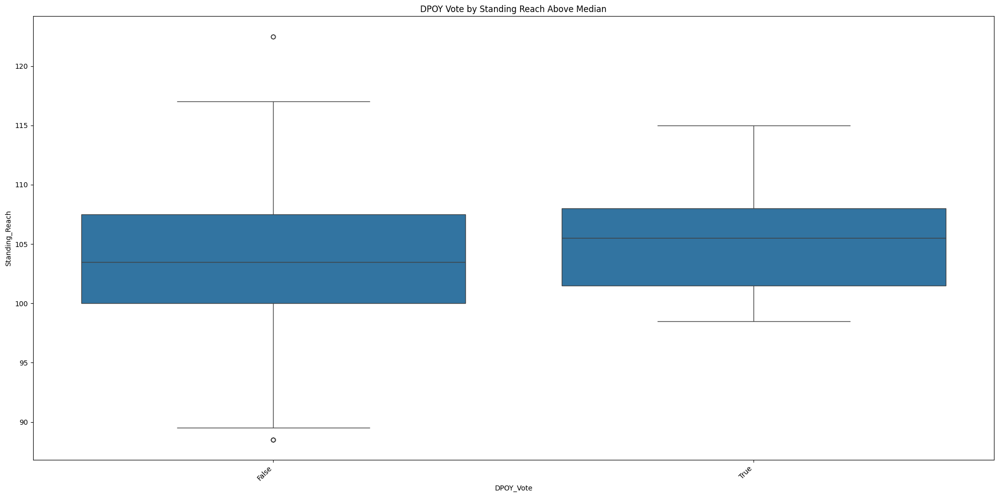

In [95]:
plt.figure(figsize=(20, 10))
temp = combined_award.with_columns(
    (pl.col("DPOY_Rank") > 0).alias("DPOY_Vote")
)
sns.boxplot(x="DPOY_Vote", y="Standing_Reach", data=temp)
plt.title("DPOY Vote by Standing Reach Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "DPOY_Vote_by_Standing_Reach_Above_Median.png")
plt.show()

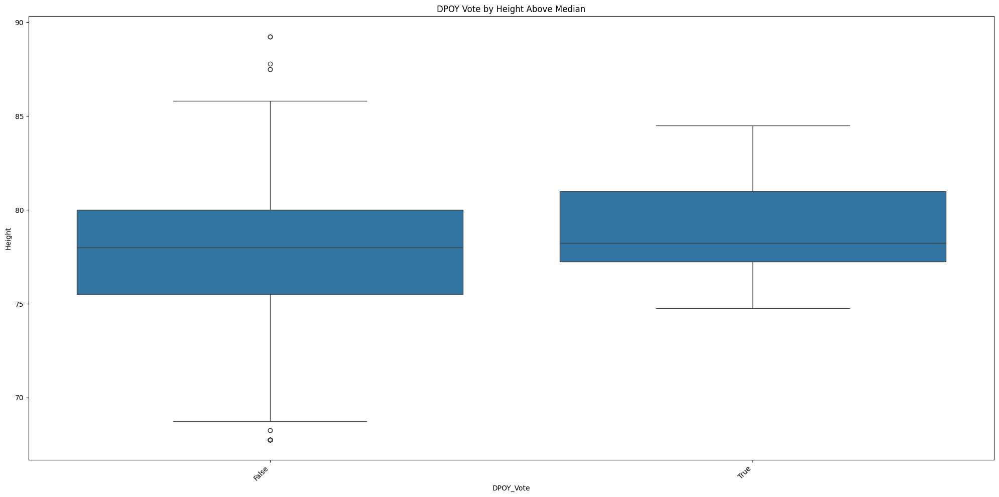

In [96]:
plt.figure(figsize=(20, 10))
temp = combined_award.with_columns(
    (pl.col("DPOY_Rank") > 0).alias("DPOY_Vote")
)
sns.boxplot(x="DPOY_Vote", y="Height", data=temp)
plt.title("DPOY Vote by Height Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "DPOY_Vote_by_Height_Above_Median.png")
plt.show()

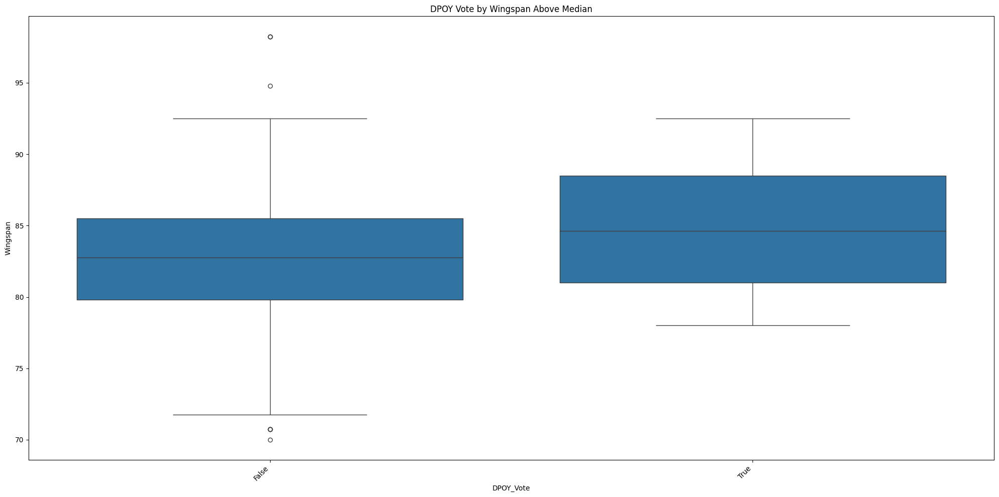

In [97]:
plt.figure(figsize=(20, 10))
temp = combined_award.with_columns(
    (pl.col("DPOY_Rank") > 0).alias("DPOY_Vote")
)
sns.boxplot(x="DPOY_Vote", y="Wingspan", data=temp)
plt.title("DPOY Vote by Wingspan Above Median")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
temp = visualization_path / f"nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "DPOY_Vote_by_Wingspan_Above_Median.png")
plt.show()

## Pairplot Analysis: NBA Awards, NBA Stats, and Combine Stats

Below, we use pairplots to visually explore the relationships between NBA Awards, NBA performance metrics, and NBA Combine physical attributes. This approach allows us to:

- Compare distributions and correlations among key combine stats (Height, Wingspan, Standing Reach, Weight) and NBA stats (TRB%, DRB%, ORB%, BLK%).
- Examine how award indicators (All-Star, All-NBA Team, Defensive Team, MVP/DPOY rankings) relate to both physical and performance metrics.
- Identify patterns and outliers among top performers and award recipients.

Pairplots provide a comprehensive view of how physical traits and on-court performance interact, and how these factors may influence the likelihood of earning major NBA accolades.

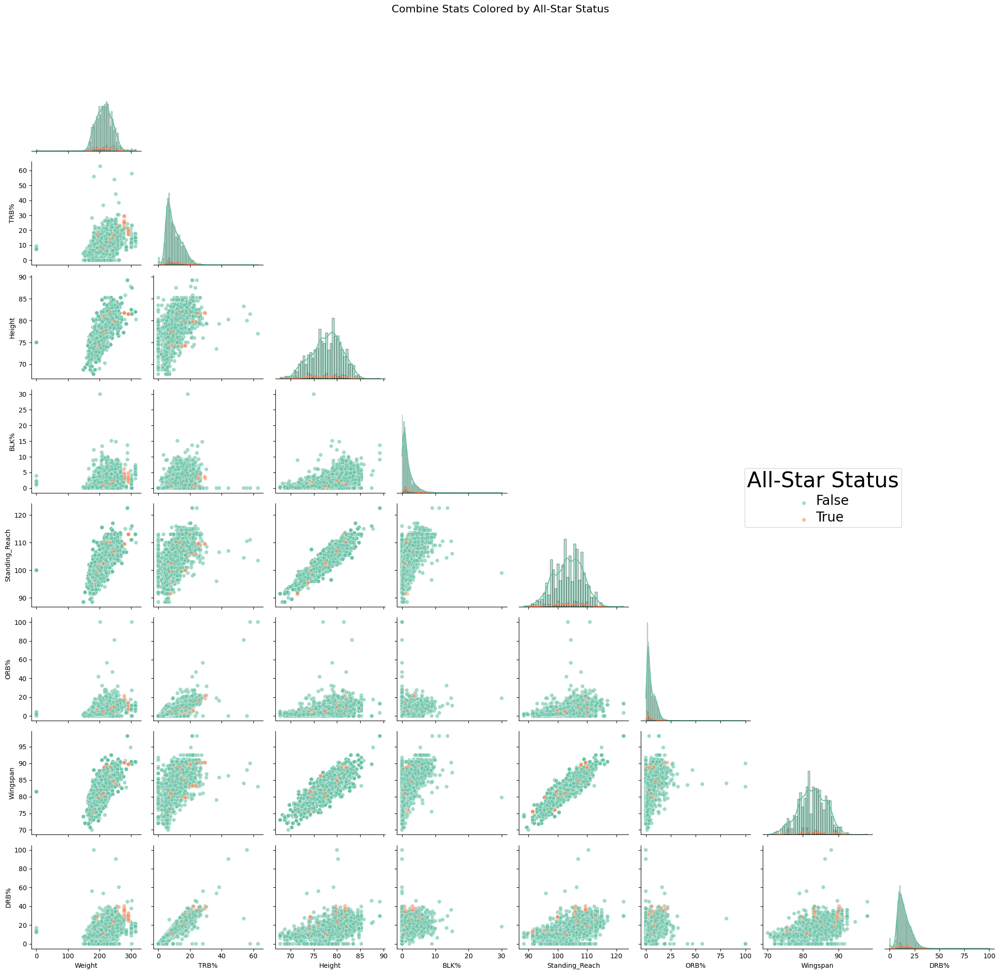

In [98]:
# Select combine stats + award
df_plot = combined_award.filter(pl.col("AllStar").is_not_null()).select(features_to_plot + ["AllStar"]).to_pandas()

# Convert AllStar to string for coloring
df_plot["AllStar"] = df_plot["AllStar"].astype(str)

# Create the PairGrid
g = sns.PairGrid(df_plot, vars=features_to_plot, hue="AllStar", palette="Set2", corner=True)
g.map_lower(sns.scatterplot, alpha=0.6)
g.map_diag(sns.histplot, kde=True)
g.add_legend(title="All-Star Status")
if g.legend:
    g.legend.set_bbox_to_anchor((0.9, 0.5))
    g.legend.set_frame_on(True)
    g.legend.set_title("All-Star Status", prop={'size': 32})
    for text in g.legend.get_texts():
        text.set_fontsize(20)

plt.suptitle("Combine Stats Colored by All-Star Status", y=1.02, fontsize=16)
plt.tight_layout()
temp = visualization_path / "nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "PairGrid_Combine_Stats_AllStar_Status.png")
plt.show()


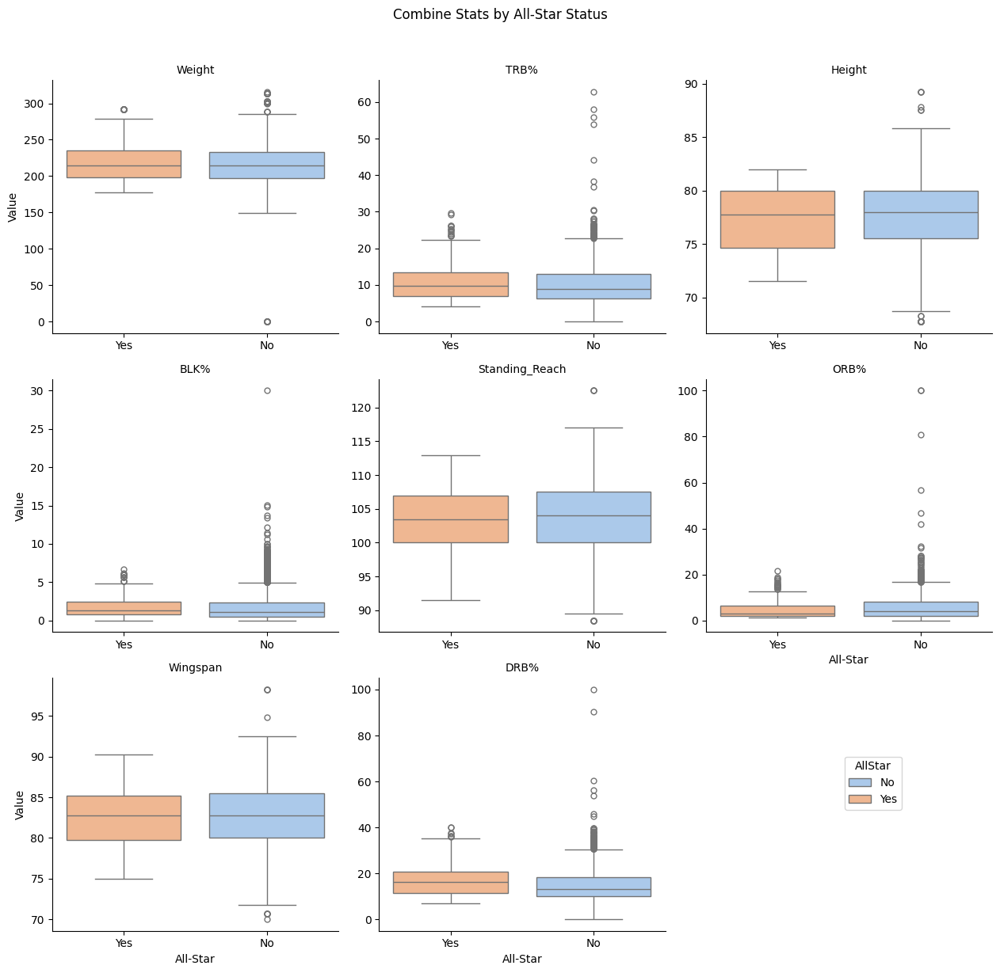

In [99]:

# Select combine stats and AllStar flag
df_plot = combined_award.select(features_to_plot + ["AllStar"]).to_pandas()
df_plot["AllStar"] = df_plot["AllStar"].map({True: "Yes", False: "No"})

# Melt to long format for faceting
df_melted = df_plot.melt(id_vars="AllStar", var_name="Stat", value_name="Value")

g = sns.catplot(
    data=df_melted,
    x="AllStar", y="Value",
    col="Stat", col_wrap=3,
    kind="box",
    order=["Yes", "No"],
    height=4, sharey=False,
    sharex=False,
    fill=True,
    palette="pastel",
    legend=True,
    hue="AllStar"
)

g.set_titles("{col_name}")
g.set_axis_labels("All-Star", "Value")
g.fig.suptitle("Combine Stats by All-Star Status", y=1.02)
if g.legend:
    g.legend.set_bbox_to_anchor((0.9, 0.2))
    g.legend.set_frame_on(True)
plt.tight_layout()
temp = visualization_path / "nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Combine_Stats_by_AllStar_Status.png")
plt.show()



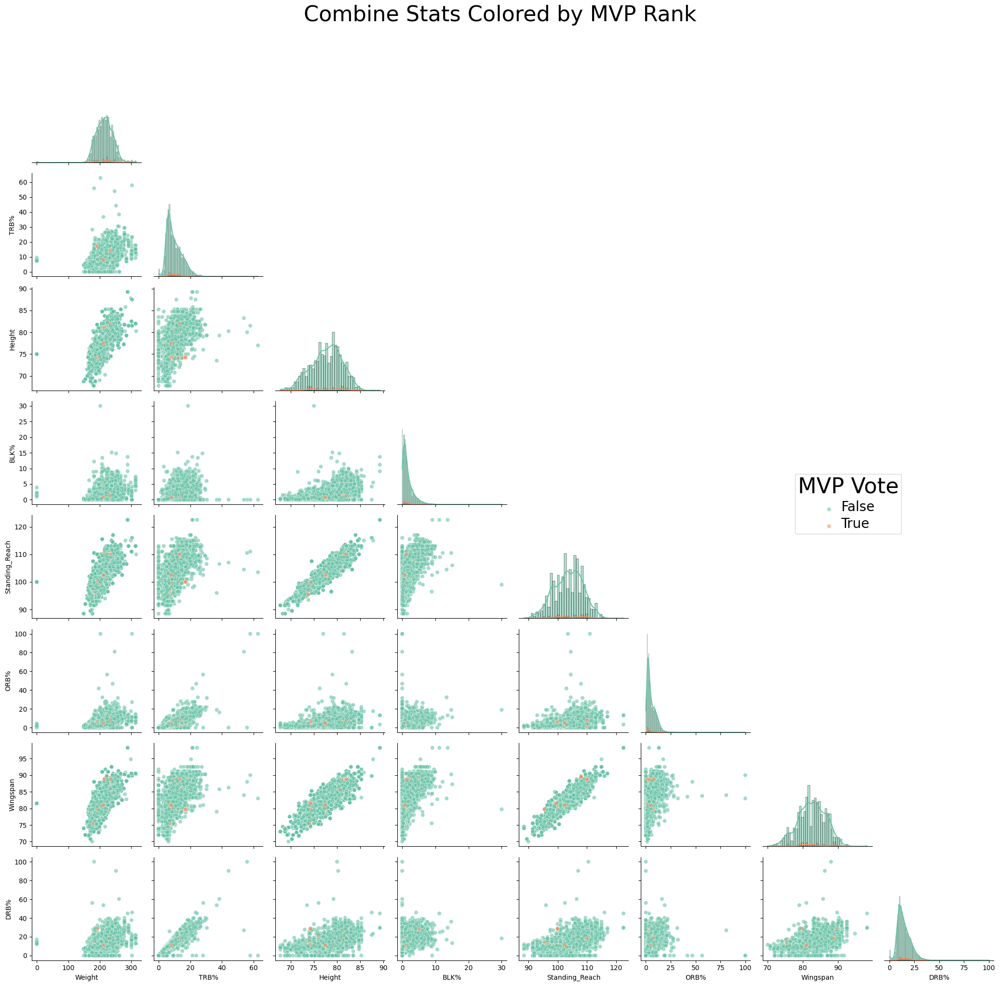

In [100]:
# Select combine stats + award
df_plot = combined_award.with_columns(
    (pl.col("MVP_Rank") > 0).alias("MVP_Vote")
)
df_plot = df_plot.filter(pl.col("MVP_Vote").is_not_null()).select(features_to_plot + ["MVP_Vote"]).to_pandas()

# Convert MVP_Rank to string for coloring
df_plot["MVP_Vote"] = df_plot["MVP_Vote"].astype(str)



# Create the PairGrid
g = sns.PairGrid(df_plot, vars=features_to_plot, hue="MVP_Vote", palette="Set2", corner=True)
g.map_lower(sns.scatterplot, alpha=0.6)
g.map_diag(sns.histplot, kde=True)
g.add_legend(title="MVP Vote")
if g.legend:
    g.legend.set_bbox_to_anchor((0.9, 0.5))
    g.legend.set_frame_on(True)
    g.legend.set_title("MVP Vote", prop={'size': 32})
    for text in g.legend.get_texts():
        text.set_fontsize(20)
plt.suptitle("Combine Stats Colored by MVP Rank", y=1.02, fontsize=32)
plt.tight_layout()
temp = visualization_path / "nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "PairGrid_Combine_Stats_by_MVP_Vote.png")
plt.show()

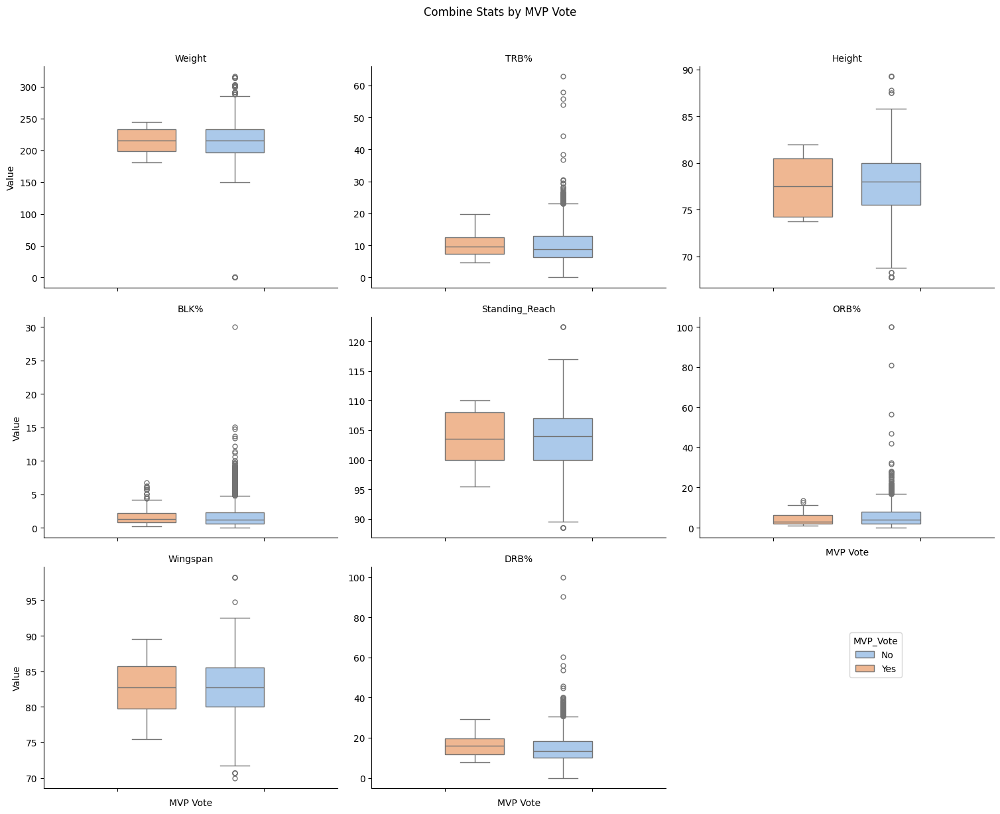

In [101]:

# Select combine stats + award
df_plot = combined_award.with_columns(
    (pl.col("MVP_Rank") > 0).alias("MVP_Vote")
)
df_plot = df_plot.filter(pl.col("MVP_Vote").is_not_null()).select(features_to_plot + ["MVP_Vote"]).to_pandas()

df_plot["MVP_Vote"] = df_plot["MVP_Vote"].map({True: "Yes", False: "No"})

# Melt to long format for faceting
df_melted = df_plot.melt(id_vars="MVP_Vote", var_name="Stat", value_name="Value")

g = sns.catplot(
    data=df_melted,
    x="MVP_Vote", y="Value",
    col="Stat", col_wrap=3,
    kind="box",
    order=["Yes", "No"],
    height=4,
    palette="pastel",
    legend=True,  # Disable legend for now
    dodge=True,  # Bars will be side-by-side instead of stacked
    aspect=1.2,  # Adjust aspect ratio for better spacing
    sharey=False,  
    sharex=False,
    fill=True,
    hue="MVP_Vote",  # Use hue to color by MVP_Vote
)

g.set_titles("{col_name}")
g.set_axis_labels("MVP Vote", "Value")
g.fig.suptitle("Combine Stats by MVP Vote", y=1.02)
# Remove x-tick labels to avoid clutter
if g.legend:
    g.legend.set_bbox_to_anchor((0.9, 0.2))
    g.legend.set_frame_on(True)
for ax in g.axes.flatten():
    ax.set_xticklabels([])

temp = visualization_path / "nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Combine_Stats_by_MVP_Vote.png")
plt.tight_layout()
plt.show()

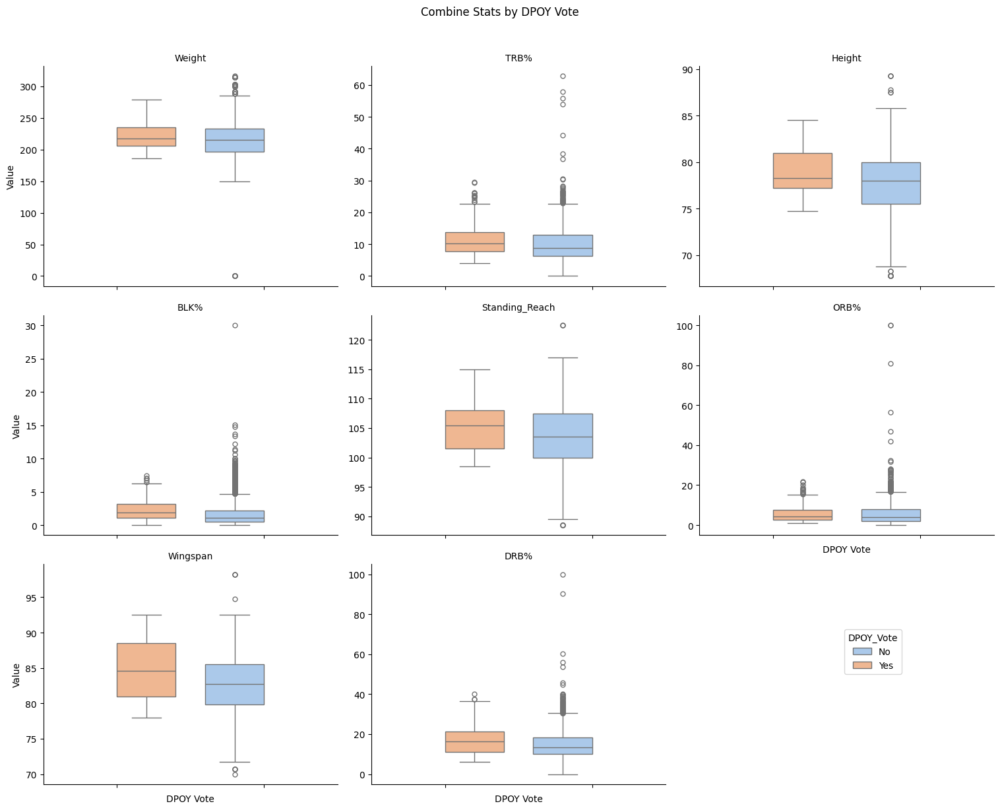

In [102]:
# Select combine stats + award
df_plot = combined_award.with_columns(
    (pl.col("DPOY_Rank") > 0).alias("DPOY_Vote")
)
df_plot = df_plot.filter(pl.col("DPOY_Vote").is_not_null()).select(features_to_plot + ["DPOY_Vote"]).to_pandas()

df_plot["DPOY_Vote"] = df_plot["DPOY_Vote"].map({True: "Yes", False: "No"})

# Melt to long format for faceting
df_melted = df_plot.melt(id_vars="DPOY_Vote", var_name="Stat", value_name="Value")

g = sns.catplot(
    data=df_melted,
    x="DPOY_Vote", y="Value",
    col="Stat", col_wrap=3,
    kind="box",
    order=["Yes", "No"],
    height=4,
    palette="pastel",
    legend=True,  # Disable legend for now
    dodge=True,  # Bars will be side-by-side instead of stacked
    aspect=1.2,  # Adjust aspect ratio for better spacing
    sharey=False,  
    sharex=False,
    fill=True,
    hue="DPOY_Vote",  # Use hue to color by DPOY_Vote
)

g.set_titles("{col_name}")
g.set_axis_labels("DPOY Vote", "Value")
g.fig.suptitle("Combine Stats by DPOY Vote", y=1.02)
if g.legend:
    g.legend.set_bbox_to_anchor((0.9, 0.2))
    g.legend.set_frame_on(True)
for ax in g.axes.flatten():
    ax.set_xticklabels([])
temp = visualization_path / "nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Combine_Stats_by_DPOY_Vote.png")
plt.tight_layout()
plt.show()

In [103]:
df_plot.describe()

,Weight,TRB%,Height,BLK%,Standing_Reach,ORB%,Wingspan,DRB%
count,5961.000000,5985.000000,5965.000000,5985.000000,5965.000000,5985.000000,5977.000000,5985.000000
mean,215.347504,10.012314,77.739693,1.669490,103.666199,5.375556,82.612358,14.654504
std,26.489700,4.919827,3.283775,1.666693,4.867866,4.743802,3.936244,6.510092
min,0.000000,0.000000,67.750000,0.000000,88.500000,0.000000,70.000000,0.000000
25%,197.000000,6.400000,75.500000,0.600000,100.000000,2.100000,80.000000,10.100000
50%,215.000000,8.800000,78.000000,1.200000,104.000000,3.900000,82.750000,13.400000
75%,233.000000,13.000000,80.000000,2.300000,107.500000,7.900000,85.500000,18.400000
max,316.000000,62.799999,89.250000,30.000000,122.500000,100.000000,98.250000,100.000000


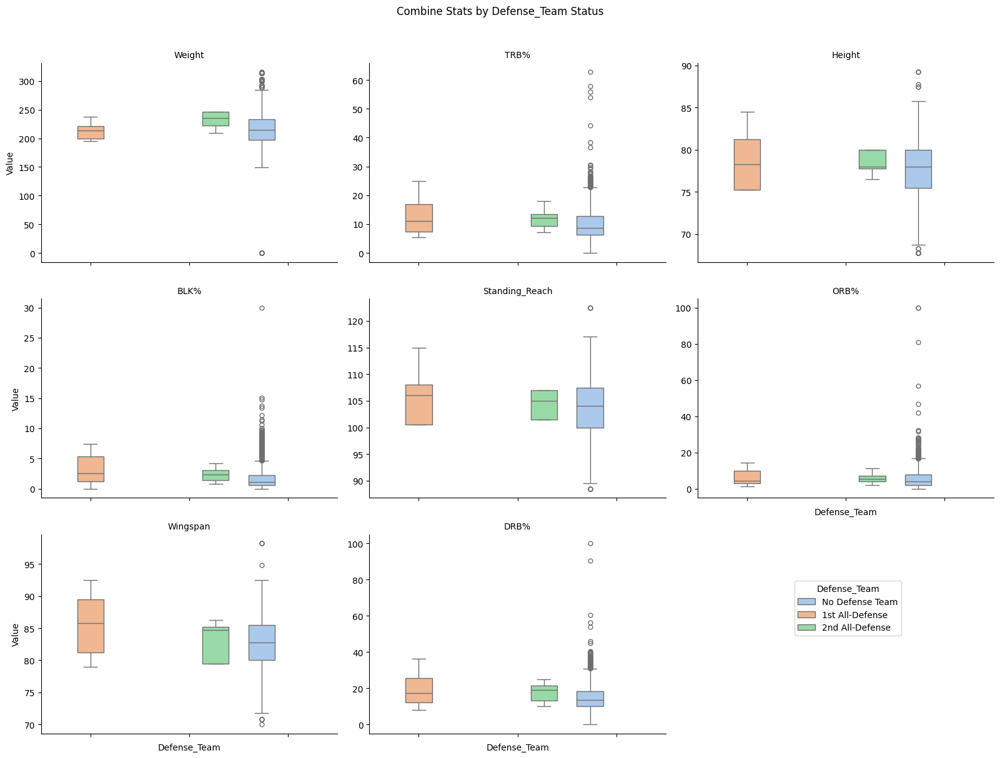

In [104]:
# Select combine stats and AllStar flag
df_plot = combined_award.select(features_to_plot + ["Defense_Team"]).to_pandas()
df_plot["Defense_Team"] = df_plot["Defense_Team"].map({0: "No Defense Team", 1: "1st All-Defense", 2: "2nd All-Defense"})

# Melt to long format for faceting
df_melted = df_plot.melt(id_vars="Defense_Team", var_name="Stat", value_name="Value")

g = sns.catplot(
    data=df_melted,
    x="Defense_Team", y="Value",
    col="Stat", col_wrap=3,
    kind="box",
    order=["1st All-Defense", "2nd All-Defense", "No Defense Team"],
    height=4, sharey=False,
    sharex=False,
    fill=True,
    palette="pastel",
    legend=True,  # Disable legend for now
    dodge=True,  # Bars will be side-by-side instead of stacked
    aspect=1.2,  # Adjust aspect ratio for better spacing
    hue="Defense_Team",  # Use hue to color by Defense_Team
)

g.set_titles("{col_name}")
g.set_axis_labels("Defense_Team", "Value")
g.fig.suptitle("Combine Stats by Defense_Team Status", y=1.02)
plt.tight_layout()
if g.legend:
    g.legend.set_bbox_to_anchor((0.9, 0.2))
    g.legend.set_frame_on(True)
for ax in g.axes.flatten():
    ax.set_xticklabels([])

temp = visualization_path / "nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Combine_Stats_by_Defense_Team.png")
plt.show()

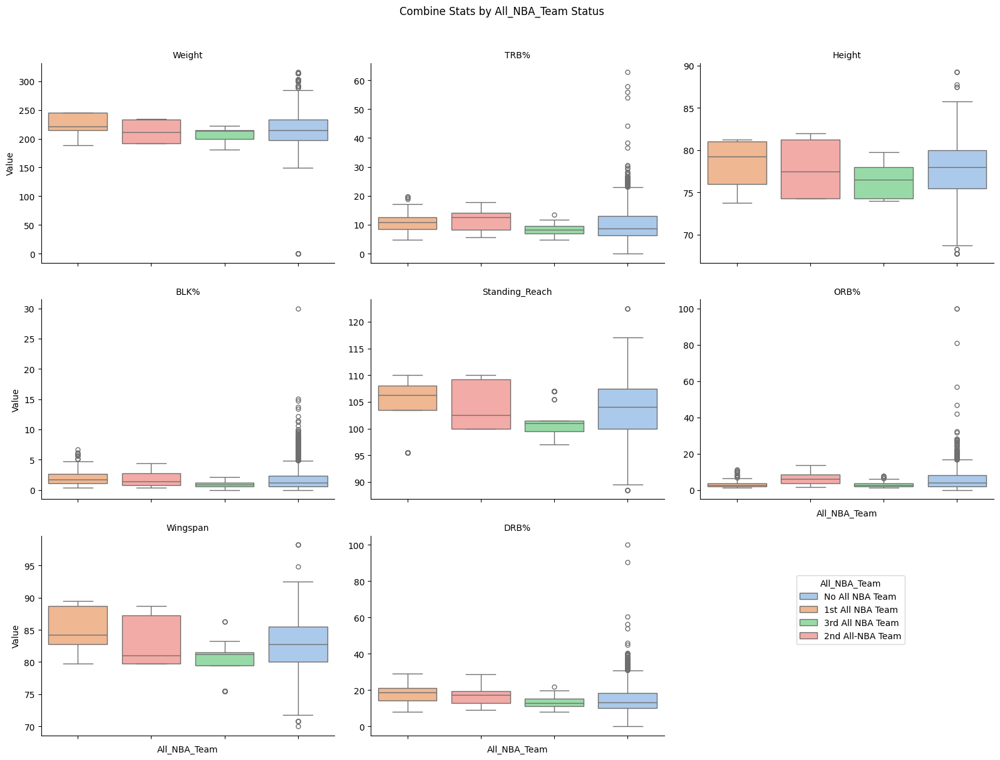

In [105]:
# Select combine stats and AllStar flag
df_plot = combined_award.select(features_to_plot + ["All_NBA_Team"]).to_pandas()
df_plot["All_NBA_Team"] = df_plot["All_NBA_Team"].map({0: "No All NBA Team", 1: "1st All NBA Team", 2: "2nd All-NBA Team", 3: "3rd All NBA Team"})

# Melt to long format for faceting
df_melted = df_plot.melt(id_vars="All_NBA_Team", var_name="Stat", value_name="Value")

g = sns.catplot(
    data=df_melted,
    x="All_NBA_Team", y="Value",
    col="Stat", col_wrap=3,
    kind="box",
    order=["1st All NBA Team", "2nd All-NBA Team", "3rd All NBA Team", "No All NBA Team"],
    height=4, sharey=False,
    sharex=False,
    fill=True,
    hue="All_NBA_Team",  # Use hue to color by All_NBA_Team
    legend=True,  # Enable legend
    aspect=1.2,  # Adjust aspect ratio for better spacing
    palette="pastel"
)

g.set_titles("{col_name}")
g.set_axis_labels("All_NBA_Team", "Value")
g.fig.suptitle("Combine Stats by All_NBA_Team Status", y=1.02)
if g.legend:
    g.legend.set_bbox_to_anchor((0.9, 0.2))
    g.legend.set_frame_on(True)
plt.tight_layout()
for ax in g.axes.flatten():
    ax.set_xticklabels([])

temp = visualization_path / "nba_awards"
temp.mkdir(parents=True, exist_ok=True)
# Save the figure
plt.savefig(temp / "Combine_Stats_by_All_NBA_Team.png")
plt.show()

## Summary of Findings

This notebook provides a comprehensive exploratory analysis of NBA Draft Combine data and its relationship with NBA performance and awards. Key findings include:

- **Data Coverage & Quality:** The dataset covers 1,677 NBA players across multiple seasons, but not all NBA players are represented. Some combine metrics have substantial missing values (e.g., Shuttle_Run, Hand measurements, Max_Bench_Press, Body_Fat), which may require imputation or exclusion for modeling.

- **Univariate Analysis:** Most physical and athletic metrics (e.g., Height, Wingspan, Standing Reach, Vertical Leap) display near-normal distributions and reasonable central tendency. Outliers and data quality issues are present in some features (e.g., BMI, Weight, Shuttle_Run), with minimum values of zero likely indicating errors.

- **Bivariate Analysis:** Strong correlations exist among physical attributes (Height, Wingspan, Standing Reach, Weight) and rebounding/blocking performance (TRB%, DRB%, ORB%, BLK%). Taller players with longer wingspans and greater standing reach tend to have higher rebound and block percentages.

- **Position & Season Trends:** Physical and performance metrics vary by position, with centers and power forwards generally exhibiting higher values in height, wingspan, and rebounding stats. Trends across seasons show some variation in combine attendance and metric averages.

- **Combine vs NBA Performance:** Several combine metrics are strongly correlated with NBA performance stats. For example, Height and Standing Reach are highly correlated with Defensive Rebound Percentage (DRB%), while Wingspan and Weight are linked to Total Rebound Percentage (TRB%) and Block Percentage (BLK%).

- **Physical Traits & NBA Awards:** Boxplots and pairplots reveal that players with above-median physical attributes (Height, Wingspan, Standing Reach) are more likely to achieve higher rebounding/blocking stats and receive NBA accolades such as All-Star selections, All-NBA Team, Defensive Team honors, and MVP/DPOY votes.

- **Visual Insights:** The analysis uses heatmaps, barplots, boxplots, and pairplots to highlight relationships between combine metrics, NBA stats, and awards, providing clear evidence that standout physical traits are associated with superior on-court performance and recognition.

**Conclusion:** Physical attributes measured at the NBA Draft Combine—especially Height, Wingspan, and Standing Reach—are strong predictors of rebounding and blocking success in the NBA and are associated with a higher likelihood of earning major awards. Data quality and missingness should be addressed for robust modeling, but the overall relationships are statistically and visually clear.

In [106]:
def data_quality_report(df: pl.DataFrame) -> pl.DataFrame:
    """
    Generate a data quality report for a polars DataFrame.
    Returns a DataFrame with columns: column, dtype, missing, missing_pct, outliers.
    Outliers are counted using the 1.5*IQR rule for numeric columns.
    """
    report = []
    n = len(df)

    for col in df.columns:
        series = df[col]
        dtype = series.dtype
        missing = series.is_null().sum()
        missing_pct = missing / n if n > 0 else None
        outliers = None

        if dtype in (pl.Float32, pl.Float64, pl.Int64, pl.Int32, pl.UInt32, pl.UInt64):
            vals = series.drop_nulls().to_numpy()
            if len(vals) > 0:
                q1 = np.percentile(vals, 25)
                q3 = np.percentile(vals, 75)
                iqr = q3 - q1
                lower = q1 - 1.5 * iqr
                upper = q3 + 1.5 * iqr
                outliers = ((vals < lower) | (vals > upper)).sum()

        report.append({
            "column": col,
            "dtype": str(dtype),
            "missing": missing,
            "missing_pct": missing_pct,
            "outliers": outliers
        })

    return pl.DataFrame(report)

In [107]:

df = data_quality_report(combined_wide)
df.pivot

<bound method DataFrame.pivot of shape: (66, 5)
┌─────────────────────┬─────────┬─────────┬─────────────┬──────────┐
│ column              ┆ dtype   ┆ missing ┆ missing_pct ┆ outliers │
│ ---                 ┆ ---     ┆ ---     ┆ ---         ┆ ---      │
│ str                 ┆ str     ┆ i64     ┆ f64         ┆ i64      │
╞═════════════════════╪═════════╪═════════╪═════════════╪══════════╡
│ FG%                 ┆ Float32 ┆ 25      ┆ 0.004176    ┆ 436      │
│ FT                  ┆ Float32 ┆ 0       ┆ 0.0         ┆ 568      │
│ ORB                 ┆ Float32 ┆ 0       ┆ 0.0         ┆ 526      │
│ eFG%                ┆ Float32 ┆ 25      ┆ 0.004176    ┆ 377      │
│ MP                  ┆ Float32 ┆ 0       ┆ 0.0         ┆ 0        │
│ …                   ┆ …       ┆ …       ┆ …           ┆ …        │
│ Length_x_Width_Hand ┆ Float32 ┆ 2857    ┆ 0.477201    ┆ 51       │
│ Shuttle_Run         ┆ Float32 ┆ 4327    ┆ 0.722733    ┆ 71       │
│ Weight              ┆ Float32 ┆ 26      ┆ 0.004343   